# Do all the plots for the manuscript
## Xiao Chen 260609
## chenxiaophd@gmail.com

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

%load_ext autoreload
%autoreload 2
%load_ext rpy2.ipython
    
import plot_utils as pu
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from IPython.display import Image, display

## Figure 1

In [ ]:
# all the interested maps
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
map_label = "rand_vec_MDD_GSR"
# lnm_left = os.path.join(work_dir, f"z_results_no_BDIcov/{map_label}_lh.gii")
# lnm_right = os.path.join(work_dir, f"z_results_no_BDIcov/{map_label}_rh.gii")

lnm_left = os.path.join(work_dir, f"z_results_new/{map_label}_lh.gii")
lnm_right = os.path.join(work_dir, f"z_results_new/{map_label}_rh.gii")
out_name = os.path.join(work_dir, f"plots/{map_label}.png")

pu.plot_surface_maps(
    left_gii=lnm_left,
    right_gii=lnm_right,
    out_file=out_name,
    colorbar_label="$t$ value",
    current_threshold=0.0000001,
)

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/data"

lnm_left = os.path.join(work_dir, "TargetAtlas_AnxDys.fsaverage5.L.10k_medialwall_nan.gii")
lnm_right = os.path.join(work_dir, "TargetAtlas_AnxDys.fsaverage5.R.10k_medialwall_nan.gii")
out_name = os.path.join("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/plots/Siddiqi_anxiety_dysphoric_circuit.png")

pu.plot_surface_maps(
    left_gii=lnm_left,
    right_gii=lnm_right,
    out_file=out_name,
    colorbar_label="$t$ value",
    current_threshold=0.0000001,
)

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
lnm_left = os.path.join(work_dir, "z_results_no_BDIcov/z_rumination_MDD_GSR_lh.gii")
lnm_right = os.path.join(work_dir, "thresholded_maps/positive_gt3p29_sig_clusters.func.gii")
out_name = os.path.join(work_dir, "plots/rumination_MDD_thresholded.png")

pu.plot_surface_maps_singlecol(
    left_gii=lnm_left,
    right_gii=lnm_right,
    out_file=out_name,
    colorbar_label="$t$ value",
    current_threshold=0.0001,
)

## single tumor lnm map, for flowchart

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/plots/flowchart_plots"

subj_id = "sub044"

lnm_left = os.path.join(work_dir, f"MDD_group_mean_{subj_id}_LH.func.gii")
lnm_right = os.path.join(work_dir, f"MDD_group_mean_{subj_id}_RH.func.gii")
out_name = os.path.join(work_dir, f"MDD_{subj_id}.png")

pu.plot_surface_maps(
    left_gii=lnm_left,
    right_gii=lnm_right,
    out_file=out_name,
    colorbar_label="FC value",
    current_threshold=0.0000001,
)

## radar plot showing dice results

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/overlap_analysis"
out_dir = '/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/plots'

pu.plot_radar(
    csv_file= os.path.join(work_dir,"network_dice.csv"),
    output_file=os.path.join(out_dir, "network_radar.png"),
    col1="Negative",
    col2="Positive",
    label1="Negative",
    label2="Positive",
    font_size=30,        # 网络名称字体大小（pt）
    figsize=(10, 10),      # 图片宽度和高度（英寸）
    legend_fontsize=30,  # 图例字体大小（pt）
    tick_fontsize=24     # 径向刻度字体大小（pt）
)

## plot gradient

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/plots"
g1_right = '/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/atlas/margulies2016_fcgradient01_fsLR_32k_rh_fsaverage10k.func.gii'
# g3_right = os.path.join(work_dir, 'margulies2016_fcgradient03_fsLR_32k_rh_fsaverage10k.func.gii')
out_name = os.path.join(work_dir, "gradient_1.png")

pu.plot_surface_maps_singlerow(
    right_gii=g1_right,
    out_file=out_name,
    current_threshold=0.0001,
)

## plot the spatial corr results

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
csv_file = os.path.join(work_dir, "spatial_corr/spatial_corr.csv")
out_png = os.path.join(work_dir, "plots/causal_mapping_gradient_barplot.png")
df = pd.read_csv(csv_file)

ro.r('source("plot_utilities.R")')
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df = ro.conversion.py2rpy(df)

plot_func = ro.globalenv["plot_correlation_bar"]
plot_func(
    r_df,
    out_png,
    y_label_fontsize=12,  # y 轴标题字体大小（pt）
    x_tick_fontsize=10,   # x 轴刻度标签字体大小（pt）
    y_tick_fontsize=10    # y 轴刻度标签字体大小（pt）
)
display(Image(filename=out_png))

## plot binned bar plots

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
df_bins = pd.read_csv(os.path.join(work_dir, 'spatial_corr/LNM_gradient_binned_long.csv'))
summary_df = pd.read_csv(os.path.join(work_dir, 'spatial_corr/LNM_gradient_binned_summary.csv'))
out_png = os.path.join(work_dir, "plots/LNM_gradient_binned_plot.png")

with localconverter(ro.default_converter + pandas2ri.converter):
    r_df_bins = ro.conversion.py2rpy(df_bins)
    r_summary_df = ro.conversion.py2rpy(summary_df)

ro.r('source("plot_utilities.R")') 

plot_func = ro.globalenv["plot_gradient_binned_from_summary"]

# call R function

plot_func(
    df_bins=r_df_bins,
    summary_df=r_summary_df,
    out_file=out_png,
    error="sd",
    xlab="Gradient 3"
)

display(Image(filename=out_png))

## plot the neurotransmitter results

In [ ]:
import matplotlib.pyplot as plt

nt_csv_dir = (
    "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/"
    "analyses/stable_260725/neuro_transmitter/nt_csv"
)
nt_map_dir = (
    "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/"
    "analyses/stable_260725/plots/neuro_transmitter_maps"
)
os.makedirs(nt_map_dir, exist_ok=True)

csv_files = sorted(glob.glob(os.path.join(nt_csv_dir, "*.csv")))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in: {nt_csv_dir}")

expected_parcel_ids = np.arange(201, 401)

for csv_file in csv_files:
    nt_df = pd.read_csv(csv_file)
    required_columns = {"parcel_id", "mean_value"}
    missing_columns = required_columns.difference(nt_df.columns)
    if missing_columns:
        raise ValueError(
            f"{os.path.basename(csv_file)} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    rh_df = (
        nt_df.loc[nt_df["parcel_id"].between(201, 400), ["parcel_id", "mean_value"]]
        .sort_values("parcel_id")
        .reset_index(drop=True)
    )
    if not np.array_equal(rh_df["parcel_id"].to_numpy(), expected_parcel_ids):
        raise ValueError(
            f"{os.path.basename(csv_file)} must contain each parcel_id "
            "from 201 through 400 exactly once."
        )

    rh_vector = rh_df["mean_value"].to_numpy(dtype=float).reshape(1, 200)
    # Set an independent color range from this map's finite RH parcel values.
    # Preserve the original values; exclude NaN and infinity from range estimation.
    finite_values = rh_vector[np.isfinite(rh_vector)]
    if finite_values.size == 0:
        print(f"Skipping {os.path.basename(csv_file)}: no finite RH values.")
        continue
    current_vmin = float(finite_values.min())
    current_vmax = float(finite_values.max())
    if current_vmin == current_vmax:
        # A constant map still needs a nonzero plotting range.
        padding = max(abs(current_vmin) * 0.01, 1e-6)
        current_vmin -= padding
        current_vmax += padding
    rh_vector = np.where(np.isfinite(rh_vector), rh_vector, np.nan)
    print(
        f"{os.path.basename(csv_file)}: "
        f"RH color range [{current_vmin:.6g}, {current_vmax:.6g}]"
    )

    csv_stem = os.path.splitext(os.path.basename(csv_file))[0]
    out_png = os.path.join(nt_map_dir, f"{csv_stem}_rh.png")

    pu.plot_surface_pacel_rh(
        parcel_vector=rh_vector,
        out_file=out_png,
        current_threshold=0.0001,
        current_cmap="YlOrBr",
        current_vmin=current_vmin,
        current_vmax=current_vmax,
    )
    plt.close("all")
    print(f"Saved: {out_png}")

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
csv_file = os.path.join(work_dir, "neuro_transmitter/LNM_neurotransmitter_spin_results.csv")
out_png = os.path.join(work_dir, "plots/LNM_neurotransmitter_barplot.png")

# -------------------------
# read dataframe
# -------------------------

df = pd.read_csv(csv_file)

# -------------------------
# load R functions
# -------------------------

ro.r('source("plot_utilities.R")')
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df = ro.conversion.py2rpy(df)

# -------------------------
# call plotting function
# -------------------------

plot_func = ro.globalenv["plot_nt_spin_bar"]
plot_func(
    df = r_df,
    out_file = out_png,
    top_n = ro.NULL,
    width_mm=220,
    height_mm=170,   # 图片高度（毫米）；如 150，ro.NULL 为自动计算
    x_label_fontsize=28,  # x 轴标题字体大小（pt）
    x_tick_fontsize=24,   # x 轴刻度标签字体大小（pt）
    y_tick_fontsize=24    # y 轴刻度标签字体大小（pt）
)

# -------------------------
# show figure
# -------------------------

display(Image(filename=out_png))

## plot the cell type results

In [ ]:
# Plot cell-type correlations; * indicates spin p < 0.05, ** also requires FDR p < 0.05.
from pathlib import Path
import numpy as np
import pandas as pd
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from IPython.display import Image, display

project_root = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
analysis_dir = project_root / "analyses/stable_260725"
csv_file = analysis_dir / "cell_types/LNM_cell_type_spin_results.csv"
out_png = analysis_dir / "plots/LNM_cell_type_barplot.png"
out_png.parent.mkdir(parents=True, exist_ok=True)

cell_df = pd.read_csv(csv_file)
required_columns = {"cell_type", "r_obs", "p_spin", "p_fdr"}
if not required_columns.issubset(cell_df.columns):
    raise ValueError(f"Missing columns: {sorted(required_columns - set(cell_df.columns))}")
if cell_df["cell_type"].isna().any() or not cell_df["cell_type"].is_unique:
    raise ValueError("Cell-type labels must be non-missing and unique.")
if not np.isfinite(cell_df[["r_obs", "p_spin", "p_fdr"]].to_numpy(dtype=float)).all():
    raise ValueError("Inspect missing correlation or FDR results before plotting.")

# Adapt the result columns to the R function without recalculating statistics.
plot_df = cell_df.rename(columns={"cell_type": "label"})[
    ["label", "r_obs", "p_spin", "p_fdr"]
].copy()

ro.r["source"](str(project_root / "scripts/plot_utilities.R"))
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df = ro.conversion.py2rpy(plot_df)

# Use Cairo when available to render Arial reliably on macOS.
ro.r('if (capabilities("cairo")) options(bitmapType = "cairo")')
plot_func = ro.globalenv["plot_nt_spin_bar"]
plot_func(
    df=r_df,
    out_file=str(out_png),
    top_n=ro.NULL,
    bar_color="#FF9D50",
    width_mm=220,
    height_mm=200,   # 图片高度（毫米）；如 150，ro.NULL 为自动计算
    x_label_fontsize=28,  # x 轴标题字体大小（pt）
    x_tick_fontsize=24,   # x 轴刻度标签字体大小（pt）
    y_tick_fontsize=24,   # y 轴刻度标签字体大小（pt）
)
display(Image(filename=str(out_png)))
print(f"Saved: {out_png}")


In [ ]:
# Plot right-hemisphere cell-type expression in medial and lateral views.
from pathlib import Path
import csv
import importlib.util
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from IPython.display import Image, display

project_root = Path('/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping')
expression_csv = project_root / 'analyses/stable_260725/cell_types/schaeffer_Jorstad_400_7Net_expr_mat_new_NormZscore0.3.csv'
label_gii = project_root / 'atlas/fsaverage5_rh_Schaefer2018_400Parcels_7Networks_order.label.gii'
plots_dir = project_root / 'analyses/stable_260725/plots'
plots_dir.mkdir(parents=True, exist_ok=True)

# Load the requested plotting utility by its absolute path.
spec = importlib.util.spec_from_file_location('cell_type_plot_utils', project_root / 'scripts/plot_utils.py')
cell_type_pu = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cell_type_pu)

# Align expression columns to the exact right-hemisphere label IDs 1–200.
label_img = nib.load(label_gii)
labels = label_img.darrays[0].data
assert np.array_equal(np.unique(labels), np.arange(201))
label_table = {int(item.key): getattr(item, 'label', '') for item in label_img.labeltable.labels}
rh_names = [label_table[i] for i in range(1, 201)]
assert len(set(rh_names)) == 200
assert all(name.startswith('7Networks_RH_') for name in rh_names)
with expression_csv.open(newline='') as f:
    headers = next(csv.reader(f))
assert len(headers) == 401 and len(set(headers[:400])) == 400
expression_df = pd.read_csv(expression_csv, nrows=24)
cell_label_column = expression_df.columns[-1]
assert expression_df[cell_label_column].notna().all()
assert expression_df[cell_label_column].is_unique
expression_df = expression_df.set_index(cell_label_column)
assert set(rh_names).issubset(expression_df.columns)

# Preserve zero expression and missing values; do not fill missing parcels with zero.
cell_type_cmaps = {
    'L4 IT': 'Blues',
    'L6b': 'Reds',
    'Sst Chodl': 'Greens',
}
for cell_type, cmap in cell_type_cmaps.items():
    rh_vector = pd.to_numeric(expression_df.loc[cell_type, rh_names], errors='raise').to_numpy(dtype=float)
    assert rh_vector.shape == (200,)
    assert not np.isinf(rh_vector).any() and np.isfinite(rh_vector).any()
    out_png = plots_dir / f'{cell_type.replace(" ", "_")}_Schaefer400_expression_rh.png'
    cell_type_pu.plot_surface_pacel_rh(
        parcel_vector=rh_vector,
        out_file=str(out_png),
        label_gii=str(label_gii),
        current_threshold=0.0001,
        current_cmap=cmap,
        # Map low expression to near-white and high expression to dark color.
        current_vmin=0.0,
        current_vmax=float(np.nanmax(rh_vector)),
    )
    plt.close('all')
    display(Image(filename=str(out_png)))
    print(f'{cell_type}: {np.isfinite(rh_vector).sum()}/200 finite parcels; saved {out_png}')


## gene expression analyses

In [ ]:
# PLS1–LNM scatter: Spearman rho and the previously computed spatial-rotation p.
from pathlib import Path
import shutil
import subprocess
from IPython.display import Image, display

project_dir = Path('/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping')
out_png = project_dir / 'analyses/stable_260725/plots/PLS1_LNM_spearman_scatter.png'
rscript = shutil.which('Rscript')
if rscript is None:
    raise FileNotFoundError('Rscript is required to call plot_corr_txt_1group.')

r_code = r'''
project_dir <- commandArgs(trailingOnly = TRUE)[1]
source(file.path(project_dir, "scripts/plot_utilities.R"))
gene_dir <- file.path(project_dir, "analyses/stable_260725/gene_expression")
pls_df <- read.csv(file.path(gene_dir, "PLS_component1_score.csv"))
lnm_df <- read.csv(file.path(gene_dir, "rum_MDD_lnm_vec_left_schaefer400.csv"))
if (!all(c("parcel", "score") %in% names(pls_df)) ||
    nrow(pls_df) != 200L || anyNA(pls_df$parcel) ||
    anyDuplicated(pls_df$parcel) || !setequal(pls_df$parcel, 1:200) ||
    nrow(lnm_df) != 200L || !"LNM" %in% names(lnm_df)) {
  stop("Expected unique PLS parcel IDs 1–200 and 200 LNM rows in parcel order.")
}
# The LNM CSV has no parcel column: its rows correspond to IDs 1–200.
pls_df <- pls_df[match(1:200, pls_df$parcel), ]
pairs <- data.frame(x = pls_df$score, y = lnm_df$LNM)
pairs <- pairs[is.finite(pairs$x) & is.finite(pairs$y), ]
if (nrow(pairs) < 3L || sd(pairs$x) == 0 || sd(pairs$y) == 0) {
  stop("At least three finite pairs with nonzero variance are required.")
}
rho <- cor(pairs$x, pairs$y, method = "spearman")

# Use the spin p from gene_expression_analyses.Rmd, not cor.test's ordinary p.
summary_file <- file.path(gene_dir, "PLS1_spatial_summary.csv")
if (!file.exists(summary_file)) {
  stop("Run the PLS1 spatial-rotation chunks in gene_expression_analyses.Rmd first.")
}
stats <- read.csv(summary_file)
required <- c("component", "n_parcels", "rho", "p_spin", "correlation_method",
              "alternative", "spin_test", "n_spin")
if (!all(required %in% names(stats)) || nrow(stats) != 1L || anyNA(stats[, required]) ||
    stats$component != 1L || stats$correlation_method != "spearman" ||
    stats$alternative != "two.sided" || stats$spin_test != "fixed_score_map" ||
    stats$n_parcels != nrow(pairs) || !is.finite(stats$rho) ||
    abs(stats$rho - rho) > 1e-8) {
  stop("PLS1 spatial summary does not match these maps; rerun the spatial analysis.")
}

out_png <- file.path(project_dir, "analyses/stable_260725/plots/PLS1_LNM_spearman_scatter.png")
dir.create(dirname(out_png), recursive = TRUE, showWarnings = FALSE)
pair_file <- tempfile(fileext = ".txt")
write.table(pairs, pair_file, row.names = FALSE, col.names = FALSE, quote = FALSE)
if (capabilities("cairo")) options(bitmapType = "cairo")
p <- plot_corr_txt_1group(
  txt_file = pair_file, out_file = out_png,
  xlab = "PLS component 1 score", ylab = "LNM value",
  point_color = "#0D47A1", method = "spearman", p_spin = stats$p_spin
)
unlink(pair_file)
cat(sprintf("n = %d; Spearman's rho = %.6f; P_spin = %.6g (%d rotations)\n",
            nrow(pairs), rho, stats$p_spin, stats$n_spin))
'''

result = subprocess.run(
    [rscript, '--vanilla', '-', str(project_dir)],
    input=r_code, text=True, capture_output=True,
)
if result.returncode != 0:
    raise RuntimeError(f'PLS1 scatter plotting failed:\n{result.stderr}\n{result.stdout}')
print(result.stdout.strip())
print(f'Saved: {out_png}')
display(Image(filename=str(out_png), width=750))


In [ ]:
# Plot the left-hemisphere PLS component 1 parcel scores.
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725"
pls_score_file = os.path.join(
    work_dir,
    "gene_expression/PLS_component1_score.csv",
)
out_png = os.path.join(
    work_dir,
    "gene_expression/PLS_component1_score_lh.png",
)

pls_score_df = pd.read_csv(pls_score_file)
required_columns = {"parcel", "score"}
missing_columns = required_columns.difference(pls_score_df.columns)
if missing_columns:
    raise ValueError(
        f"Missing required columns in PLS score CSV: {sorted(missing_columns)}"
    )

pls_score_df = pls_score_df.sort_values("parcel").reset_index(drop=True)
if not np.array_equal(pls_score_df["parcel"].to_numpy(), np.arange(1, 201)):
    raise ValueError("PLS score CSV must contain each parcel from 1 through 200 once.")

pls_component1_score = pls_score_df["score"].to_numpy().reshape(1, 200)
pu.plot_surface_pacel_lh(
    parcel_vector=pls_component1_score,
    out_file=out_png,
    current_threshold=None,
)

display(Image(filename=out_png))

## plot the word cloud

In [ ]:
from pathlib import Path
import pandas as pd
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from IPython.display import Image, display

project_root = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
plots_dir = project_root / "analyses/stable_260725/plots"
plots_dir.mkdir(parents=True, exist_ok=True)
clusters = [
    ("positive_gt3p29_cluster1_n69_mask_xc", "#90CAF9", "#0D47A1"),
    ("positive_gt3p29_cluster2_n50_mask_xc", "#A5D6A7", "#1B5E20"),
    ("positive_gt3p29_cluster3_n33_mask_xc", "#F9B637", "#E73F1E"),
]

ro.r["source"](str(project_root / "scripts/plot_utilities.R"))
plot_word_cloud = ro.globalenv["plot_word_cloud"]
for cluster, low_color, high_color in clusters:
    decoder_xlsx = (
        project_root / "analyses/stable_260725/decode"
        / f"neurosynth_decoder_top50_{cluster}.xlsx"
    )
    decoder_df = pd.read_excel(decoder_xlsx)
    out_png = plots_dir / f"word_cloud_{cluster}.png"
    with localconverter(ro.default_converter + pandas2ri.converter):
        r_decoder_df = ro.conversion.py2rpy(decoder_df)
    # Select the top 30 correlations; enlarge all original font sizes by 50%.
    plot_word_cloud(
        r_decoder_df, out_file=str(out_png), width=16, height=15,
        top_n=30, size_multiplier=1.5,
        low_color=low_color, high_color=high_color,
    )
    display(Image(filename=str(out_png)))


## plot the dot line plots for the RST dataset

In [ ]:
work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/regional_metrics"

metric_set = [
    "ALFF_FunSurfWC", "ALFF_FunSurfWglobalC",
    "fALFF_FunSurfWC", "fALFF_FunSurfWglobalC",
    "DegreeCentrality_FunSurfWCF", "DegreeCentrality_FunSurfWglobalCF",
    "ReHo_FunSurfWCF", "ReHo_FunSurfWglobalCF"
]

cluster_set = ["cluster1", "cluster2", "cluster3"]

# Axis appearance: font sizes are in points (pt).
x_tick_label_size = 14  # x-tick labels: Rum. / Dis.
y_tick_label_size = 14  # y-tick numbers
x_axis_label_size = 16  # x-axis title
y_axis_label_size = 16  # y-axis title
group_label_size = 16  # bottom MDD / HC labels (pt)
x_axis_label = ""      # e.g. "Condition"; empty string hides the title
# Edit the title for each metric here.
y_axis_labels = {
    "ALFF": "ALFF",
    "fALFF": "fALFF",
    "DegreeCentrality": "DegreeCentrality",
    "ReHo": ro.r('expression("ReHo (" * italic(z) * ")")'),
}

project_root = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping"
ro.r["source"](os.path.join(project_root, "scripts/plot_utilities.R"))
plot_func = ro.globalenv["plot_two_group_paired"]


for metric in metric_set:
    for cluster in cluster_set:

        csv_file = os.path.join(work_dir, "roi_signal_organized", f"{metric}_{cluster}.csv")
        stats_file = os.path.join(work_dir, f"stats_{metric}_{cluster}.csv")
        out_png = os.path.join(work_dir, f"{metric}_{cluster}.png")

        df = pd.read_csv(csv_file)
        df["group"] = df["group"].astype(str).str.strip()
        df["condition"] = df["condition"].astype(str).str.strip()
        df_list = []
        
        for g, gdf in df.groupby("group", sort=False):
            n_condition = gdf["condition"].nunique()
            n_subj = len(gdf) // n_condition
            gdf = gdf.sort_values("condition").copy()
            gdf["subj_id"] = np.tile(np.arange(1, n_subj + 1), n_condition)
            df_list.append(gdf)

        df = pd.concat(df_list, axis=0).reset_index(drop=True)
        stats_df = pd.read_csv(stats_file)
        stats_df["group"] = stats_df["group"].astype(str).str.strip()

        n_tests = len(cluster_set)
        stats_df["p_bonf"] = np.minimum(stats_df["p"] * n_tests, 1.0)

        stats_df["label"] = np.where(
            stats_df["p_bonf"] < 0.05,
            "**",
            np.where(stats_df["p"] < 0.05, "*", "")
        )

        ymax = df["metric"].max()
        ymin = df["metric"].min()
        yrange = ymax - ymin

        if yrange == 0:
            yrange = abs(ymax) if ymax != 0 else 1

        y_base = ymax + 0.12 * yrange

        sig_rows = []

        for _, row in stats_df.iterrows():
            if row["label"] == "":
                continue

            g = row["group"]

            if g == "MDD":
                xmin, xmax = 1, 2
            elif g == "HC":
                xmin, xmax = 3.2, 4.2
            else:
                continue

            sig_rows.append({
                "xmin": xmin,
                "xmax": xmax,
                "y.position": y_base,
                "tip.length": 0.025 * yrange,
                "text.offset": 0.035 * yrange,
                "label": row["label"]
            })

        sig_df = pd.DataFrame(
            sig_rows,
            columns=[
                "xmin",
                "xmax",
                "y.position",
                "tip.length",
                "text.offset",
                "label"
            ]
        )

        print("\n", metric, cluster)
        print(stats_df[["group", "p", "p_bonf", "label"]])
        print(sig_df)

        with localconverter(ro.default_converter + pandas2ri.converter):
            r_df = ro.conversion.py2rpy(df)

        with localconverter(ro.default_converter + pandas2ri.converter):
            r_sig_df = ro.conversion.py2rpy(sig_df)

        plot_func(
            df=r_df,
            xlab=x_axis_label,
            ylab=y_axis_labels.get(metric.split("_")[0], metric.split("_")[0]),
            x_tick_label_size=x_tick_label_size,
            y_tick_label_size=y_tick_label_size,
            x_axis_label_size=x_axis_label_size,
            y_axis_label_size=y_axis_label_size,
            group_label_size=group_label_size,
            value_col="metric",
            condition_col="condition",
            subject_col="subj_id",
            group_col="group",
            error="sd",
            sig_df=r_sig_df,
            width=3,
            height=3.8,
            jitter_width=0.15,
            out_file=out_png
        )

        print(f"Saved: {out_png}")

## Beijing dataset

In [ ]:
import os
import numpy as np
import pandas as pd

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter


work_dir = "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/regional_metrics_Beijing"
metric_set = [
    "ALFF_FunSurfWC", "ALFF_FunSurfWglobalC",
    "fALFF_FunSurfWC", "fALFF_FunSurfWglobalC",
    "DegreeCentrality_FunSurfWCF", "DegreeCentrality_FunSurfWglobalCF",
    "ReHo_FunSurfWCF", "ReHo_FunSurfWglobalCF"]

cluster_set = ["cluster1", "cluster2", "cluster3"]
group_set = ["IPCAS", "PKUGE", "PKUSIEMENS"]
x_pos_dict = {"IPCAS": (1, 2), "PKUGE": (3.2, 4.2),  "PKUSIEMENS": (5.4, 6.4)}

ro.r('source("plot_utilities.R")')
plot_func = ro.globalenv["plot_three_group_paired"]

for metric in metric_set:
    for cluster in cluster_set:

        csv_file = os.path.join(work_dir, "roi_signal_organized", f"{metric}_{cluster}.csv")
        stats_file = os.path.join(work_dir, f"stats_{metric}_{cluster}.csv")
        out_png = os.path.join(work_dir,f"{metric}_{cluster}.png")
        
        df = pd.read_csv(csv_file)
        df["group"] = df["group"].astype(str).str.strip()
        df["condition"] = df["condition"].astype(str).str.strip()
        
        # 关键修改：把 1/2/3 映射成组名
        df["group"] = df["group"].replace({
            "1": "IPCAS",
            "2": "PKUGE",
            "3": "PKUSIEMENS"
        })
        
        df = df[df["group"].isin(group_set)].copy()
        df["group"] = pd.Categorical(
            df["group"],
            categories=group_set,
            ordered=True
        )
        
        df_list = []
        for g, gdf in df.groupby("group", sort=False, observed=True):
            n_condition = gdf["condition"].nunique()
            n_subj = len(gdf) // n_condition
            gdf = gdf.sort_values("condition").copy()
            gdf["subj_id"] = np.tile(
                np.arange(1, n_subj + 1),
                n_condition
            )
        
            df_list.append(gdf)
        
        df = pd.concat(df_list, axis=0).reset_index(drop=True)
        stats_df = pd.read_csv(stats_file)
        stats_df["group"] = stats_df["group"].astype(str).str.strip()
        stats_df = stats_df[stats_df["group"].isin(group_set)].copy()
        
        # Bonferroni correction: still multiply by 2
        n_test = len(cluster_set)
        stats_df["p_bonf"] = np.minimum(stats_df["p"] * n_test, 1.0)
        stats_df["label"] = np.where(
            stats_df["p_bonf"] < 0.05,
            "**",
            np.where(stats_df["p"] < 0.05, "*", "")
        )
        
        ymax = df["metric"].max()
        ymin = df["metric"].min()
        yrange = ymax - ymin
        
        if yrange == 0:
            yrange = abs(ymax) if ymax != 0 else 1
        
        y_base = ymax + 0.12 * yrange
        sig_rows = []
        
        for _, row in stats_df.iterrows():
            if row["label"] == "":
                continue
            g = row["group"]
            if g not in x_pos_dict:
                continue
            xmin, xmax = x_pos_dict[g]
            sig_rows.append({
                "xmin": xmin,
                "xmax": xmax,
                "y.position": y_base,
                "tip.length": 0.025 * yrange,
                "text.offset": 0.035 * yrange,
                "label": row["label"]
            })
        
        sig_df = pd.DataFrame(
            sig_rows,
            columns=[
                "xmin",
                "xmax",
                "y.position",
                "tip.length",
                "text.offset",
                "label"
            ]
        )
        
        print("\n", metric, cluster)
        print(stats_df[["group", "p", "p_bonf", "label"]])
        print(sig_df)
        
        with localconverter(ro.default_converter + pandas2ri.converter):
            r_df = ro.conversion.py2rpy(df)
        
        with localconverter(ro.default_converter + pandas2ri.converter):
            r_sig_df = ro.conversion.py2rpy(sig_df)
        
        plot_func(
            df=r_df,
            ylab=metric.split("_")[0],
            value_col="metric",
            condition_col="condition",
            subject_col="subj_id",
            group_col="group",
            error="sd",
            sig_df=r_sig_df,
            width=4.5,
            height=3.8,
            jitter_width=0.15,
            out_file=out_png
        )
        
        print(f"Saved: {out_png}")

## scatter plot

In [ ]:
from pathlib import Path
import pandas as pd

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects import NULL

work_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
txt_dir = work_dir / "analyses/stable_260725/regional_metrics/stats_rois/txt_ReHo_FunSurfWglobalCF"
plot_utilities_file = work_dir / "scripts/plot_utilities.R"
# Axis titles: None keeps the x title inferred from each filename.
x_lab_current = None  # e.g. "Rumination score"
x_axis_label_size = 36  # pt
y_axis_label_size = 36  # pt
x_tick_label_size = 30  # pt
y_tick_label_size = 30  # pt
stats_label_size = 30   # r / p annotation above the plotting panel (pt)
y_lab_current = ro.r('expression("ReHo (" * italic(z) * ")")')
p_adjust_factor_current = 3  # Manually adjust the multiple-testing factor here

ro.r["source"](str(plot_utilities_file))
plot_func = ro.globalenv["plot_corr_txt"]
txt_files = sorted(txt_dir.glob("*.txt"))

if not txt_files:
    raise FileNotFoundError(f"No .txt files found in {txt_dir}")

for txt_file in txt_files:
    x_lab = txt_file.stem.rsplit("_", 1)[-1]
    df = pd.read_csv(txt_file, sep=r"\s+", header=None).iloc[:, :3]
    df.columns = ["x_vec", "y_vec", "Groups"]

    with localconverter(ro.default_converter + pandas2ri.converter):
        r_df = ro.conversion.py2rpy(df)

    out_png = txt_file.with_suffix(".png")
    plot_func(
        df=r_df,
        out_file=str(out_png),
        title=NULL,
        xlab=x_lab if x_lab_current is None else x_lab_current,
        ylab=y_lab_current,
        x_axis_label_size=x_axis_label_size,
        y_axis_label_size=y_axis_label_size,
        x_tick_label_size=x_tick_label_size,
        y_tick_label_size=y_tick_label_size,
        stats_label_size=stats_label_size,
        p_adjust_factor=p_adjust_factor_current
    )
    print(f"Saved: {out_png.name}")

print(f"Finished: {len(txt_files)} plots saved to {txt_dir}")

## loop across the Beijing dataset

In [ ]:
from pathlib import Path
import rpy2.robjects as ro

metric_current = "ReHo"
work_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
stats_rois_dir = work_dir / f"analyses/stable_260725/regional_metrics_Beijing/stats_rois/txt_{metric_current}_FunSurfWglobalCF"
y_lab_current = ro.r('expression("ReHo (" * italic(z) * ")")')
plot_utilities_file = work_dir / "scripts/plot_utilities.R"

ro.r["source"](str(plot_utilities_file))
plot_func = ro.globalenv["plot_corr_txt_1group"]
txt_files = sorted(stats_rois_dir.glob("*.txt"))

if not txt_files:
    raise FileNotFoundError(f"No .txt files found in {stats_rois_dir}")

for txt_file in txt_files:
    x_lab = txt_file.stem.rsplit("_", 1)[-1]
    if x_lab == "total":
        x_lab = "Rumination"
    out_png = txt_file.with_suffix(".png")
    plot_func(
        txt_file=str(txt_file),
        out_file=str(out_png),
        xlab=x_lab,
        ylab=y_lab_current
    )
    print(f"Saved: {out_png.name}")

print(f"Finished: {len(txt_files)} plots saved to {stats_rois_dir}")

## plot seeg channels

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
import numpy as np
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from nilearn import datasets, surface, plotting

plt.rcParams["font.family"] = "Arial"
legend_fontsize = 24  # Adjust legend text size here.
stat_alpha = 0.45  # Statistical surface opacity: 0 (invisible) to 1 (opaque).
stat_cmap = "seismic"
colorbar_label = r"$t$ Value"
colorbar_label_fontsize = 24
colorbar_tick_fontsize = 16
stat_file = Path(
    "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/"
    "stable_260725/z_results_no_BDIcov/z_rumination_MDD_rh.gii"
)
stat_file_left = stat_file.with_name("z_rumination_MDD_lh.gii")
roi_labels = {"2027": "aVLPFC", "2018": "pVLPFC", "2031": "TPJ"}

electrode_dir = Path(
    "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/seeg"
)
roi_colors = {
    "2027": "#0D47A1",
    "2018": "#1B5E20",
    "2031": "#E73F1E",
}
electrode_tables = []
for roi in roi_colors:
    electrode_file = electrode_dir / f"all_ROI_{roi}_electrodes.csv"
    roi_electrodes = pd.read_csv(electrode_file)
    required_columns = {"x", "y", "z"}
    missing_columns = required_columns.difference(roi_electrodes.columns)
    if missing_columns:
        raise ValueError(
            f"{electrode_file.name}: Missing required columns: {sorted(missing_columns)}"
        )
    roi_electrodes = roi_electrodes.dropna(subset=["x", "y", "z"]).copy()
    roi_electrodes["source_roi"] = roi
    electrode_tables.append(roi_electrodes)
electrodes = pd.concat(electrode_tables, ignore_index=True)

figure = plt.figure(figsize=(9, 5))
brain_displays = [
    plotting.plot_glass_brain(
        None,
        display_mode=view,
        figure=figure,
        axes=bounds,
        colorbar=False,
        black_bg=False,
    )
    for view, bounds in [
        ("r", (0.02, 0.14, 0.46, 0.72)),
        ("z", (0.50, 0.14, 0.38, 0.72)),
    ]
]

# Project the fsaverage5 pial surface into the same coordinates as the glass brain.
# This is a template-space visualization, not a subject-specific registration.
fsaverage = datasets.fetch_surf_fsaverage(mesh="fsaverage5")
hemisphere_data = {}
for hemisphere, mesh_file, value_file in [
    ("right", fsaverage.pial_right, stat_file),
    ("left", fsaverage.pial_left, stat_file_left),
]:
    mesh = surface.load_surf_mesh(mesh_file)
    values = np.asarray(surface.load_surf_data(str(value_file))).squeeze()
    if values.shape != (len(mesh.coordinates),):
        raise ValueError(f"Statistical map must match the fsaverage5 {hemisphere} surface.")
    if not np.isfinite(values).any():
        raise ValueError(f"No finite statistical values in {value_file}.")
    hemisphere_data[hemisphere] = (mesh, values)
if not 0 <= stat_alpha <= 1:
    raise ValueError("stat_alpha must lie between 0 and 1.")
# Both hemispheres share a symmetric color scale.
stat_limit = max(float(np.nanmax(np.abs(values)))
                 for mesh, values in hemisphere_data.values())
stat_norm = Normalize(vmin=-stat_limit, vmax=stat_limit)
for brain_display, view, dims, depth in [
    (brain_displays[0], "r", (1, 2), 0),
    (brain_displays[1], "z", (0, 1), 2),
]:
    # Right lateral view shows the right hemisphere; top view shows both.
    hemispheres = ["right"] if view == "r" else ["left", "right"]
    triangles = np.concatenate([
        hemisphere_data[h][0].coordinates[hemisphere_data[h][0].faces]
        for h in hemispheres
    ])
    face_values = np.concatenate([
        np.mean(hemisphere_data[h][1][hemisphere_data[h][0].faces], axis=1)
        for h in hemispheres
    ])
    face_normals = np.cross(triangles[:, 1] - triangles[:, 0],
                            triangles[:, 2] - triangles[:, 0])
    # Keep outward-facing triangles and paint far-to-near.
    visible = np.flatnonzero((face_normals[:, depth] > 0) & np.isfinite(face_values))
    order = visible[np.argsort(triangles[visible, :, depth].mean(axis=1))]
    overlay = PolyCollection(
        triangles[order][:, :, dims],
        facecolors=plt.get_cmap(stat_cmap)(stat_norm(face_values[order])),
        edgecolors="none", linewidths=0, antialiaseds=False,
        alpha=1.0, rasterized=True,
    )
    # Render visible surface first, then apply opacity once to avoid
    # accumulating opacity where projected cortical folds overlap.
    target_ax = brain_display.axes[view].ax
    xlim, ylim = target_ax.get_xlim(), target_ax.get_ylim()
    layer_fig = plt.figure(figsize=(5, 5), dpi=240)
    layer_ax = layer_fig.add_axes([0, 0, 1, 1])
    layer_ax.add_collection(overlay)
    layer_ax.set(xlim=xlim, ylim=ylim)
    layer_ax.set_axis_off()
    layer_fig.patch.set_alpha(0)
    layer_ax.patch.set_alpha(0)
    layer_fig.canvas.draw()
    rgba = np.asarray(layer_fig.canvas.buffer_rgba()).copy()
    rgba[:, :, 3] = (rgba[:, :, 3] * stat_alpha).astype(np.uint8)
    plt.close(layer_fig)
    target_ax.imshow(rgba, extent=(*xlim, *ylim), origin="upper", zorder=1.5)
    target_ax.set(xlim=xlim, ylim=ylim)

colorbar_ax = figure.add_axes([0.91, 0.28, 0.015, 0.40])
stat_colorbar = figure.colorbar(
    ScalarMappable(norm=stat_norm, cmap=stat_cmap), cax=colorbar_ax,
)
stat_colorbar.set_label(colorbar_label, fontsize=colorbar_label_fontsize)
stat_colorbar.ax.tick_params(labelsize=colorbar_tick_fontsize)
stat_colorbar.outline.set_visible(False)
for spine in stat_colorbar.ax.spines.values():
    spine.set_visible(False)

for roi, color in roi_colors.items():
    roi_data = electrodes[electrodes["source_roi"] == roi]
    for brain_display in brain_displays:
        brain_display.add_markers(
            roi_data[["x", "y", "z"]].to_numpy(),
            marker_color=color,
            marker_size=45,
            marker="o",
            alpha=0.9,
        )

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=color,
        markeredgecolor="none",
        markersize=8,
        label=roi_labels[roi]
    )
    for roi, color in roi_colors.items()
]
figure.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=len(roi_colors),
    frameon=False,
    fontsize=legend_fontsize
)

out_png = electrode_dir / "electrode_locations_right_top.png"
figure.savefig(out_png, dpi=200, bbox_inches="tight")
plt.show()


## legacy code, do not use

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from nilearn import datasets, surface

electrode_file = Path(
    "/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/seeg/all_ROI_2031_electrodes.csv"
)
electrodes_3d = pd.read_csv(electrode_file)

required_columns = {"subject", "x", "y", "z"}
missing_columns = required_columns.difference(electrodes_3d.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

electrodes_3d = electrodes_3d.dropna(
    subset=["subject", "x", "y", "z"]
).copy()
subjects_3d = sorted(electrodes_3d["subject"].astype(str).unique())
color_map_3d = plt.get_cmap("tab10")
subject_colors_3d = {
    subject: to_hex(color_map_3d(index % color_map_3d.N))
    for index, subject in enumerate(subjects_3d)
}

brain_opacity = 0.18
fsaverage = datasets.fetch_surf_fsaverage(mesh="fsaverage5")
left_pial = surface.load_surf_mesh(fsaverage.pial_left)
right_pial = surface.load_surf_mesh(fsaverage.pial_right)

figure_3d = plt.figure(figsize=(10, 8))
axis_3d = figure_3d.add_subplot(111, projection="3d")

for hemisphere_mesh in [left_pial, right_pial]:
    coordinates = hemisphere_mesh.coordinates
    faces = hemisphere_mesh.faces
    brain_surface = Poly3DCollection(
        coordinates[faces],
        facecolor="#B0BEC5",
        edgecolor="none",
        alpha=brain_opacity
    )
    axis_3d.add_collection3d(brain_surface)

for subject in subjects_3d:
    subject_data = electrodes_3d[
        electrodes_3d["subject"].astype(str) == subject
    ]
    axis_3d.scatter(
        subject_data["x"],
        subject_data["y"],
        subject_data["z"],
        s=45,
        color=subject_colors_3d[subject],
        marker="o",
        alpha=0.95,
        edgecolors="white",
        linewidths=0.5,
        depthshade=False,
        label=subject
    )

all_brain_coordinates = np.vstack([
    left_pial.coordinates,
    right_pial.coordinates
])
coordinate_min = all_brain_coordinates.min(axis=0)
coordinate_max = all_brain_coordinates.max(axis=0)
coordinate_span = coordinate_max - coordinate_min
axis_3d.set_xlim(coordinate_min[0], coordinate_max[0])
axis_3d.set_ylim(coordinate_min[1], coordinate_max[1])
axis_3d.set_zlim(coordinate_min[2], coordinate_max[2])
axis_3d.set_box_aspect(coordinate_span)
axis_3d.view_init(elev=15, azim=-90)
axis_3d.set_axis_off()
axis_3d.set_title("3D electrode locations in MNI space", pad=20)
axis_3d.legend(
    title="Subject",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)
figure_3d.tight_layout()

plt.show()

## plot LME results of seeg analyses

R callback write-console: 
Attaching package: ‘dplyr’

  
R callback write-console: The following objects are masked from ‘package:stats’:

    filter, lag

  
R callback write-console: The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

  


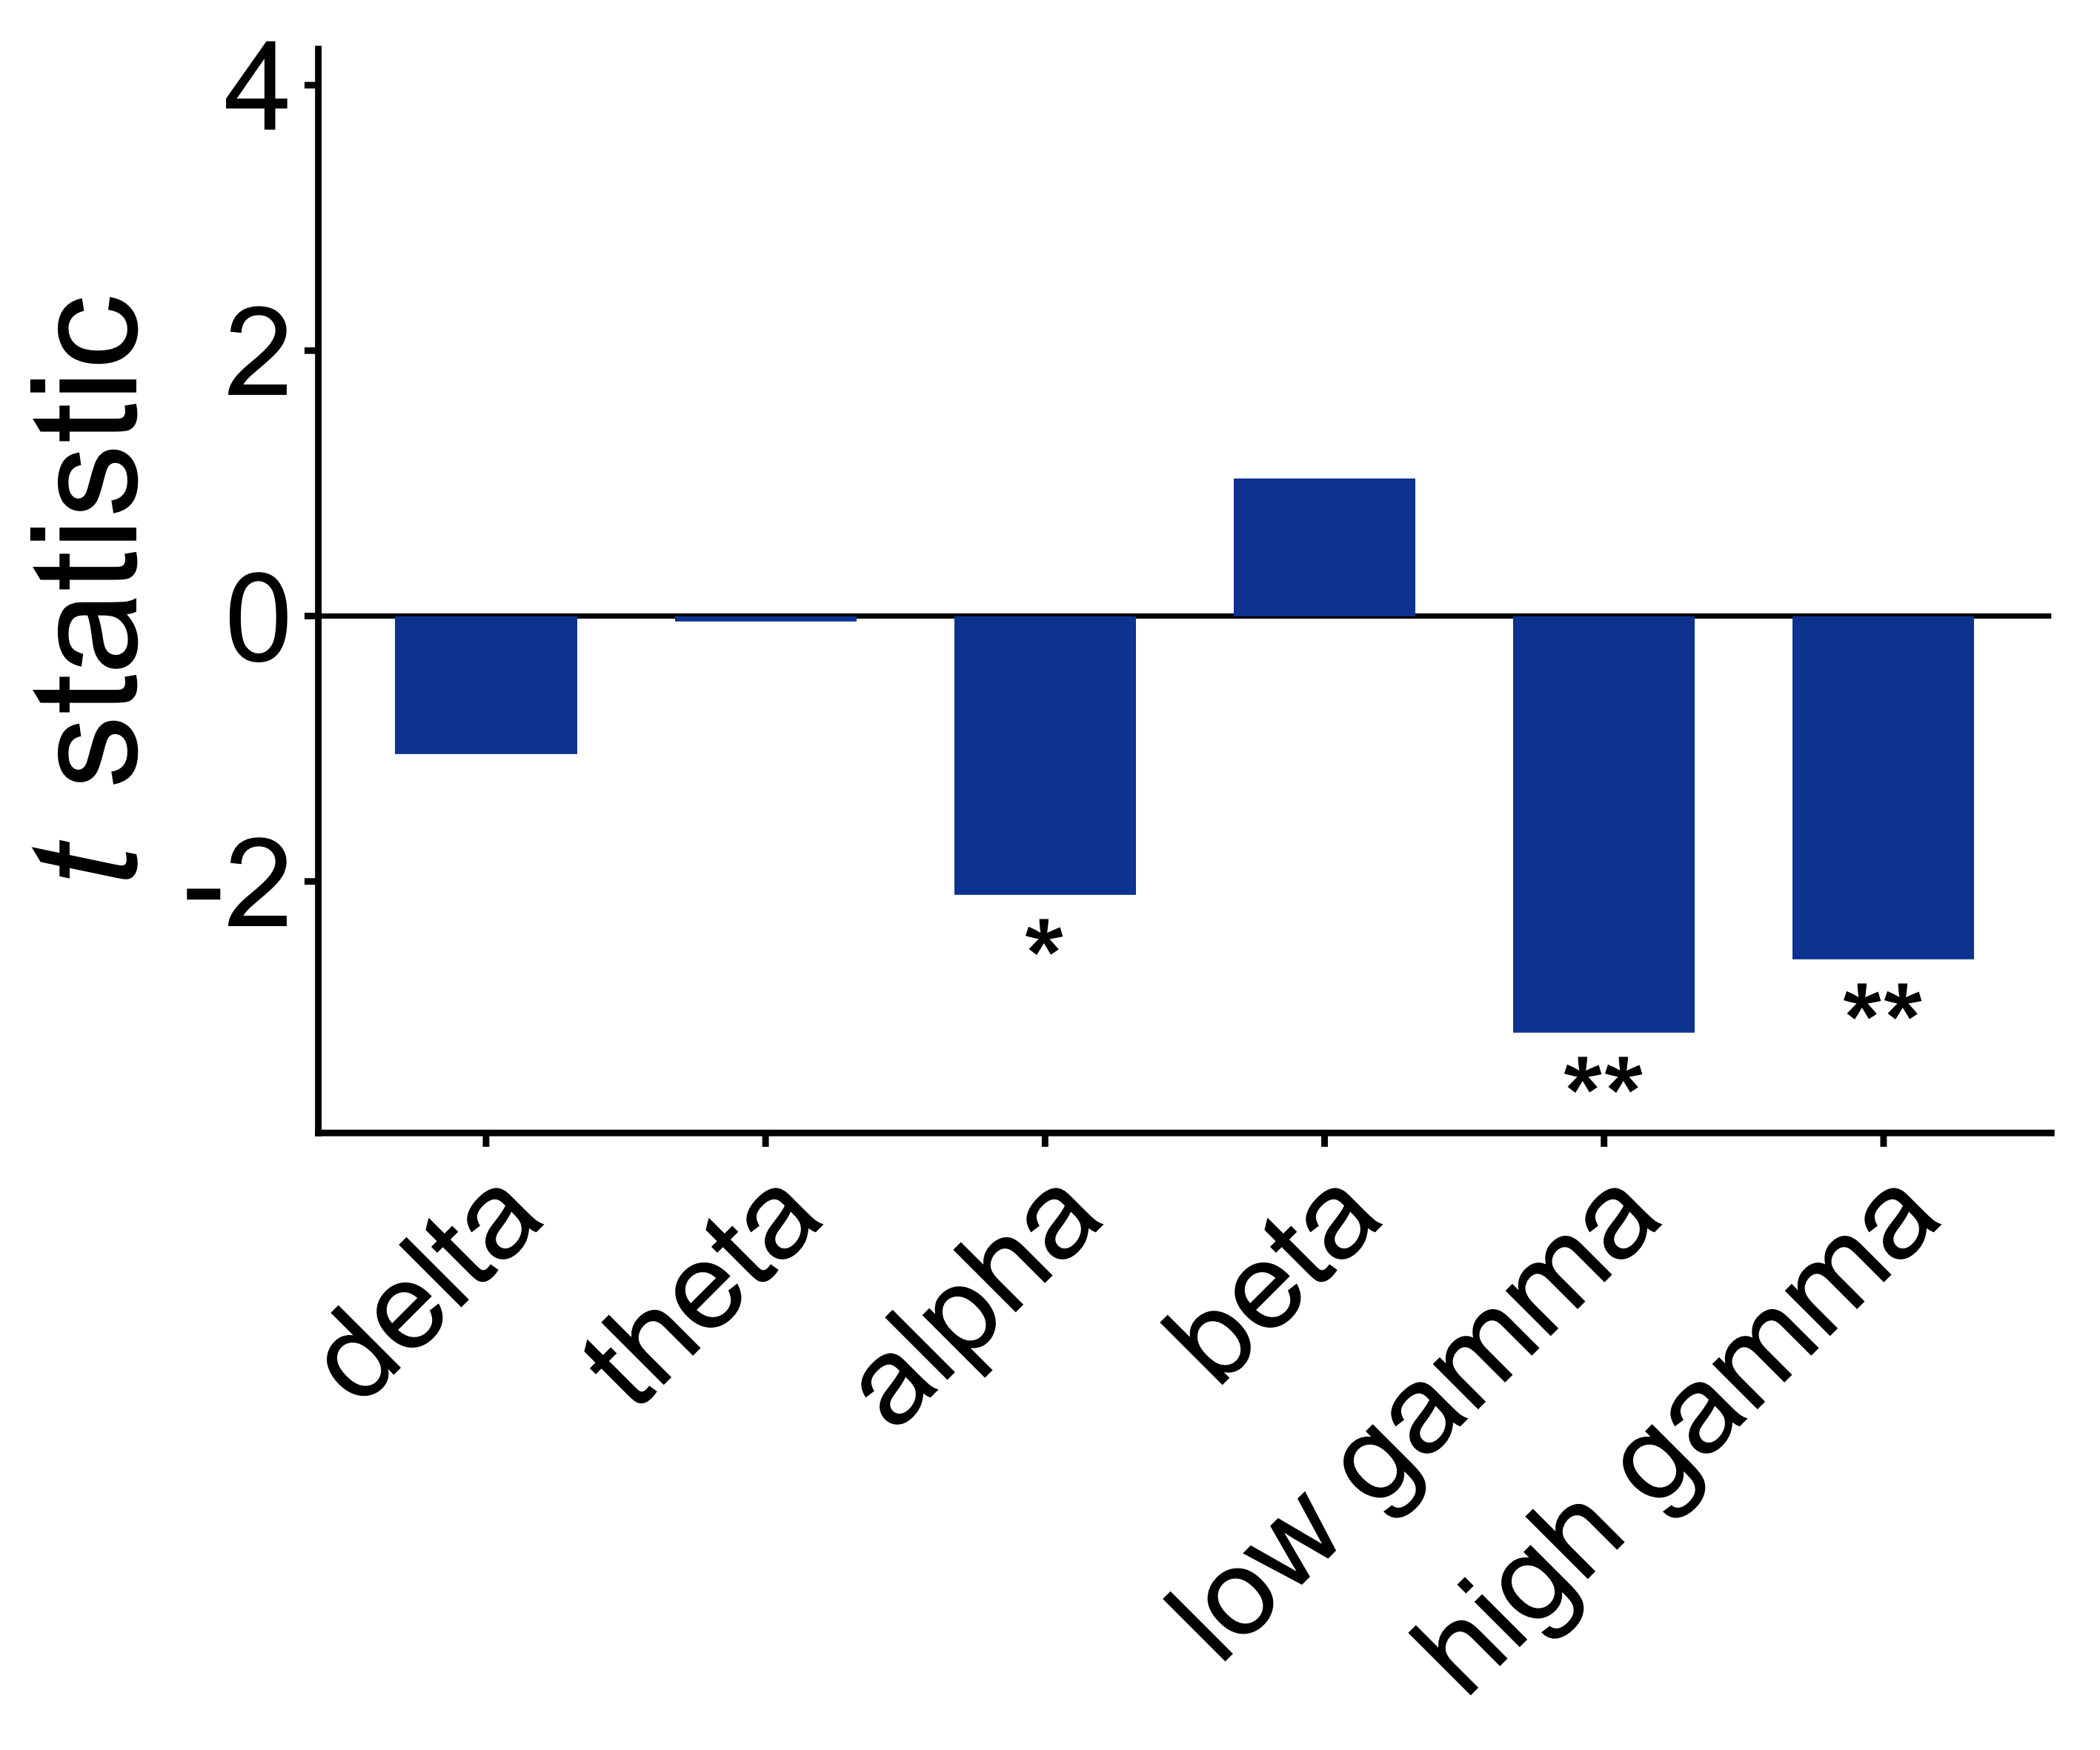

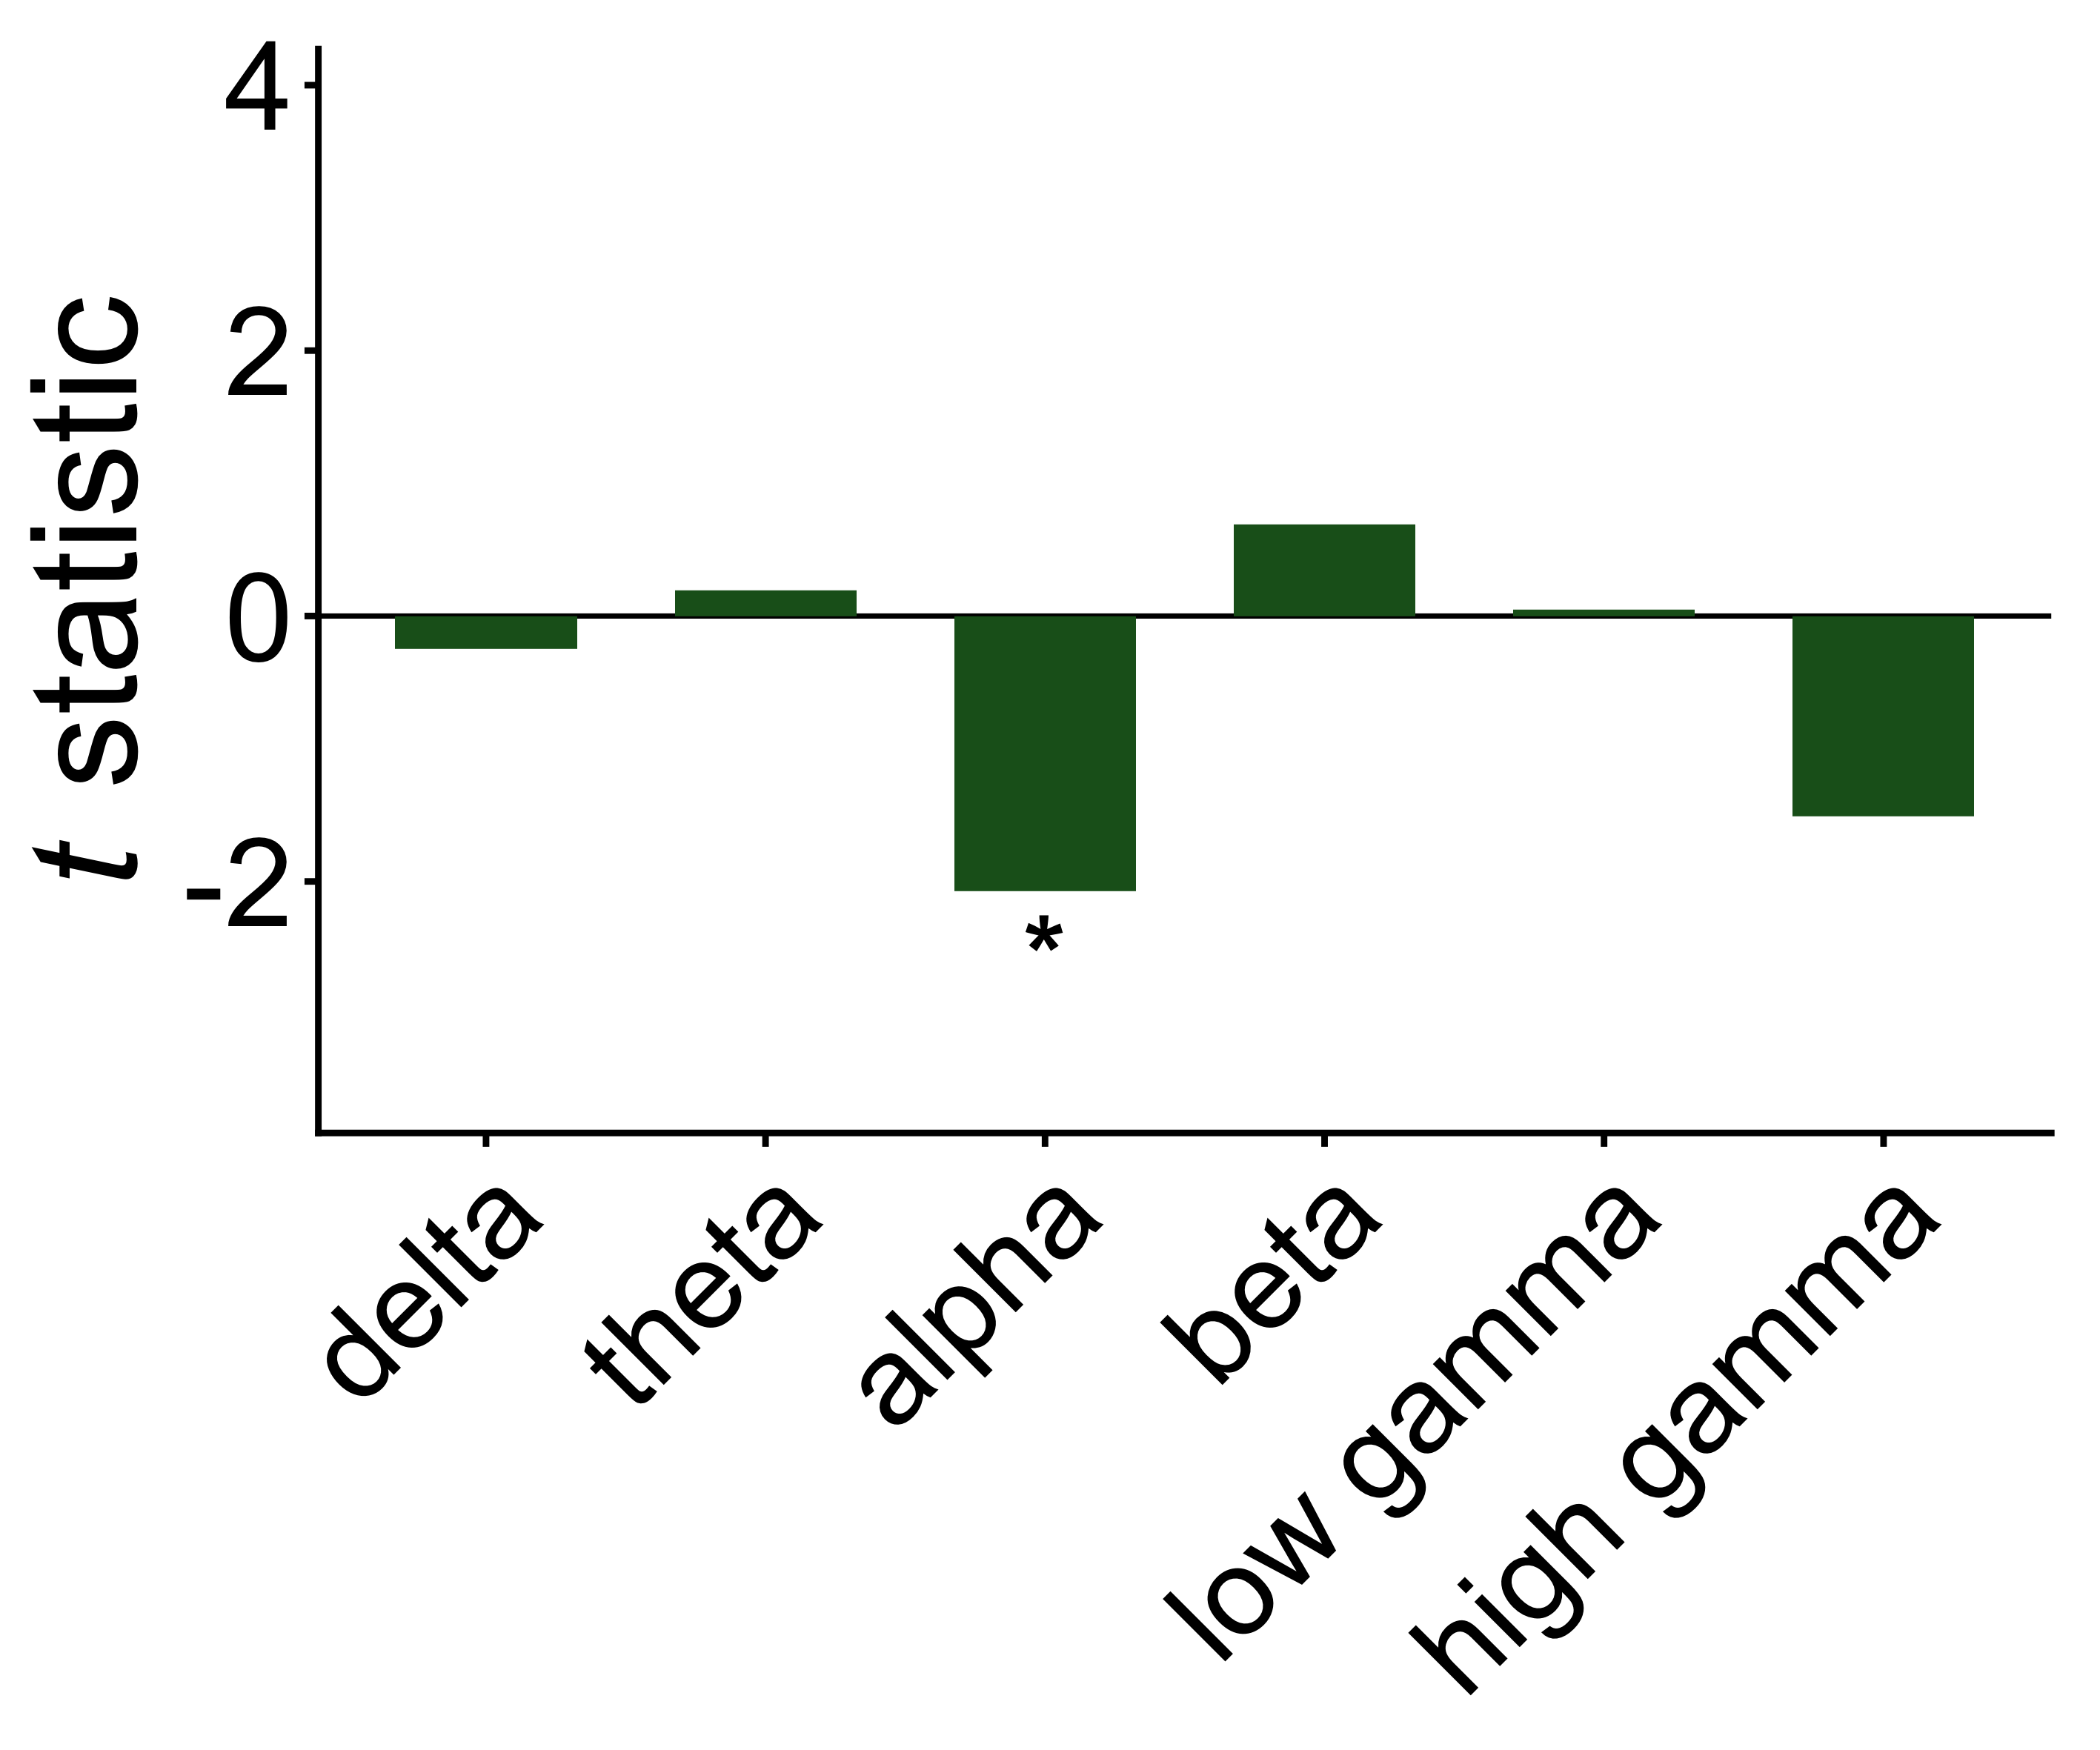

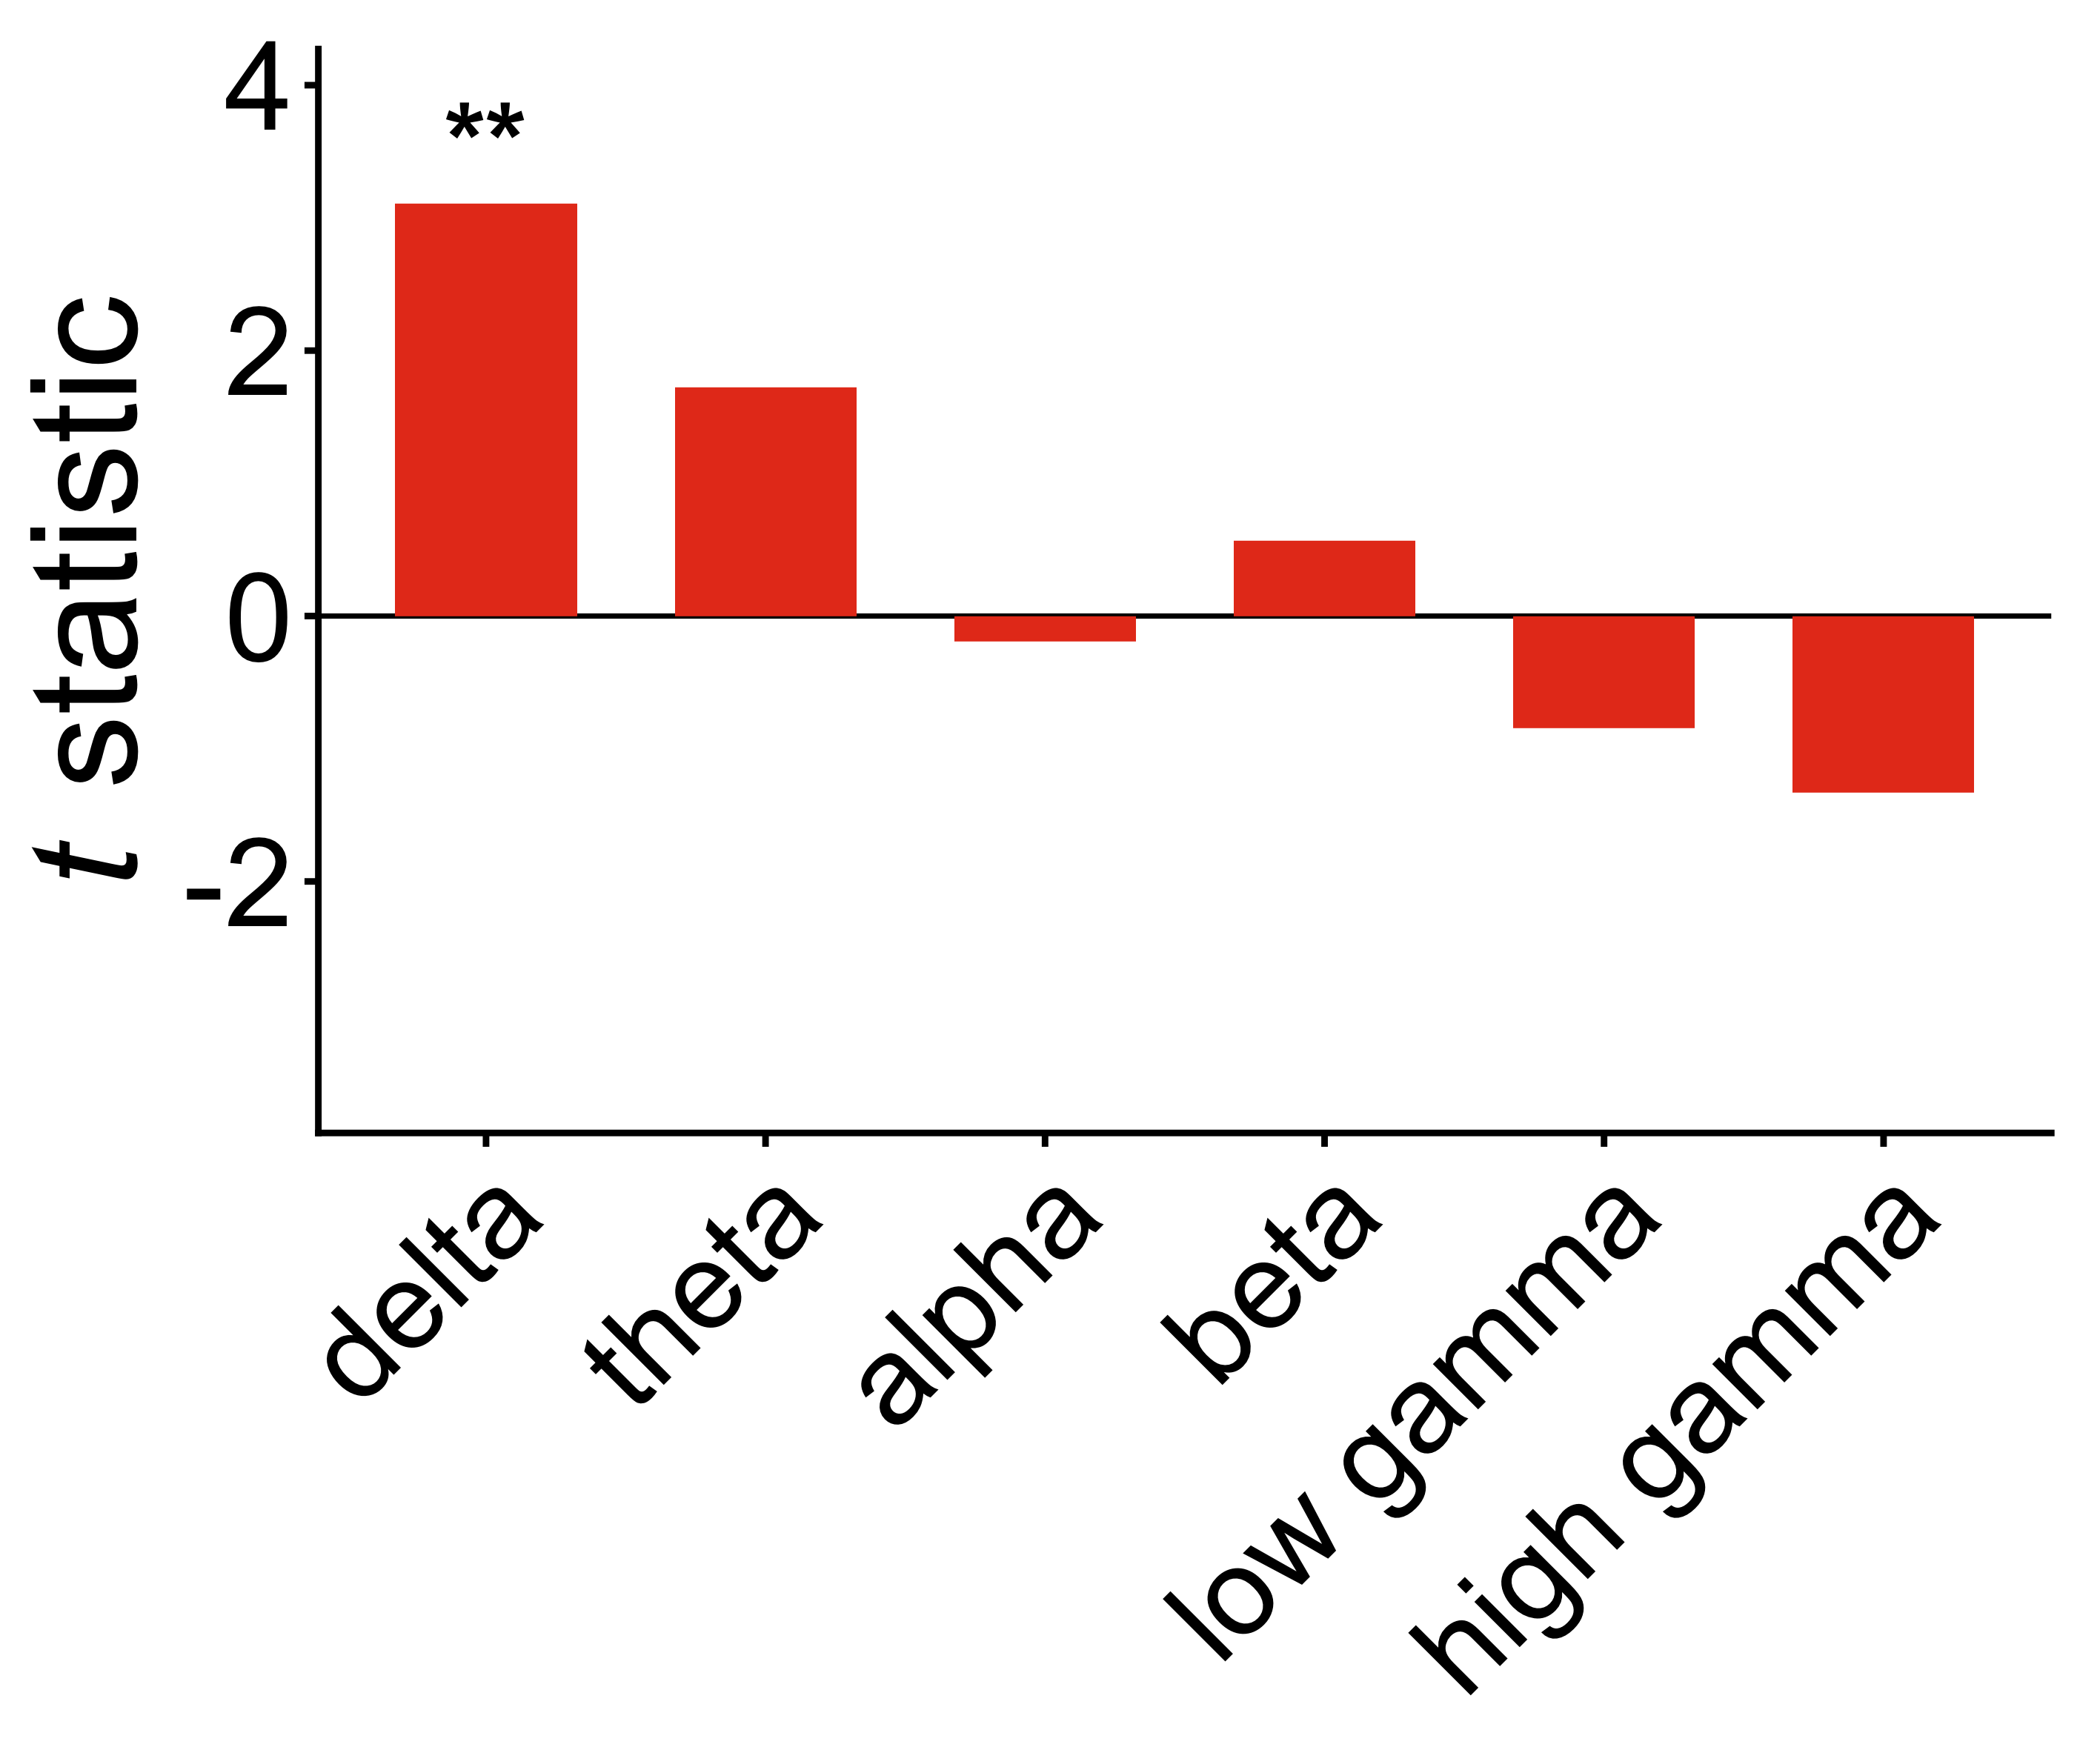

In [19]:
from pathlib import Path
import pandas as pd
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from IPython.display import Image, display

project_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
out_dir = project_dir / "analyses/stable_260725/plots"
out_dir.mkdir(parents=True, exist_ok=True)
roi_colors = {2027: "#0D47A1", 2018: "#1B5E20", 2031: "#E73F1E"}

# Font sizes in points (pt).
x_tick_label_size = 20
y_tick_label_size = 20
x_axis_label_size = 24
y_axis_label_size = 24
x_axis_label = ro.NULL  # e.g. "Frequency band" to show an x-axis title
y_axis_label = ro.r('expression(italic(t) * " statistic")')

ro.r["source"](str(project_dir / "scripts/plot_utilities.R"))
plot_func = ro.globalenv["plot_seeg_lmm_tstat_bar"]
roi_results = {
    roi: pd.read_csv(
        project_dir / f"analyses/seeg/power_lmm_roi{roi}"
        / f"all_ROI_{roi}_matched_first_contact_lmm_by_band.csv"
    )
    for roi in roi_colors
}
# Share a symmetric t-statistic scale across the three ROI plots.
max_abs_t = max(
    df["tStat" if "tStat" in df.columns else "tStats"].abs().max()
    for df in roi_results.values()
)
y_limits = ro.FloatVector([-max(max_abs_t, 0.1), max(max_abs_t, 0.1)])

for roi, color in roi_colors.items():
    out_png = out_dir / f"all_ROI_{roi}_matched_first_contact_lmm_tstat_by_band.png"
    with localconverter(ro.default_converter + pandas2ri.converter):
        r_df = ro.conversion.py2rpy(roi_results[roi])
    plot_func(
        df=r_df,
        out_file=str(out_png),
        bar_color=color,
        title=ro.NULL,
        xlab=x_axis_label,
        ylab=y_axis_label,
        x_tick_label_size=x_tick_label_size,
        y_tick_label_size=y_tick_label_size,
        x_axis_label_size=x_axis_label_size,
        y_axis_label_size=y_axis_label_size,
        y_limits=y_limits,
    )
    display(Image(filename=str(out_png)))


## plot Suzhou FC maps

In [ ]:
from pathlib import Path
import importlib
import sys
import matplotlib.pyplot as plt

project_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
scripts_dir = str(project_dir / "scripts")
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)
import plot_utils
importlib.reload(plot_utils)

out_dir = project_dir / "analyses/stable_260725/FC_analyses"
stats_dir = out_dir / "Suzhou/stats"
left_maps = sorted(stats_dir.rglob("PT_*_lh_dpv_tstat_TFCEcorrected025.gii"))
if not left_maps:
    raise FileNotFoundError(f"No Suzhou TFCE-corrected maps found in {stats_dir}")

# Validate all hemisphere pairs before producing figures.
pairs = []
for left_map in left_maps:
    right_map = left_map.with_name(left_map.name.replace("_lh_", "_rh_"))
    if not right_map.is_file():
        raise FileNotFoundError(f"Missing right hemisphere map: {right_map}")
    pairs.append((left_map, right_map))

out_dir.mkdir(parents=True, exist_ok=True)
for left_map, right_map in pairs:
    map_name = left_map.stem.replace("_lh_", "_")
    out_file = out_dir / f"Suzhou_{left_map.parent.name}_{map_name}_onerow.png"
    plot_utils.plot_surface_maps_onerow(
        left_gii=str(left_map),
        right_gii=str(right_map),
        out_file=str(out_file),
        colorbar_label=r"$\mathit{t}$ statistic",
        current_threshold=1e-10,  # Hide zeroed, nonsignificant vertices.
    )
    plt.close(plt.gcf())
    print(f"Saved: {out_file}")


## plot Beijing FC maps

In [ ]:
from pathlib import Path
import importlib
import sys
import matplotlib.pyplot as plt

project_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
scripts_dir = str(project_dir / "scripts")
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)
import plot_utils
importlib.reload(plot_utils)

out_dir = project_dir / "analyses/stable_260725/FC_analyses"
stats_dir = out_dir / "Beijing/stats"
left_maps = sorted(stats_dir.rglob("PT_*_lh_dpv_tstat_TFCEcorrected025.gii"))
if not left_maps:
    raise FileNotFoundError(f"No Beijing TFCE-corrected maps found in {stats_dir}")

# Validate all hemisphere pairs before producing figures.
pairs = []
for left_map in left_maps:
    if not left_map.parent.name.endswith("_lh"):
        raise ValueError(f"Expected a left hemisphere folder: {left_map.parent}")
    right_dir = left_map.parent.with_name(left_map.parent.name[:-3] + "_rh")
    right_map = right_dir / left_map.name.replace("_lh_", "_rh_")
    if not right_map.is_file():
        raise FileNotFoundError(f"Missing right hemisphere map: {right_map}")
    pairs.append((left_map, right_map))

out_dir.mkdir(parents=True, exist_ok=True)
for left_map, right_map in pairs:
    map_name = left_map.stem.replace("_lh_", "_")
    analysis_name = left_map.parent.name[:-3]
    out_file = out_dir / f"Beijing_{analysis_name}_{map_name}_onerow.png"
    plot_utils.plot_surface_maps_onerow(
        left_gii=str(left_map),
        right_gii=str(right_map),
        out_file=str(out_file),
        colorbar_label=r"$\mathit{t}$ statistic",
        current_threshold=1e-10,  # Hide zeroed, nonsignificant vertices.
    )
    plt.close(plt.gcf())
    print(f"Saved: {out_file}")


## do plots for roi FC network stats

Saved 30 network bar plots to /Users/Chenxiao/Documents/project_codes/rumination_casual_mapping/analyses/stable_260725/plots
Suzhou_MDD_positive_gt3p29_cluster1_n69_mask.func_FunSurfWCF_network_tstat_bar.png


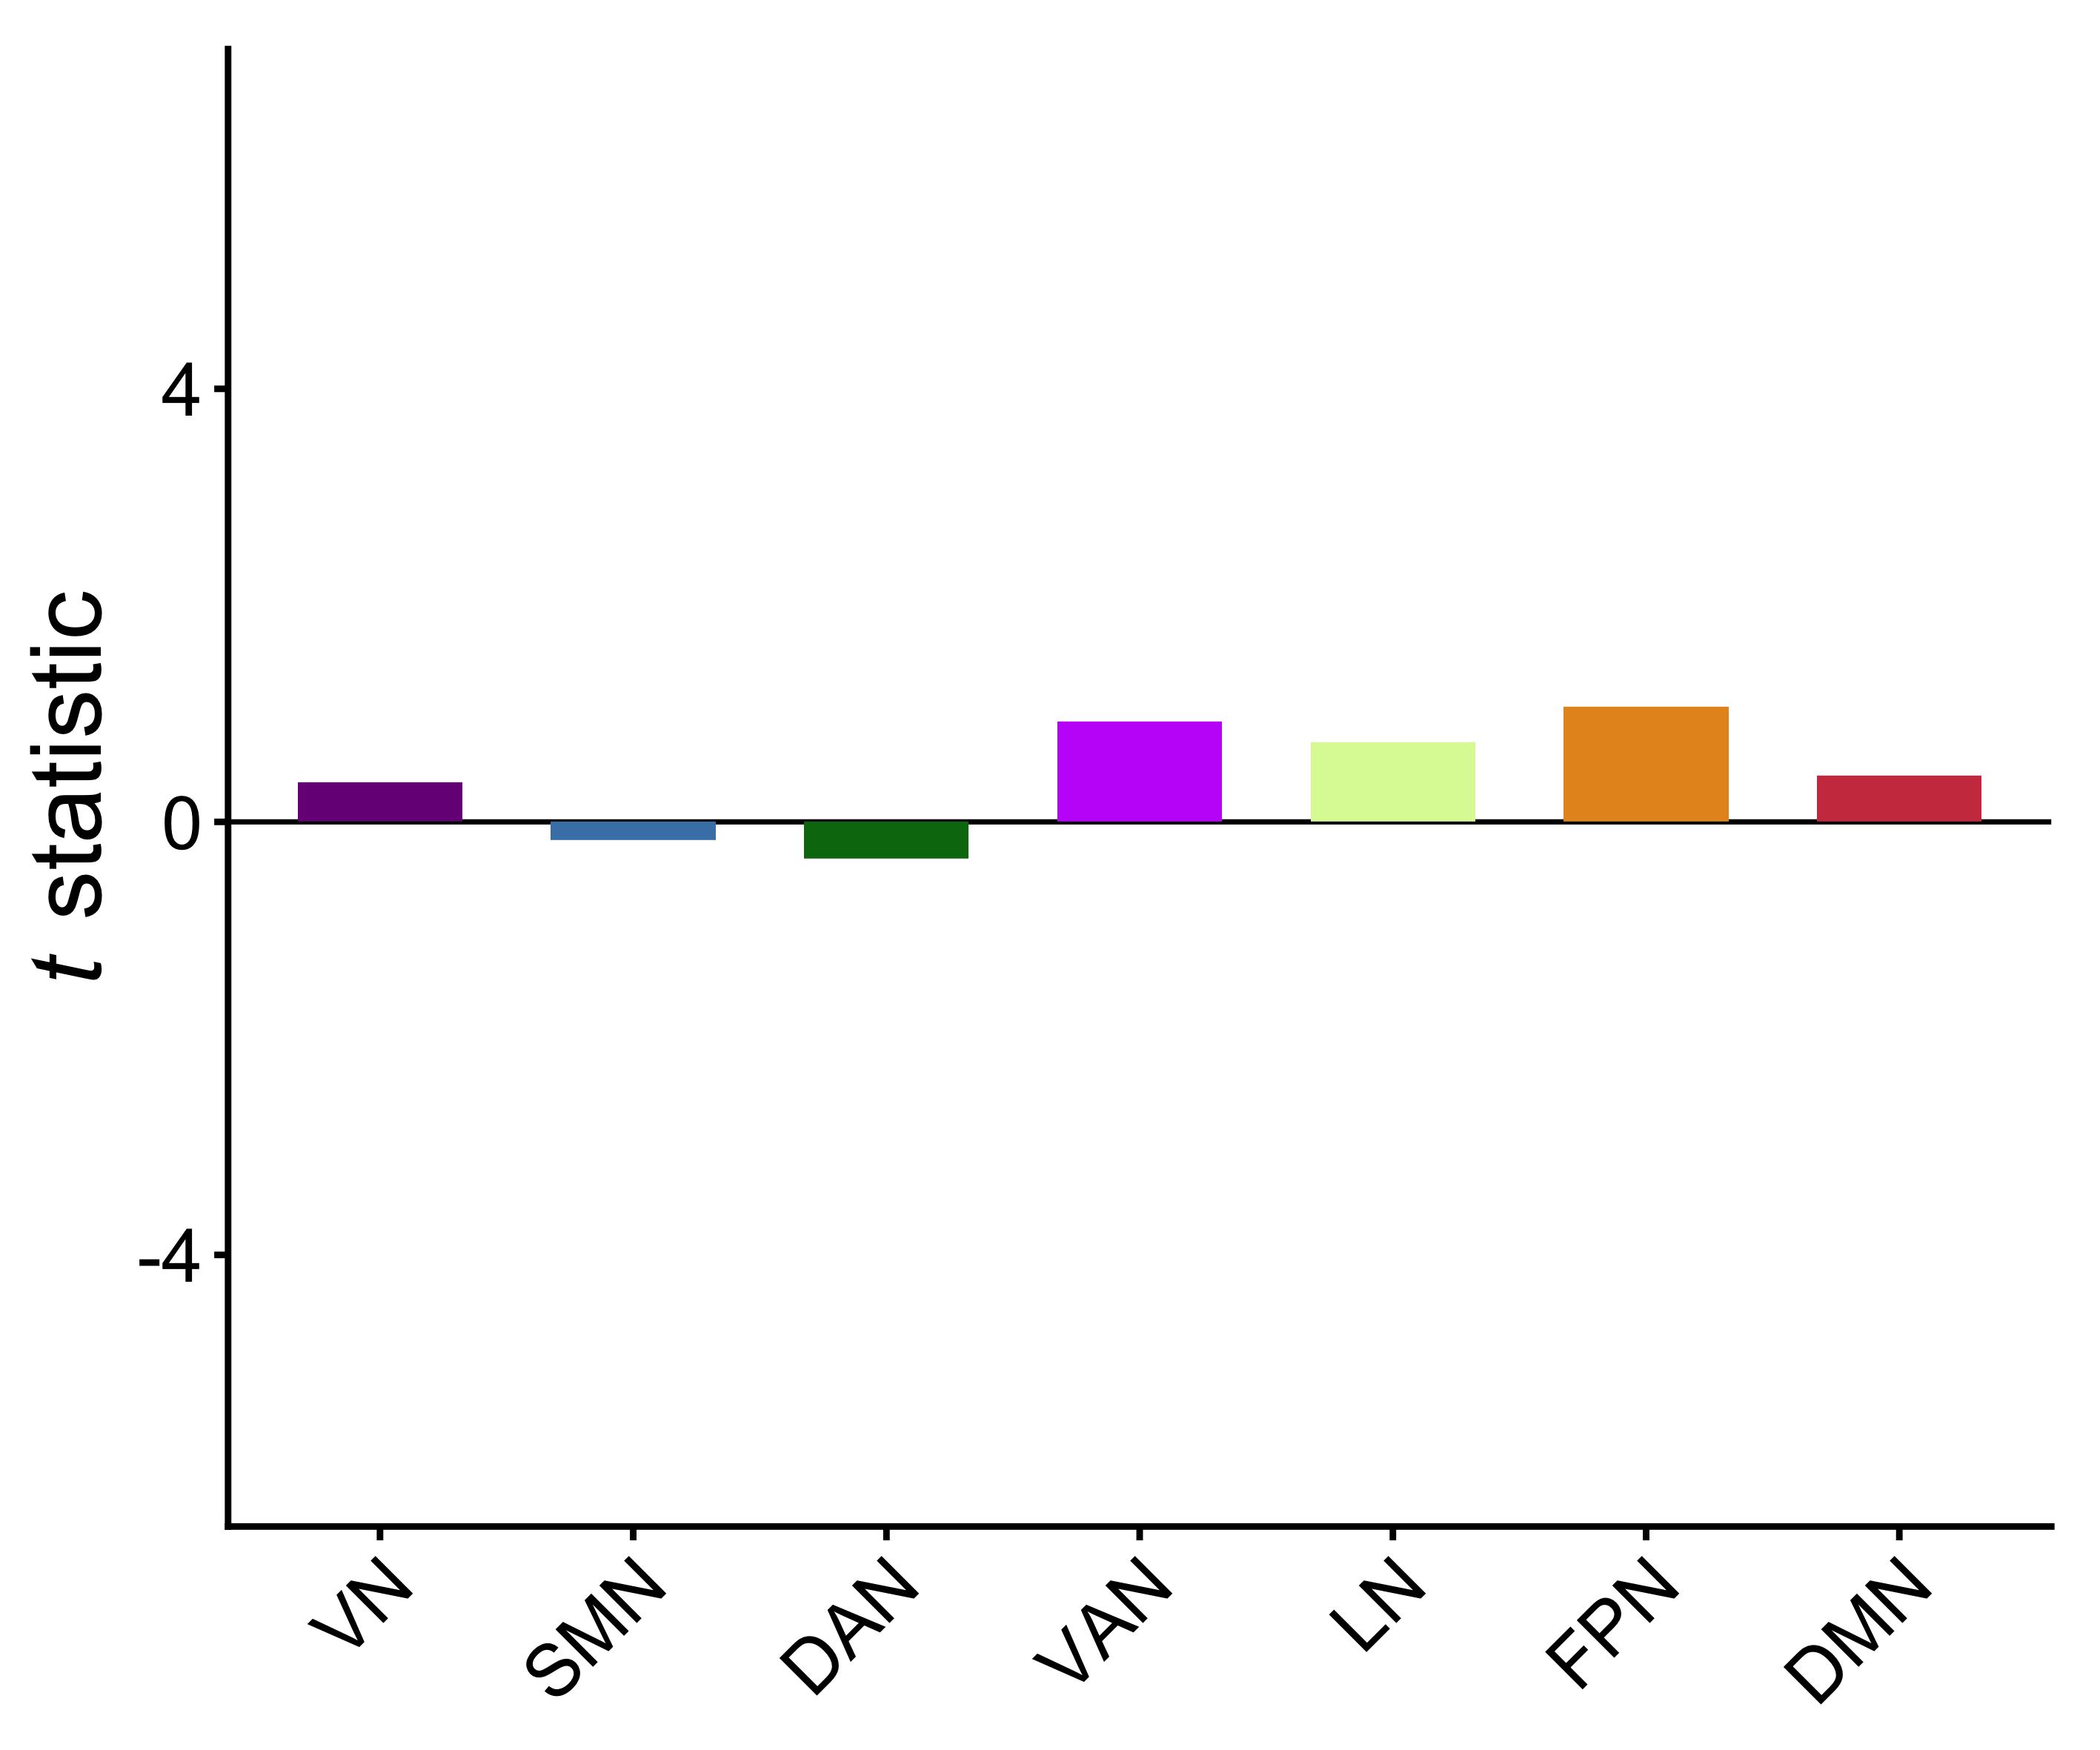

Suzhou_MDD_positive_gt3p29_cluster1_n69_mask.func_FunSurfWglobalCF_network_tstat_bar.png


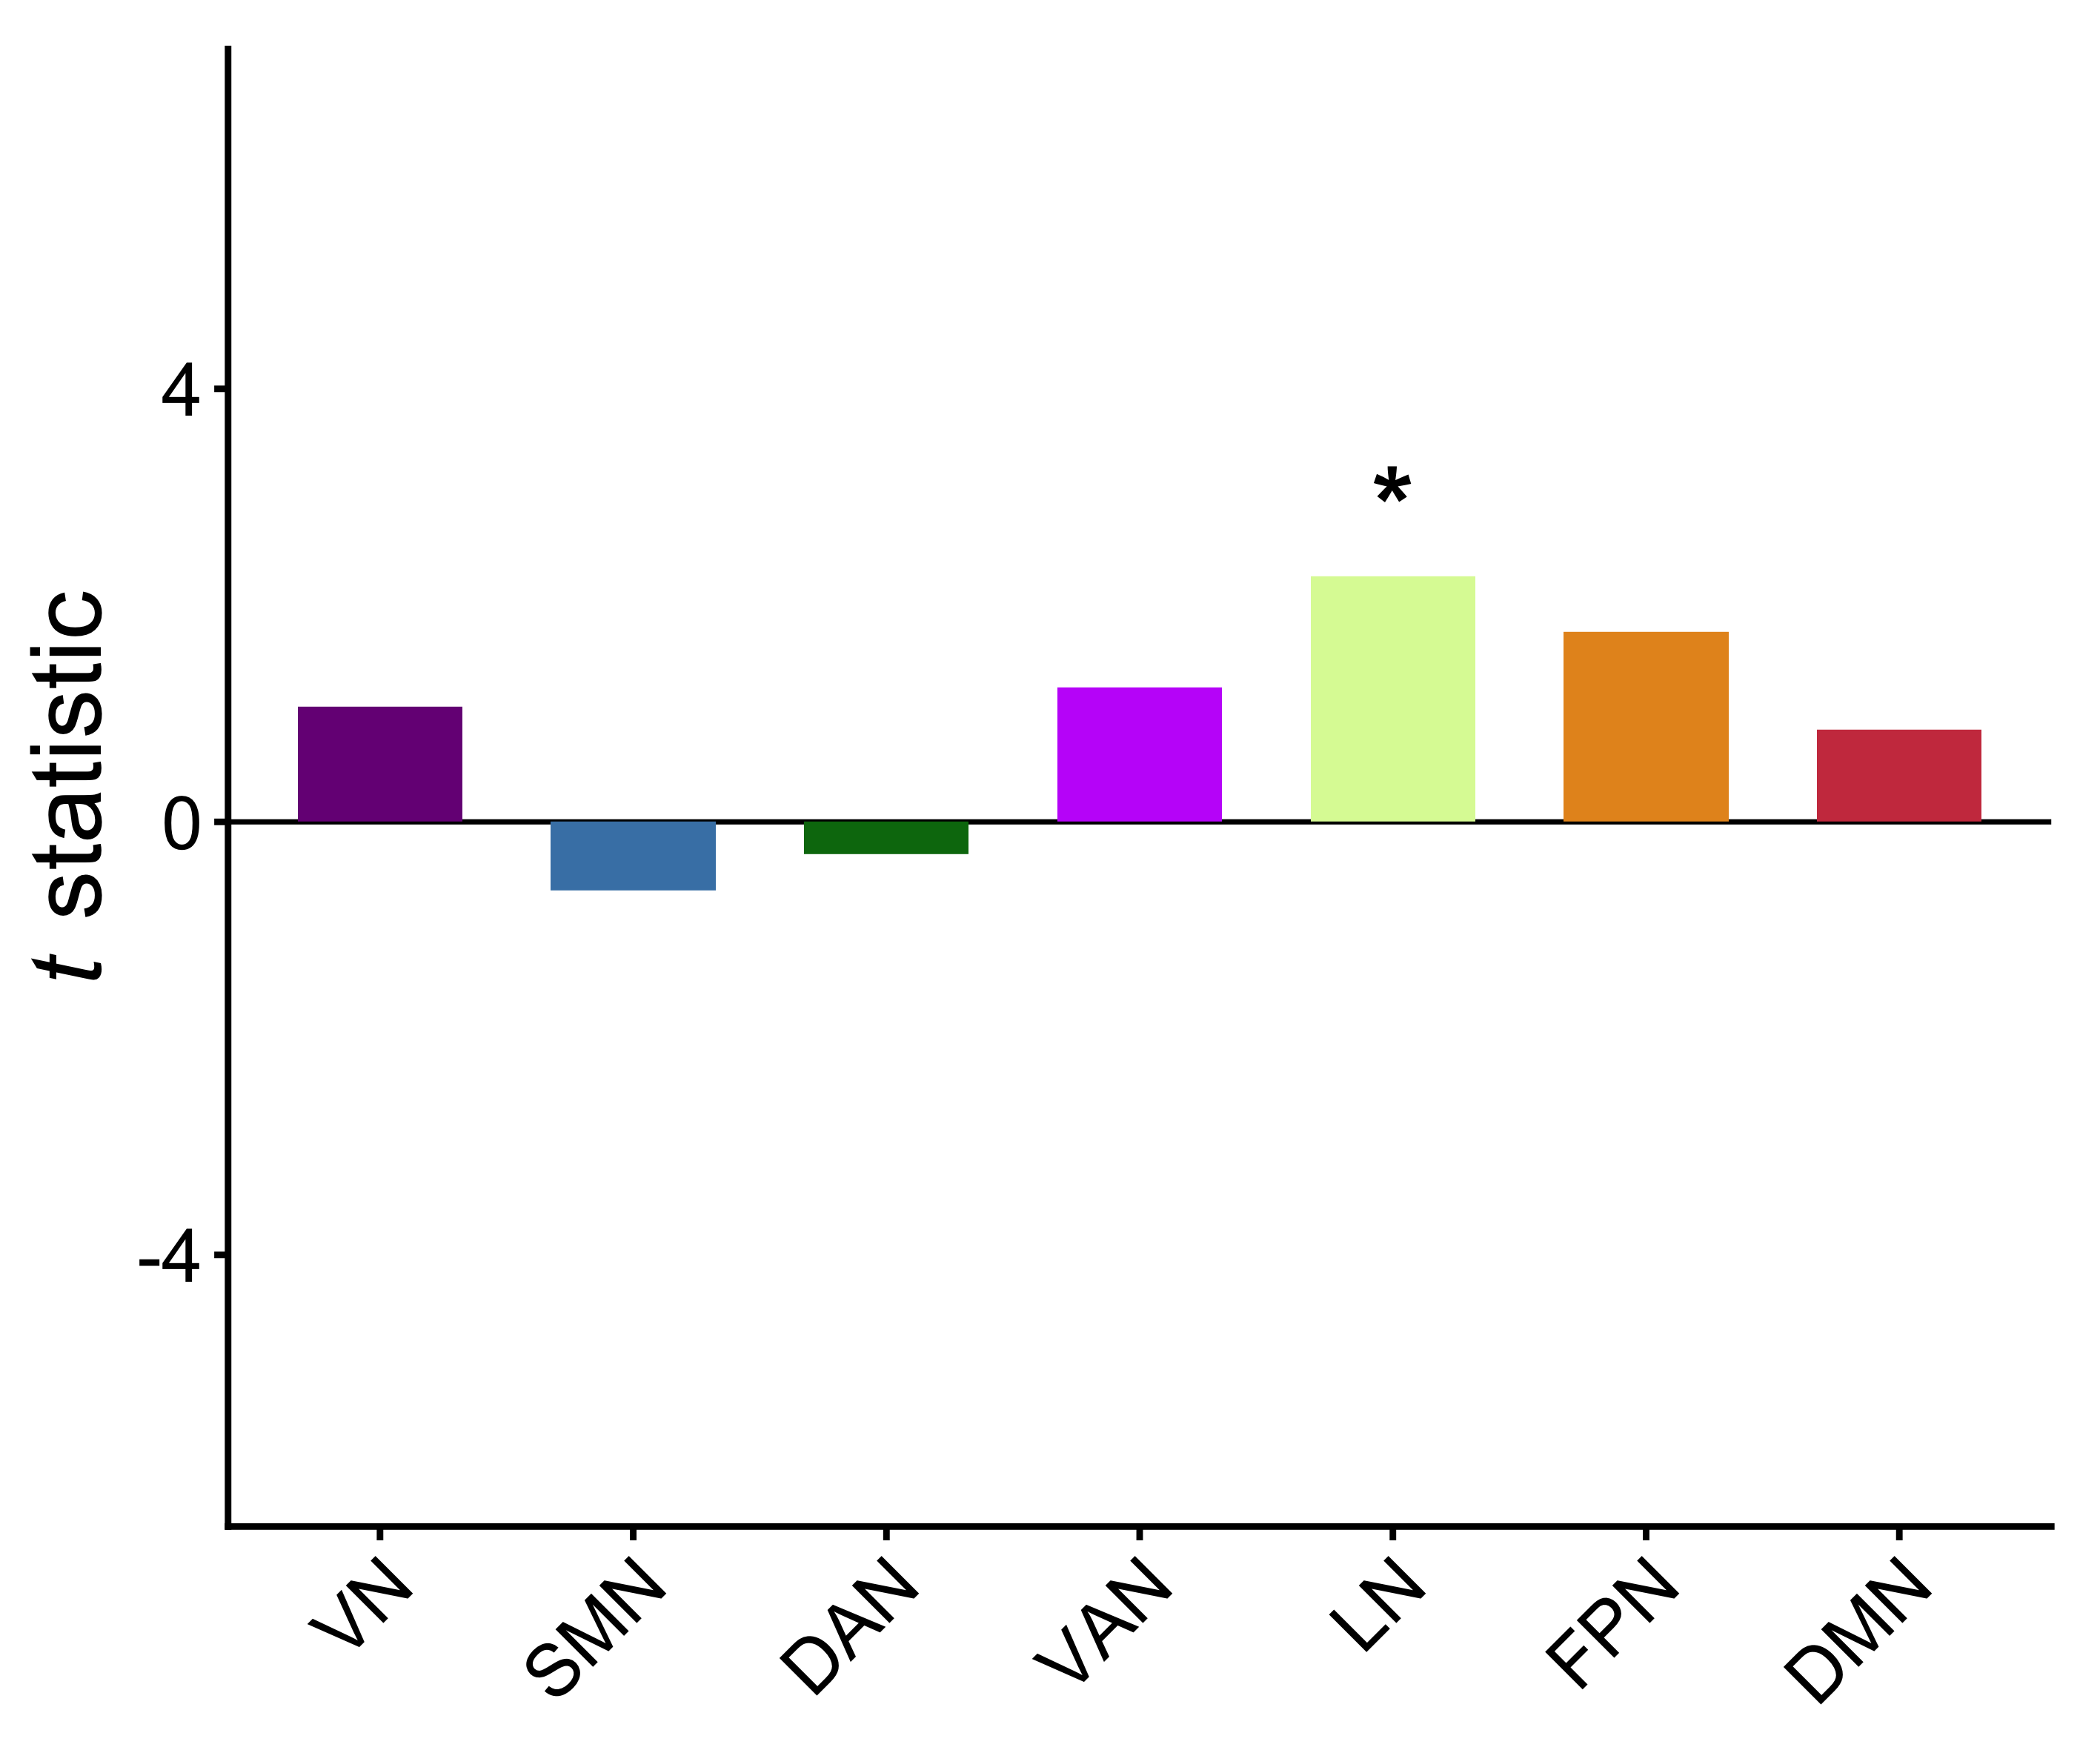

Suzhou_MDD_positive_gt3p29_cluster2_n50_mask.func_FunSurfWCF_network_tstat_bar.png


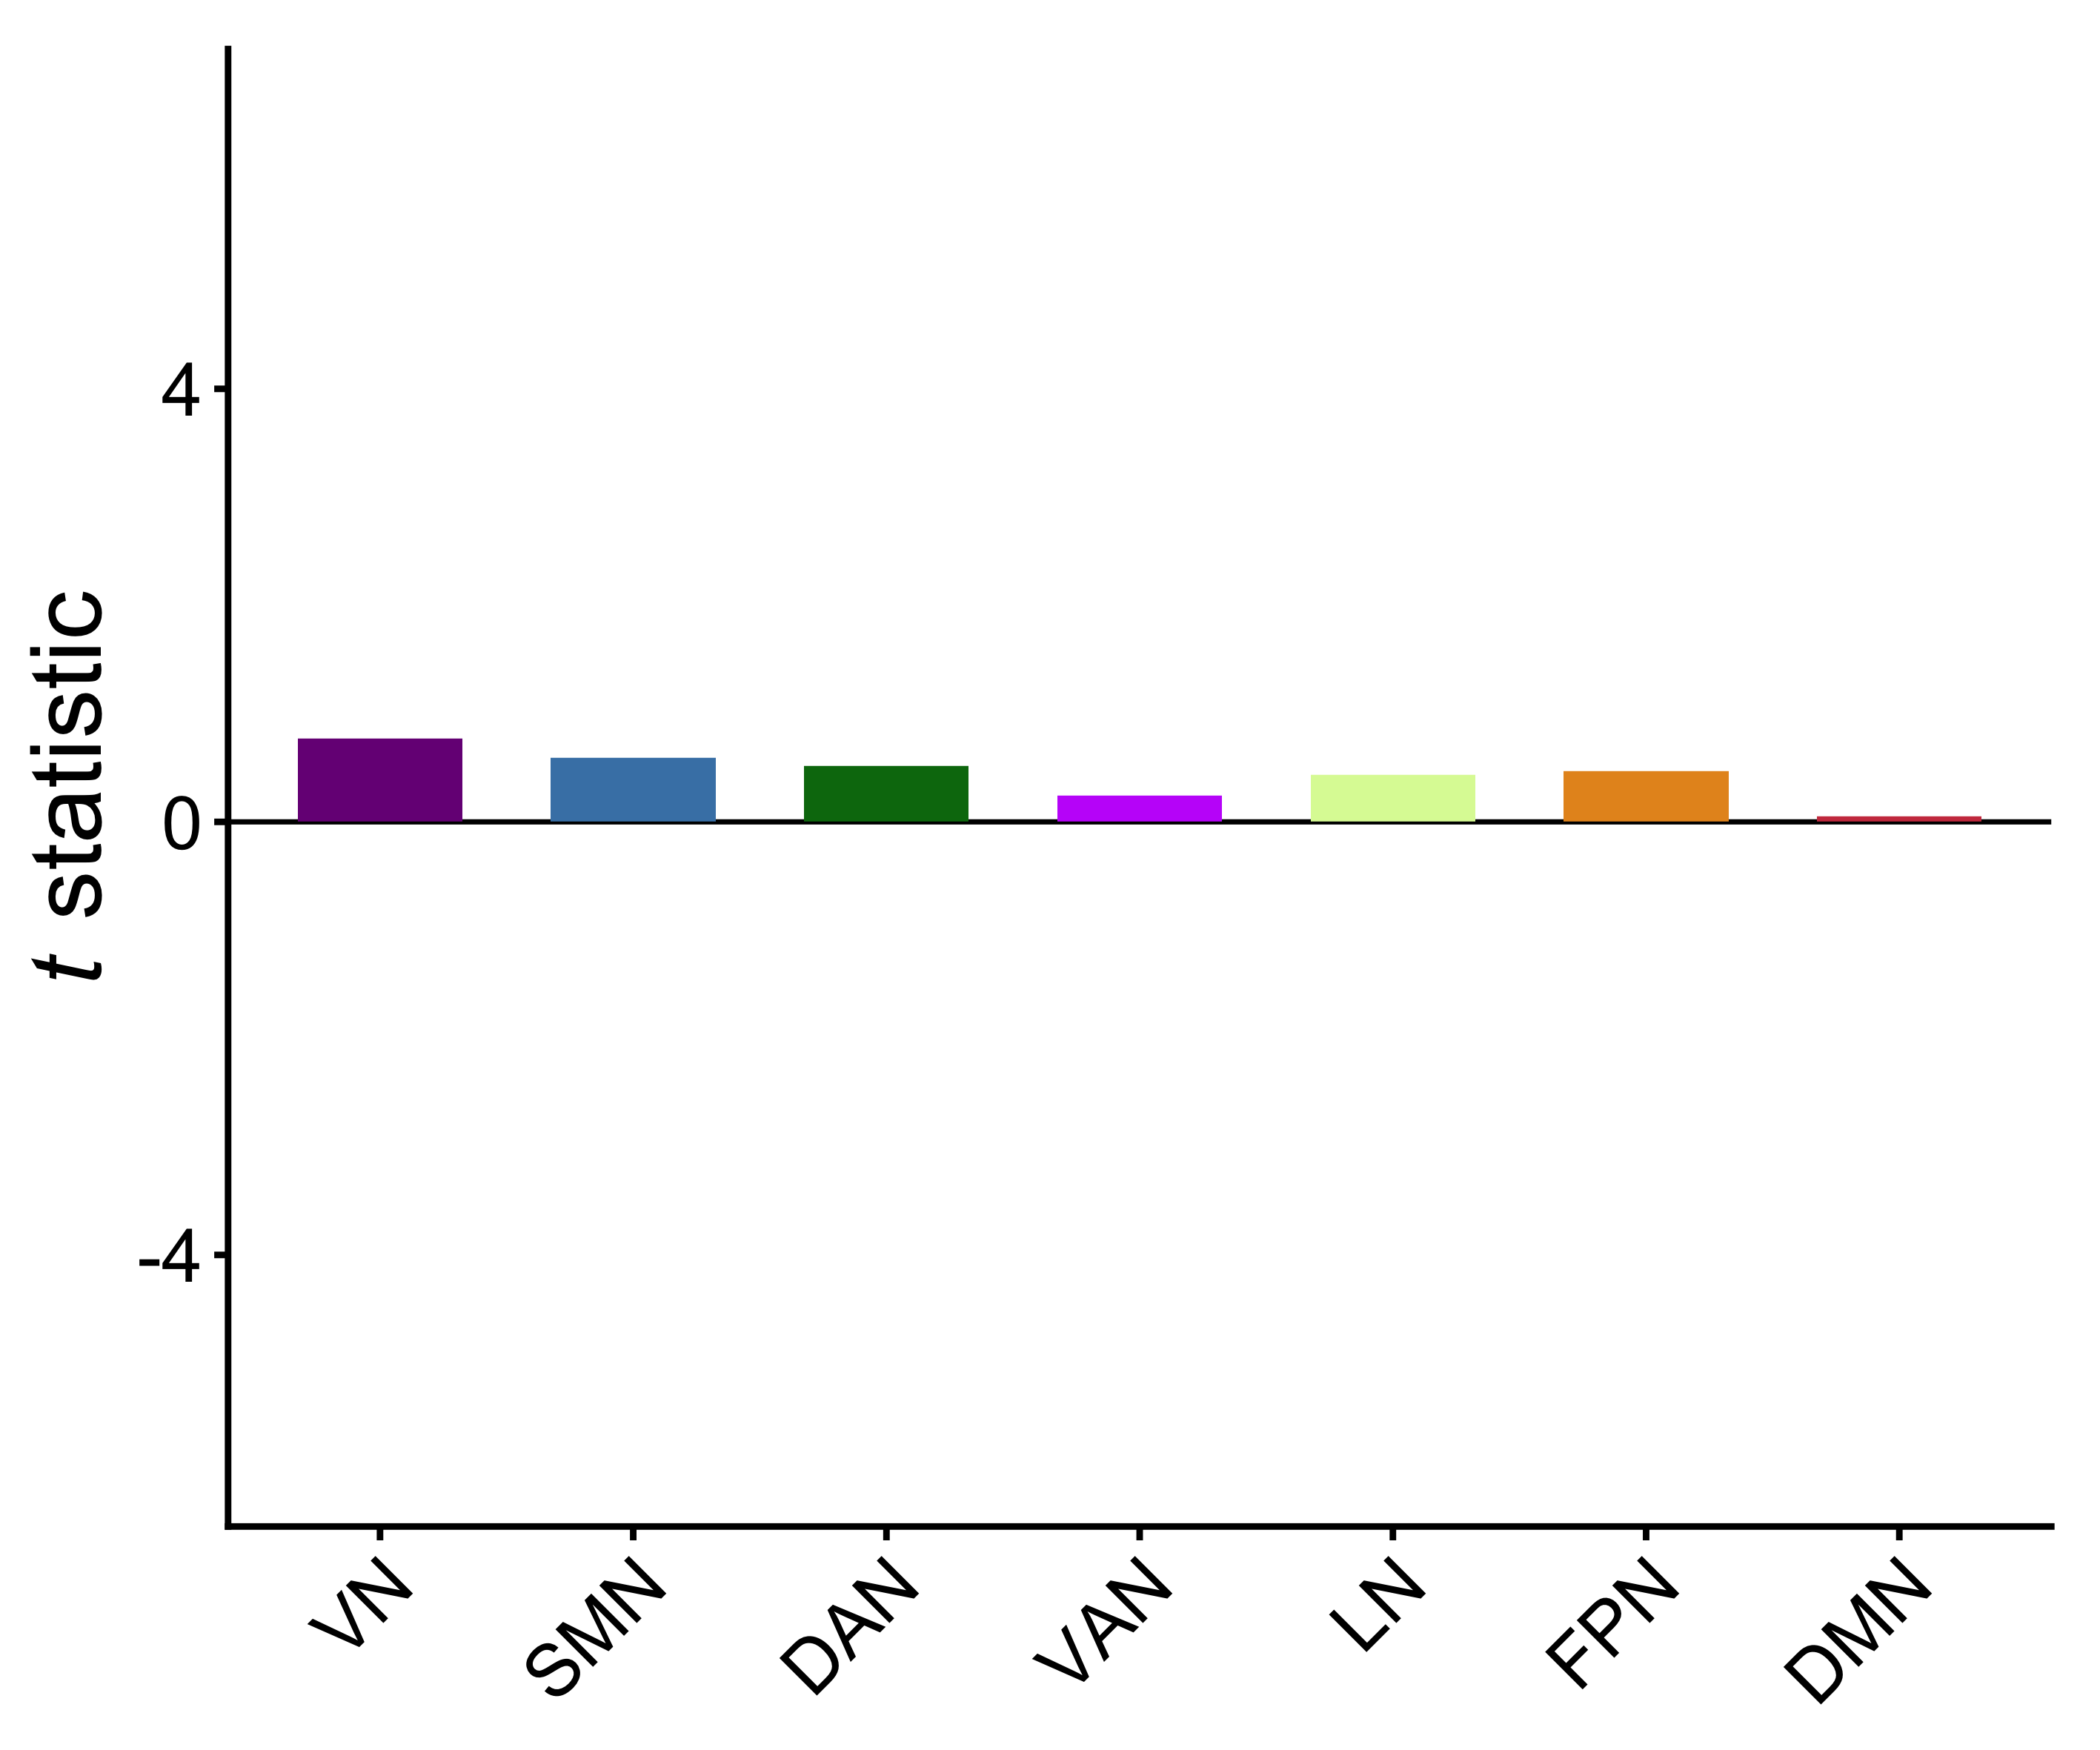

Suzhou_MDD_positive_gt3p29_cluster2_n50_mask.func_FunSurfWglobalCF_network_tstat_bar.png


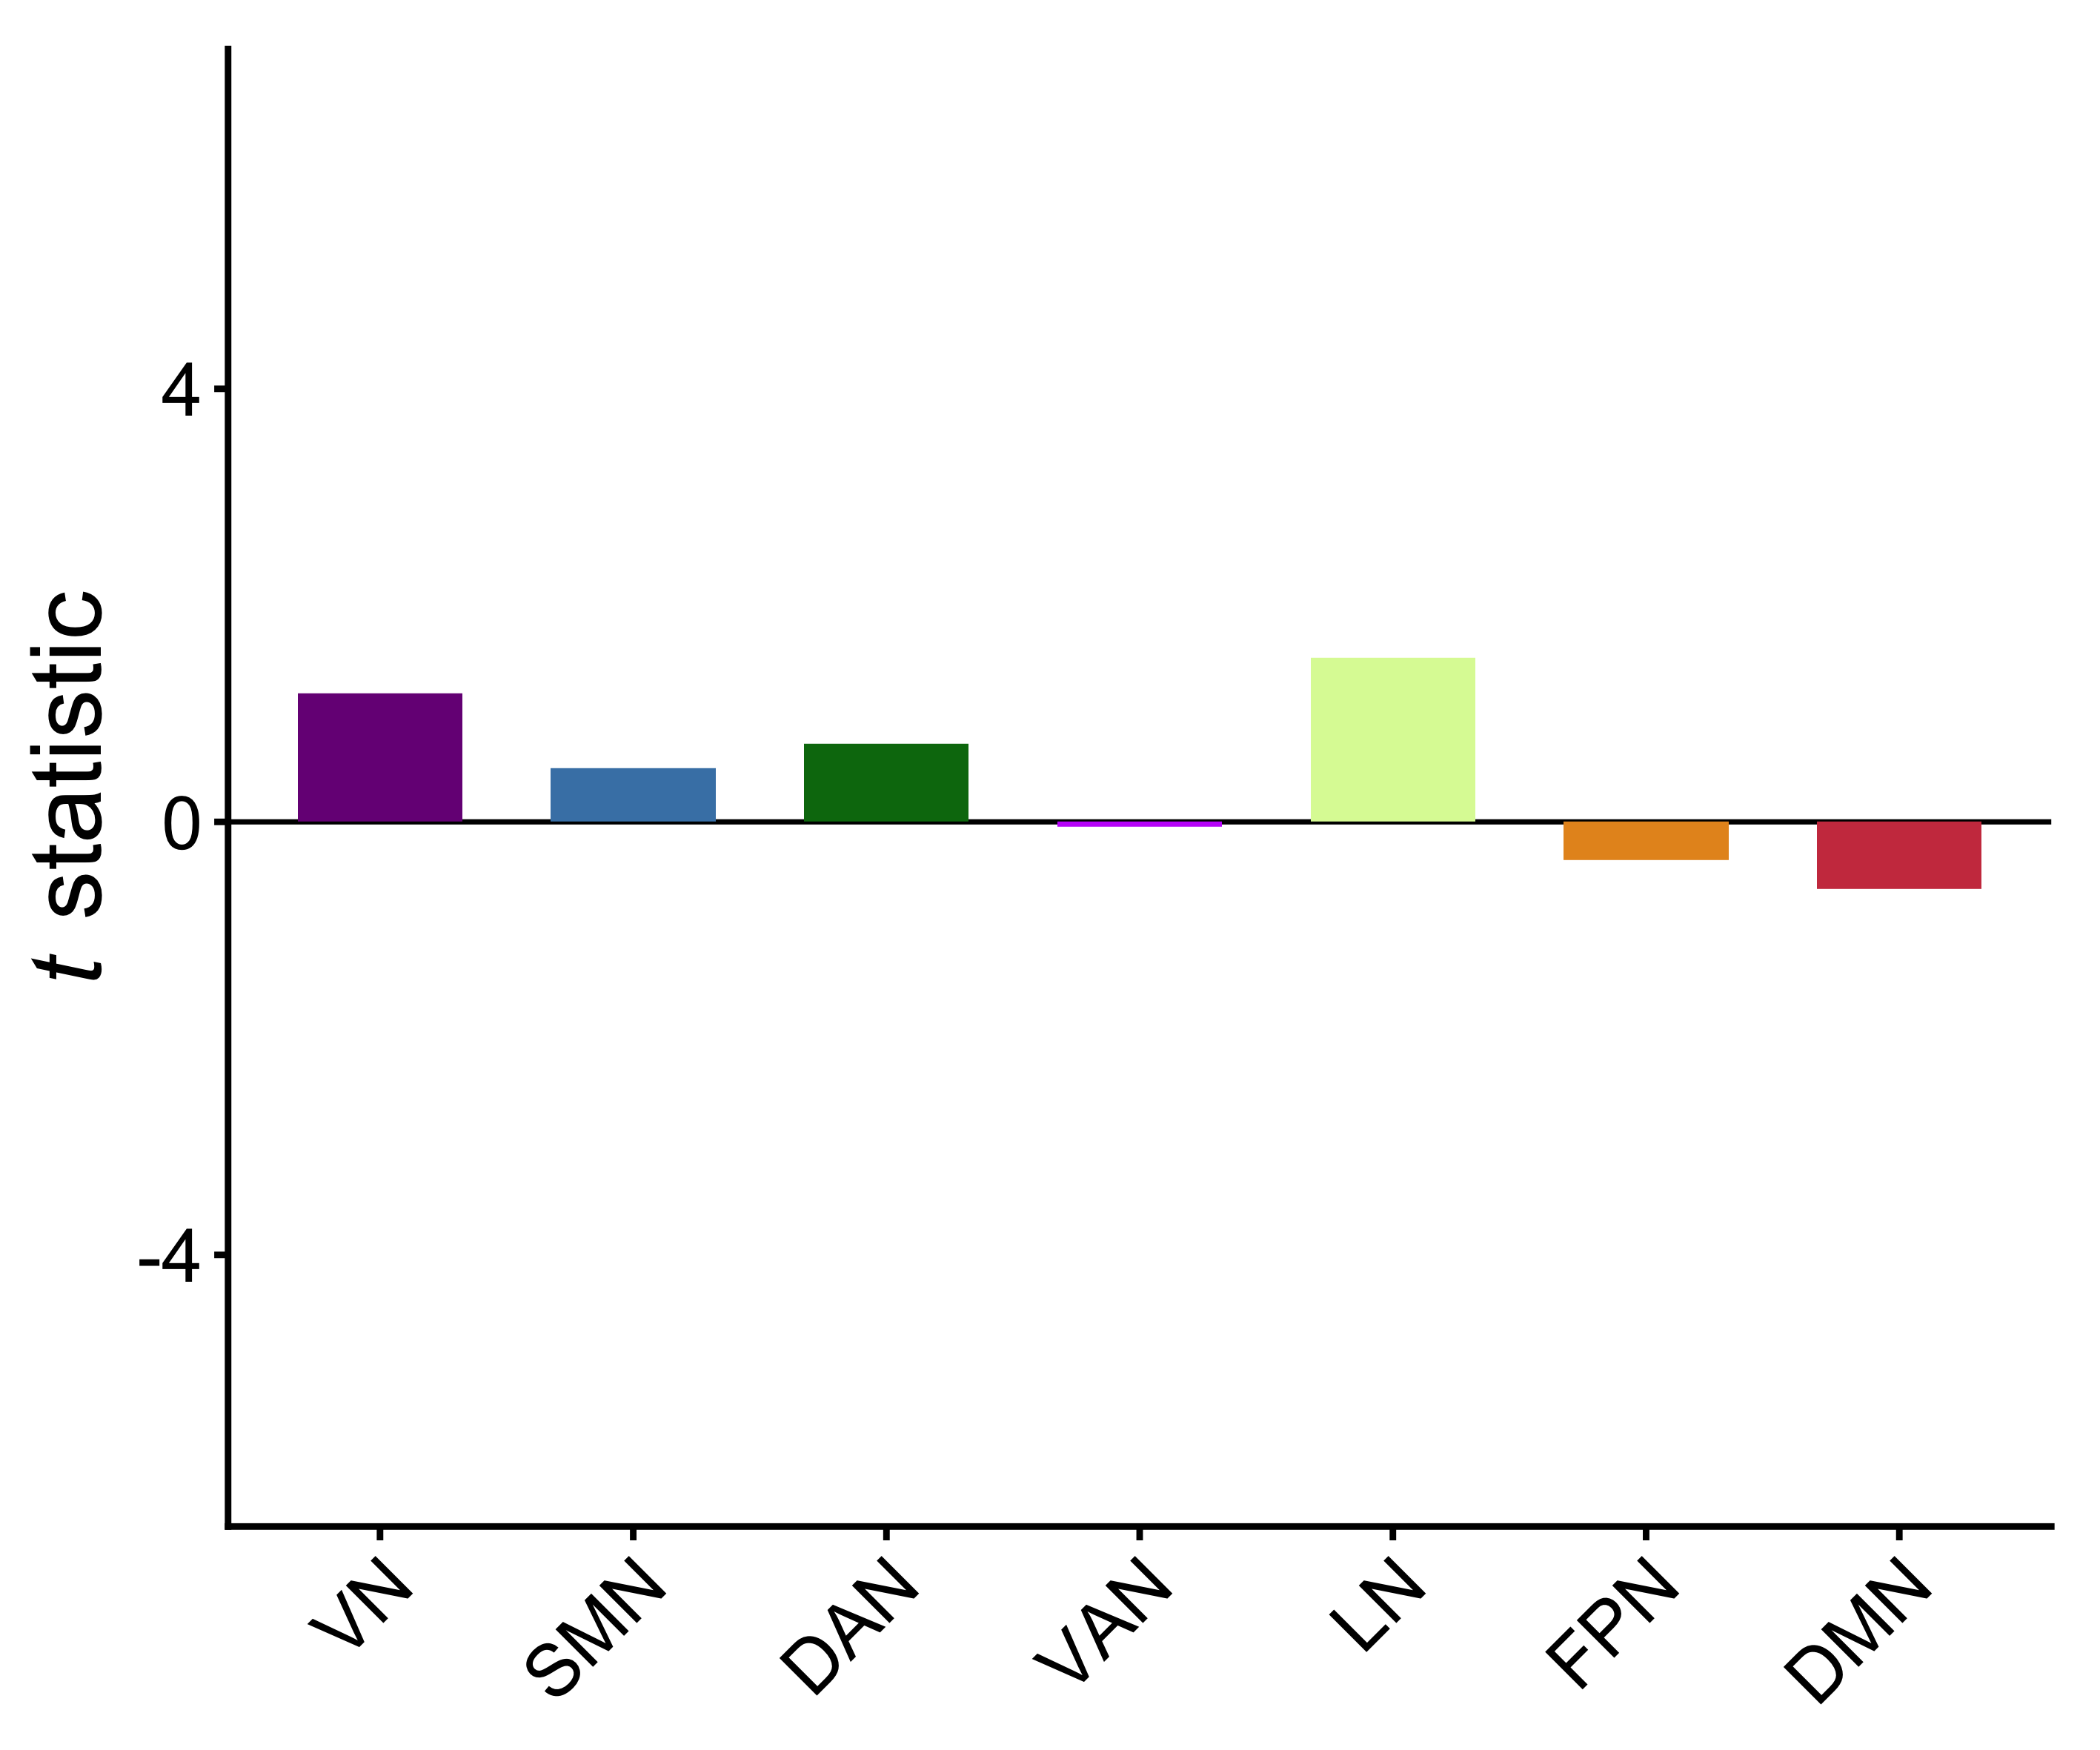

Suzhou_MDD_positive_gt3p29_cluster3_n33_mask.func_FunSurfWCF_network_tstat_bar.png


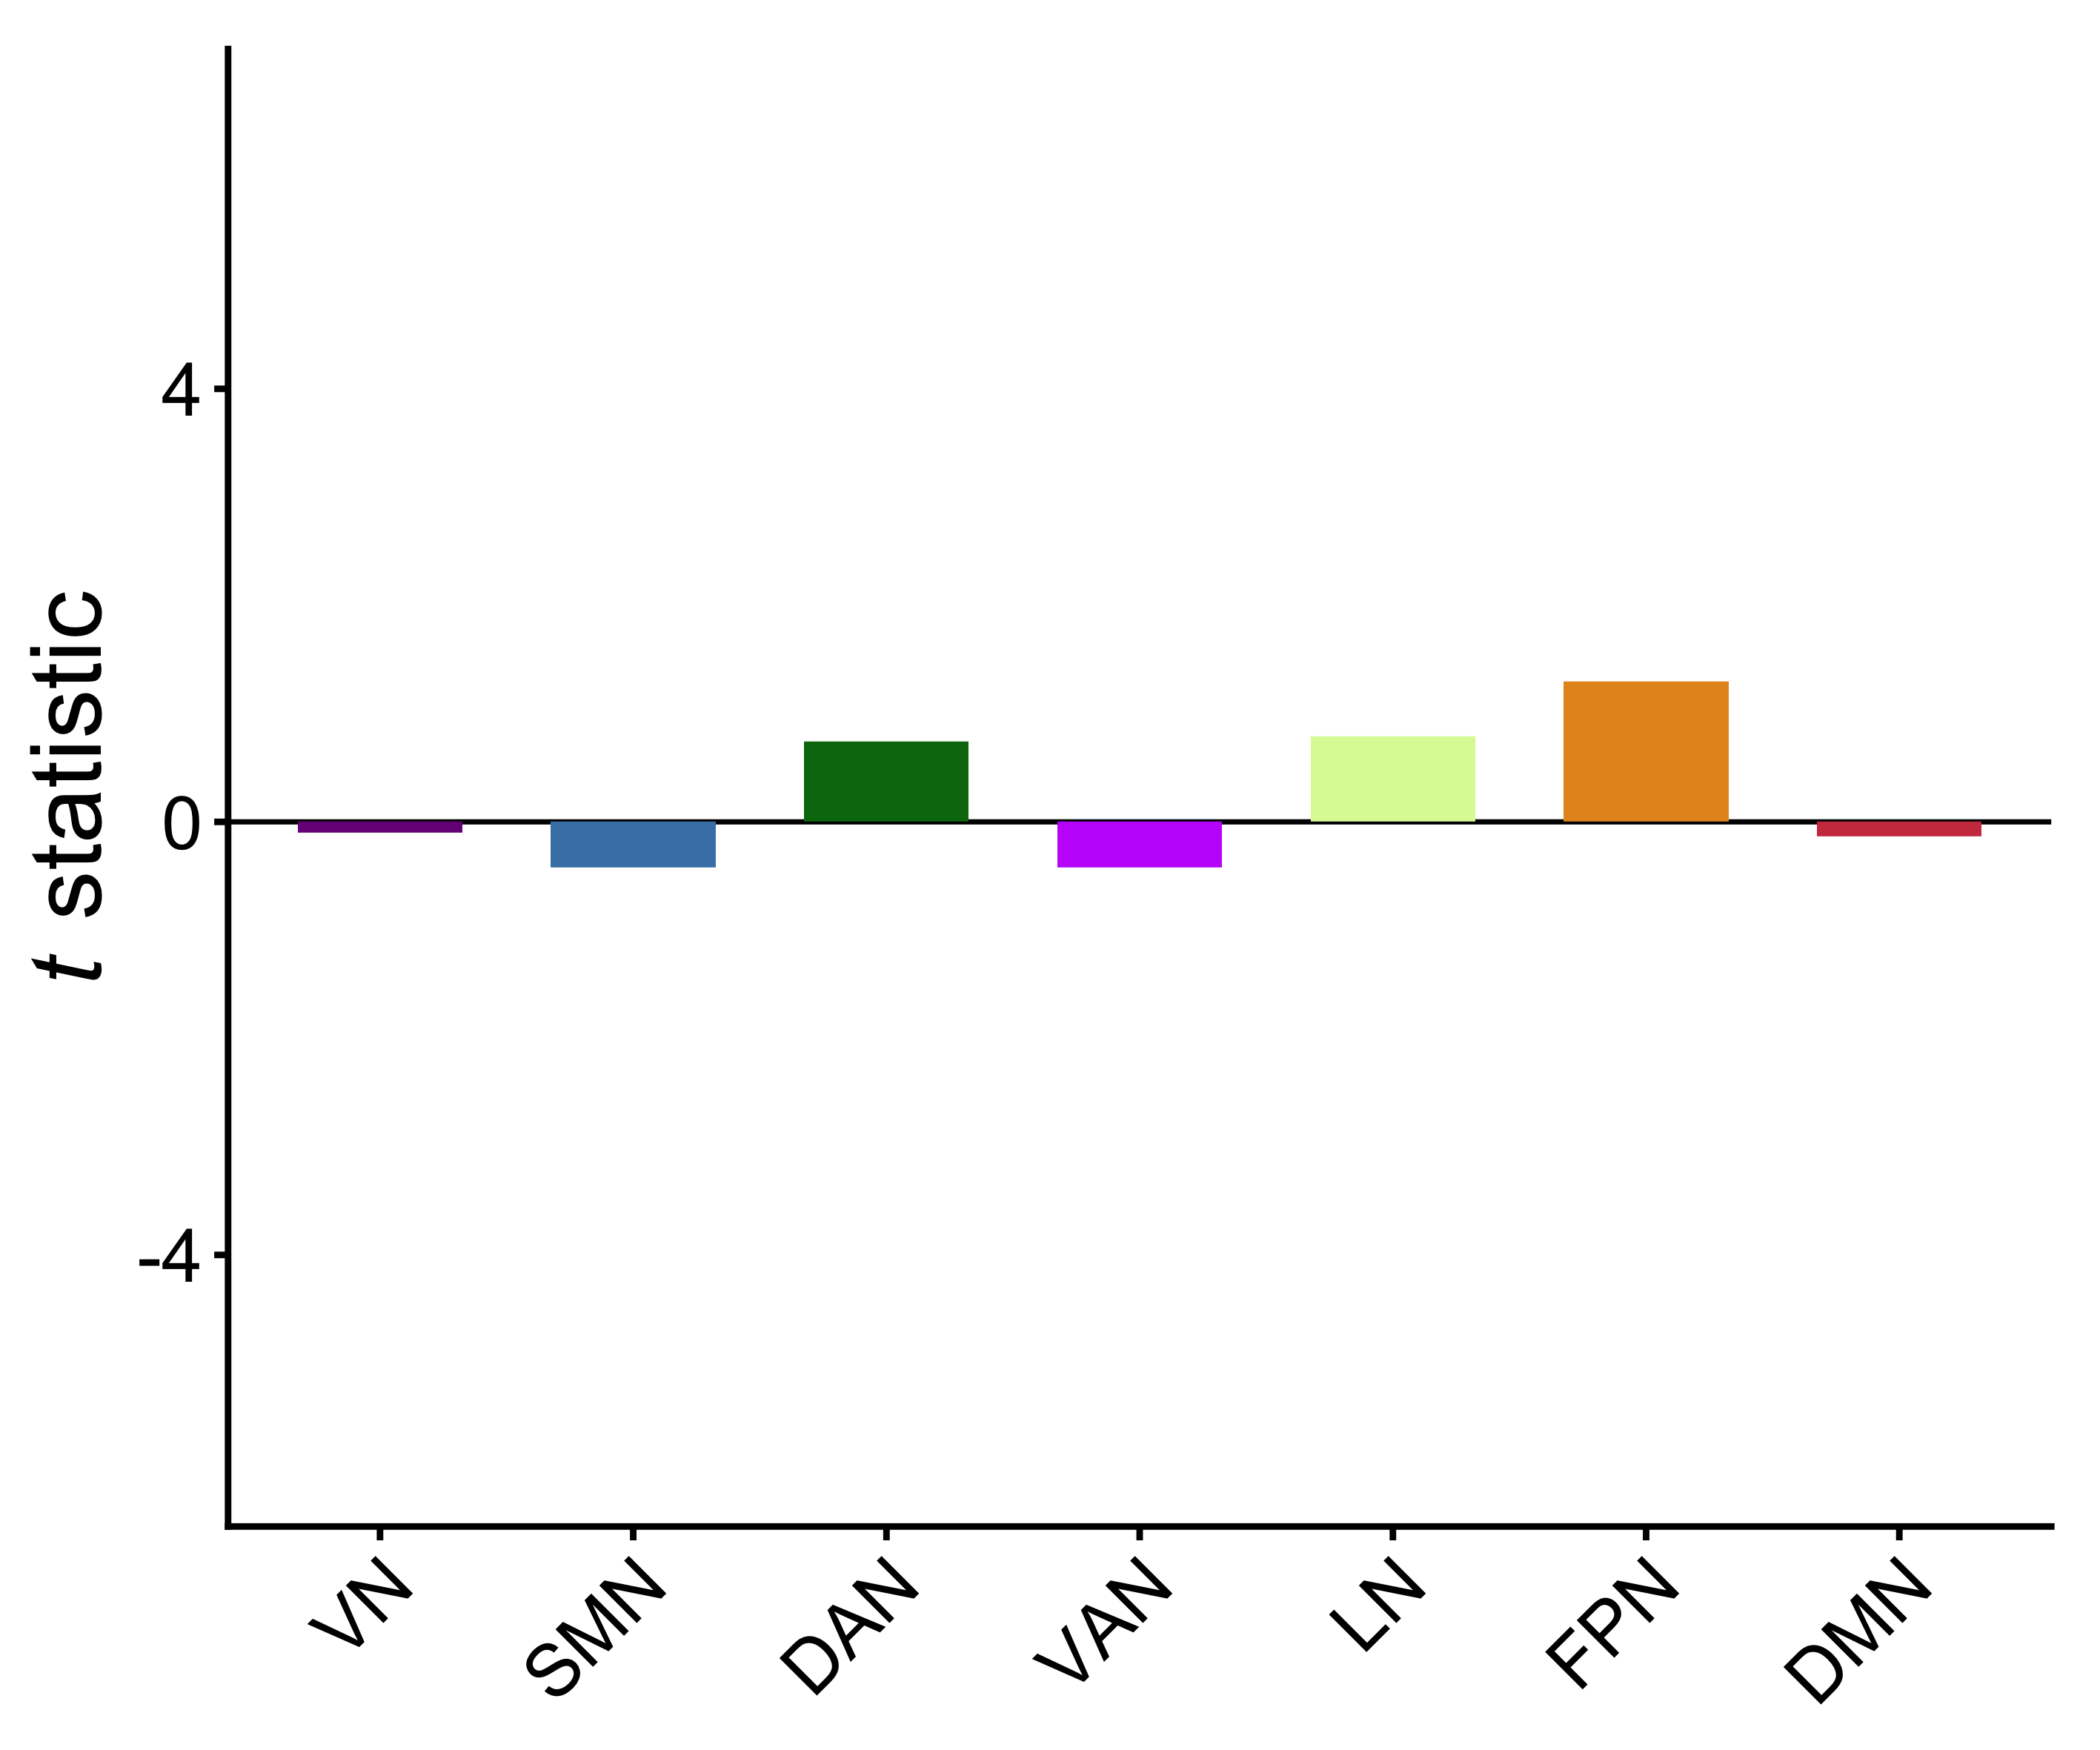

Suzhou_MDD_positive_gt3p29_cluster3_n33_mask.func_FunSurfWglobalCF_network_tstat_bar.png


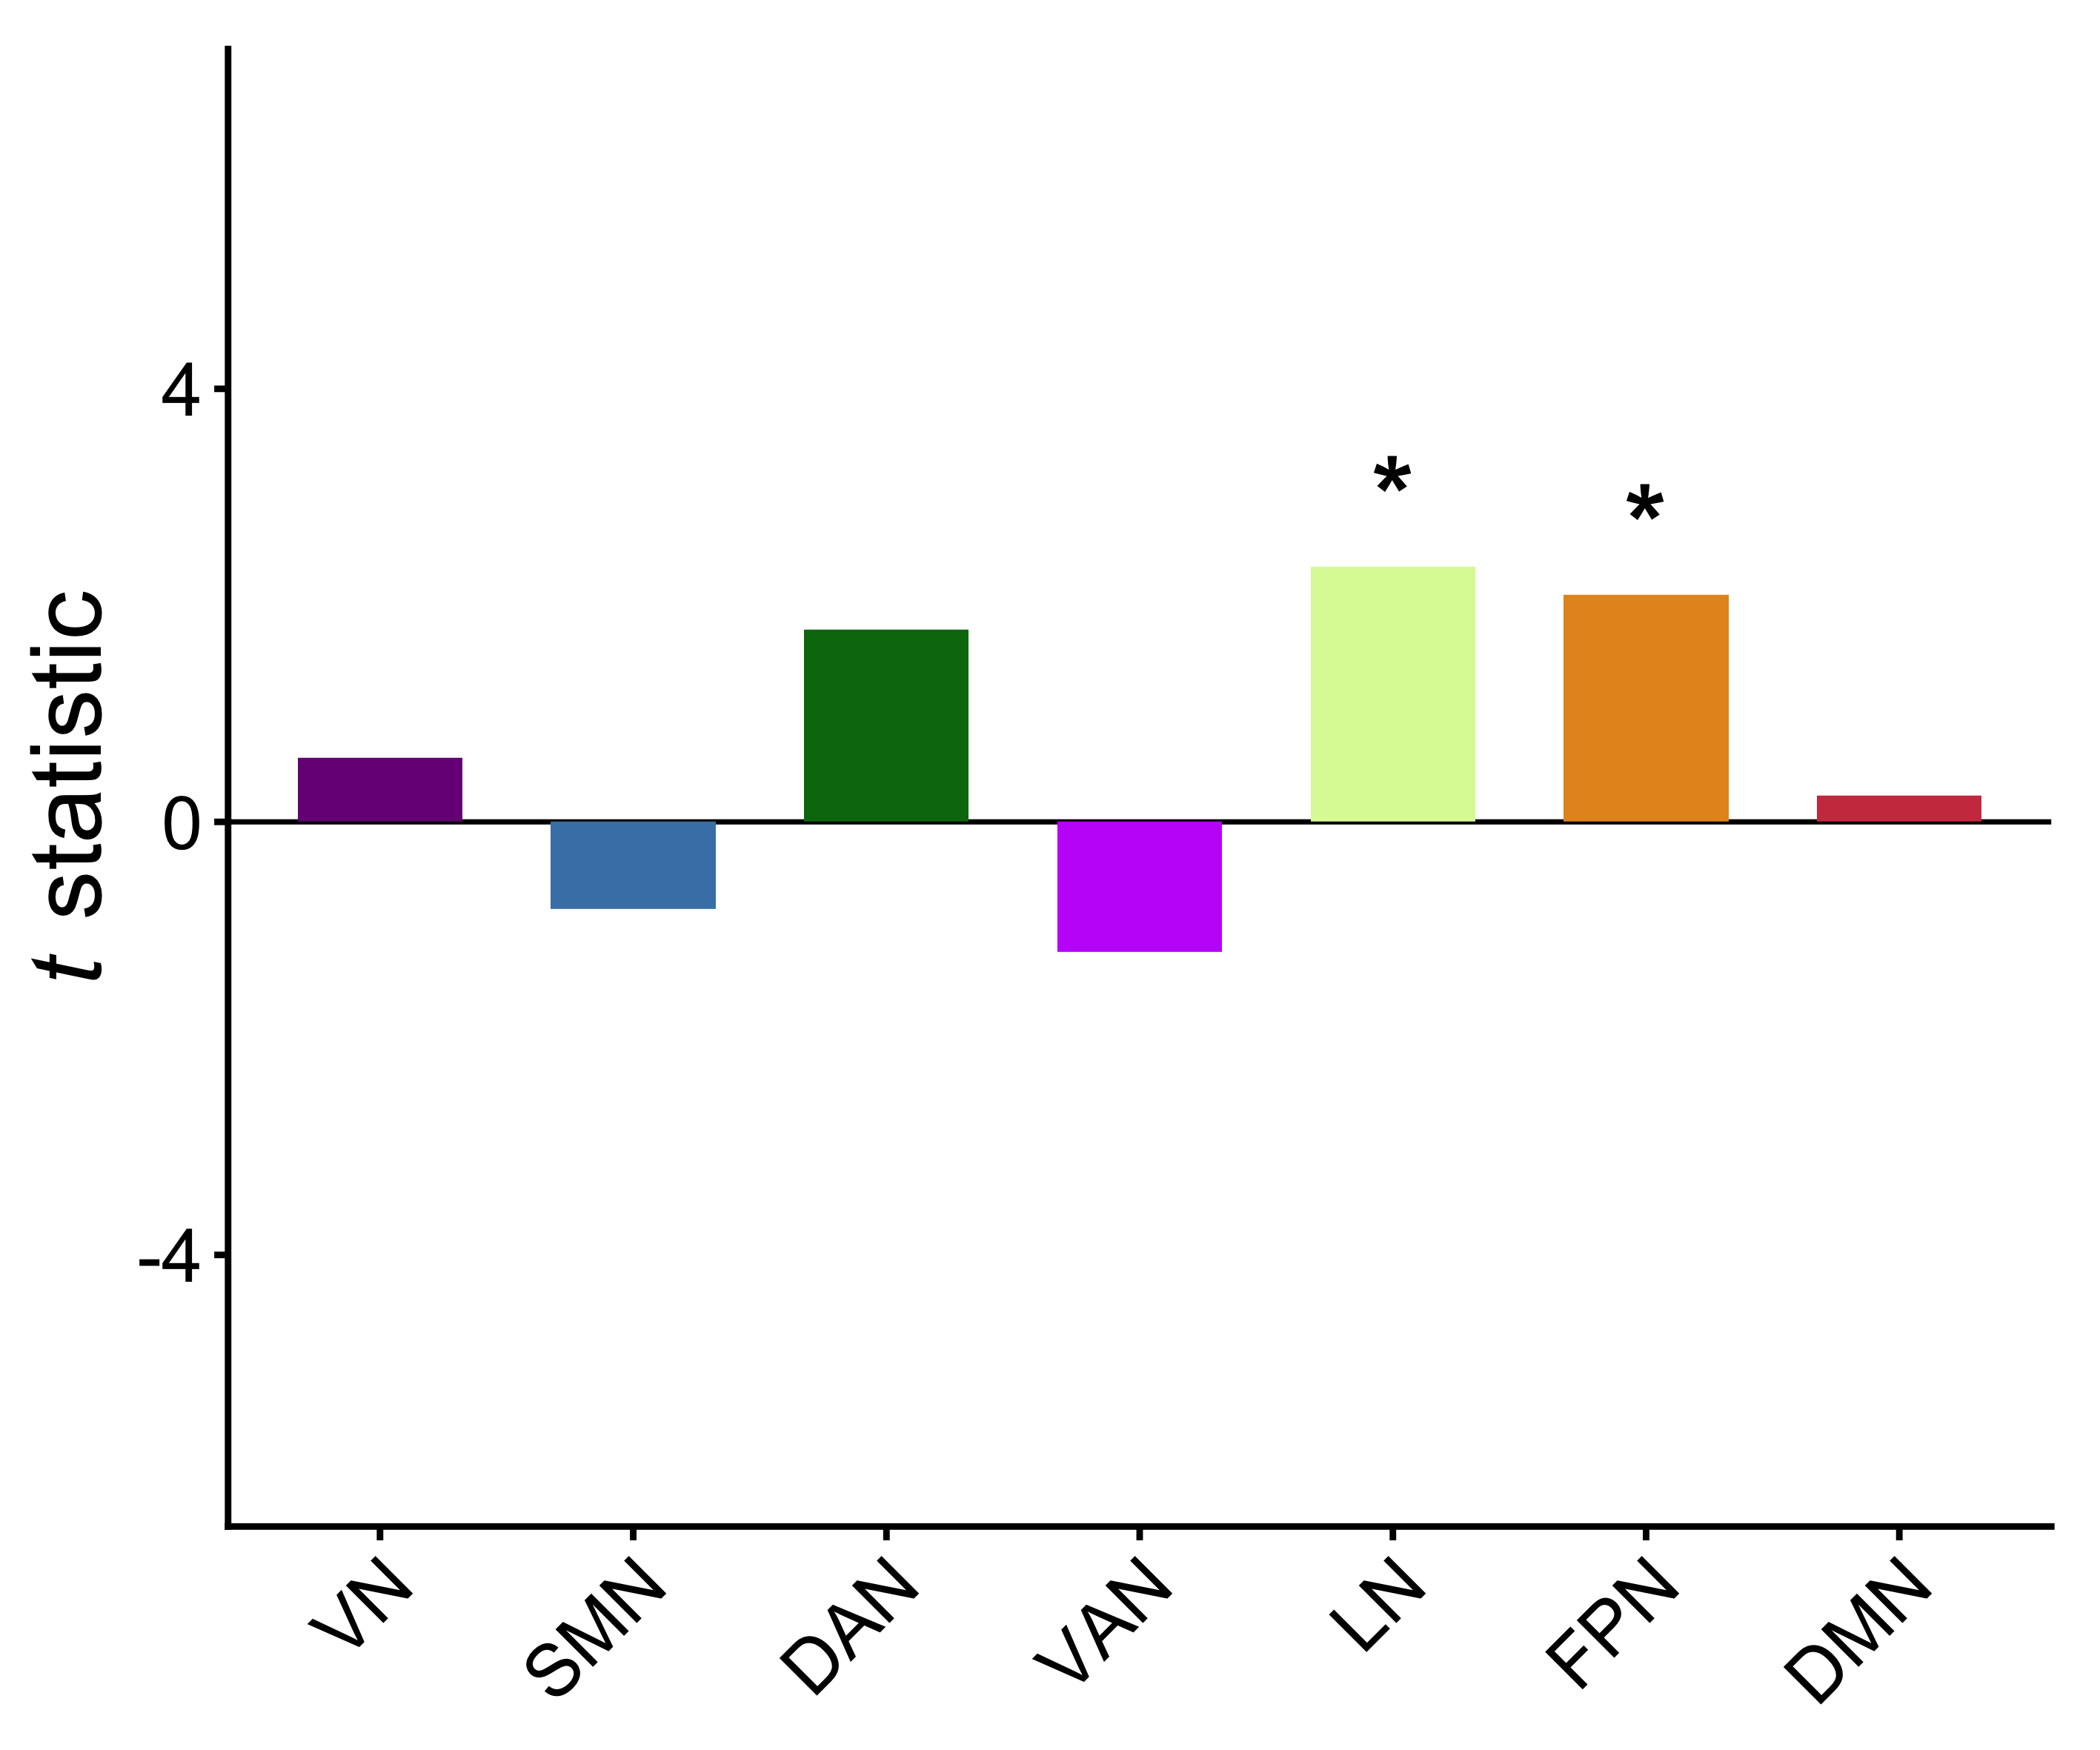

Suzhou_HC_positive_gt3p29_cluster1_n69_mask.func_FunSurfWCF_network_tstat_bar.png


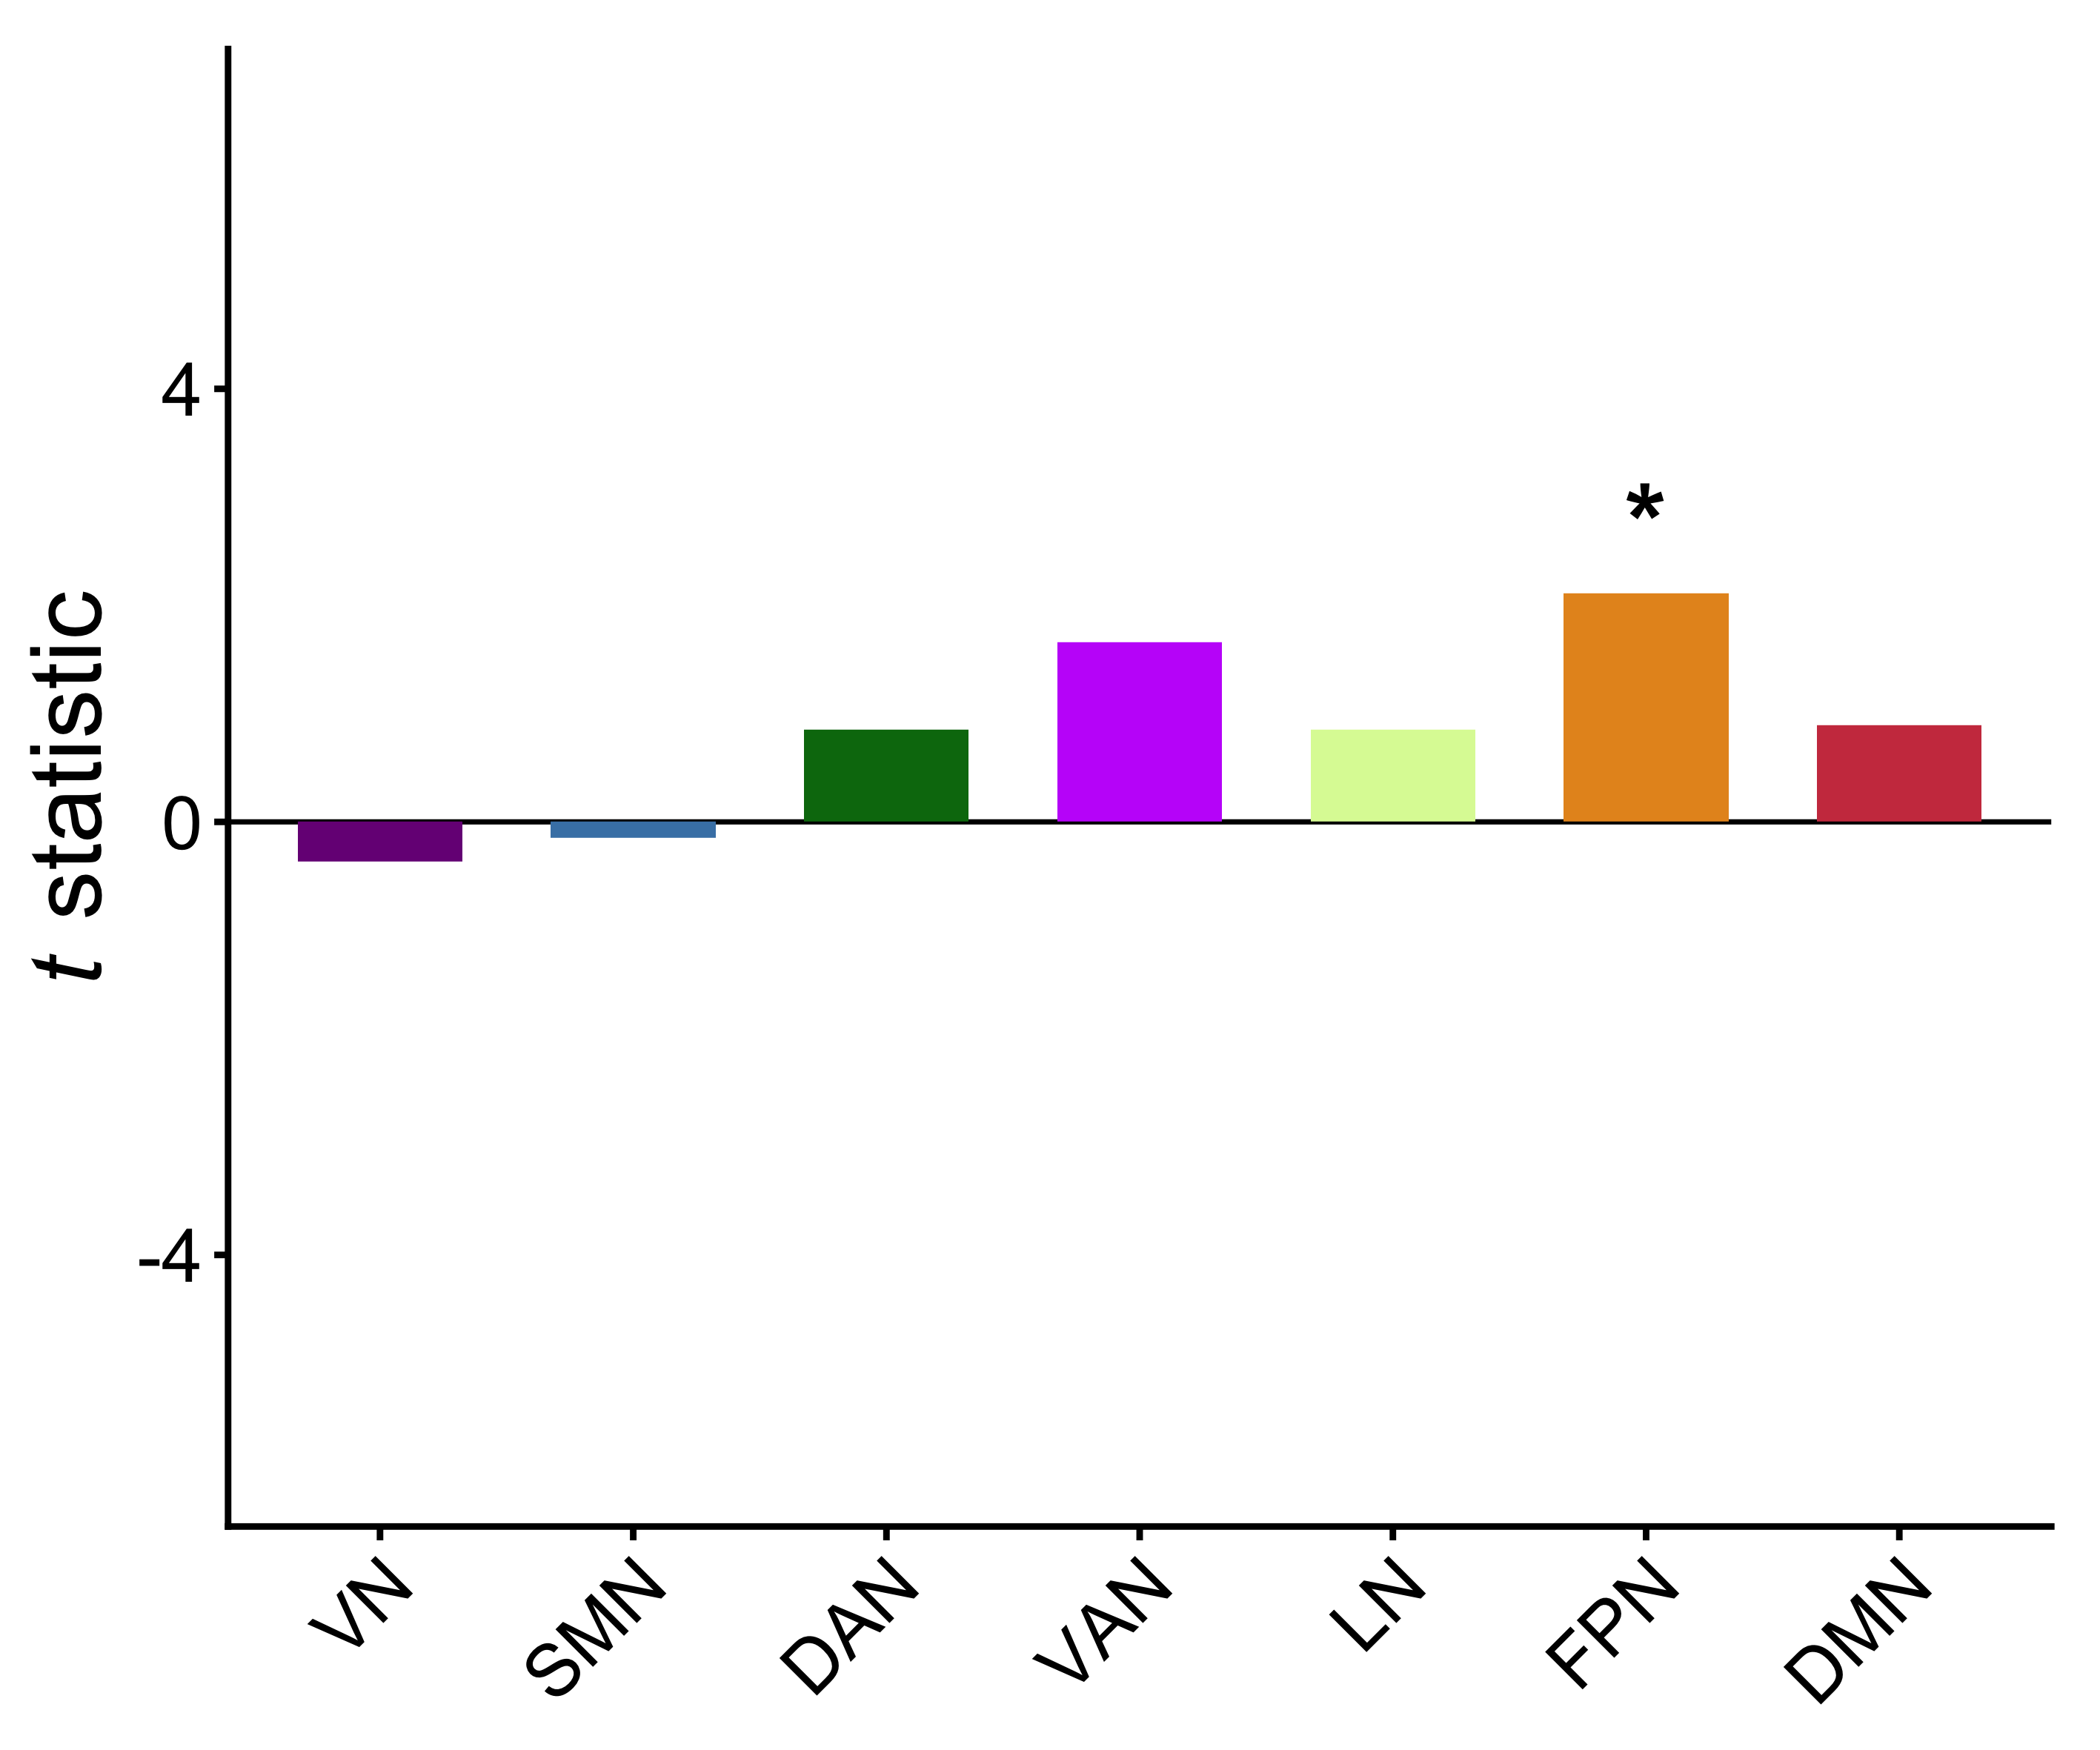

Suzhou_HC_positive_gt3p29_cluster1_n69_mask.func_FunSurfWglobalCF_network_tstat_bar.png


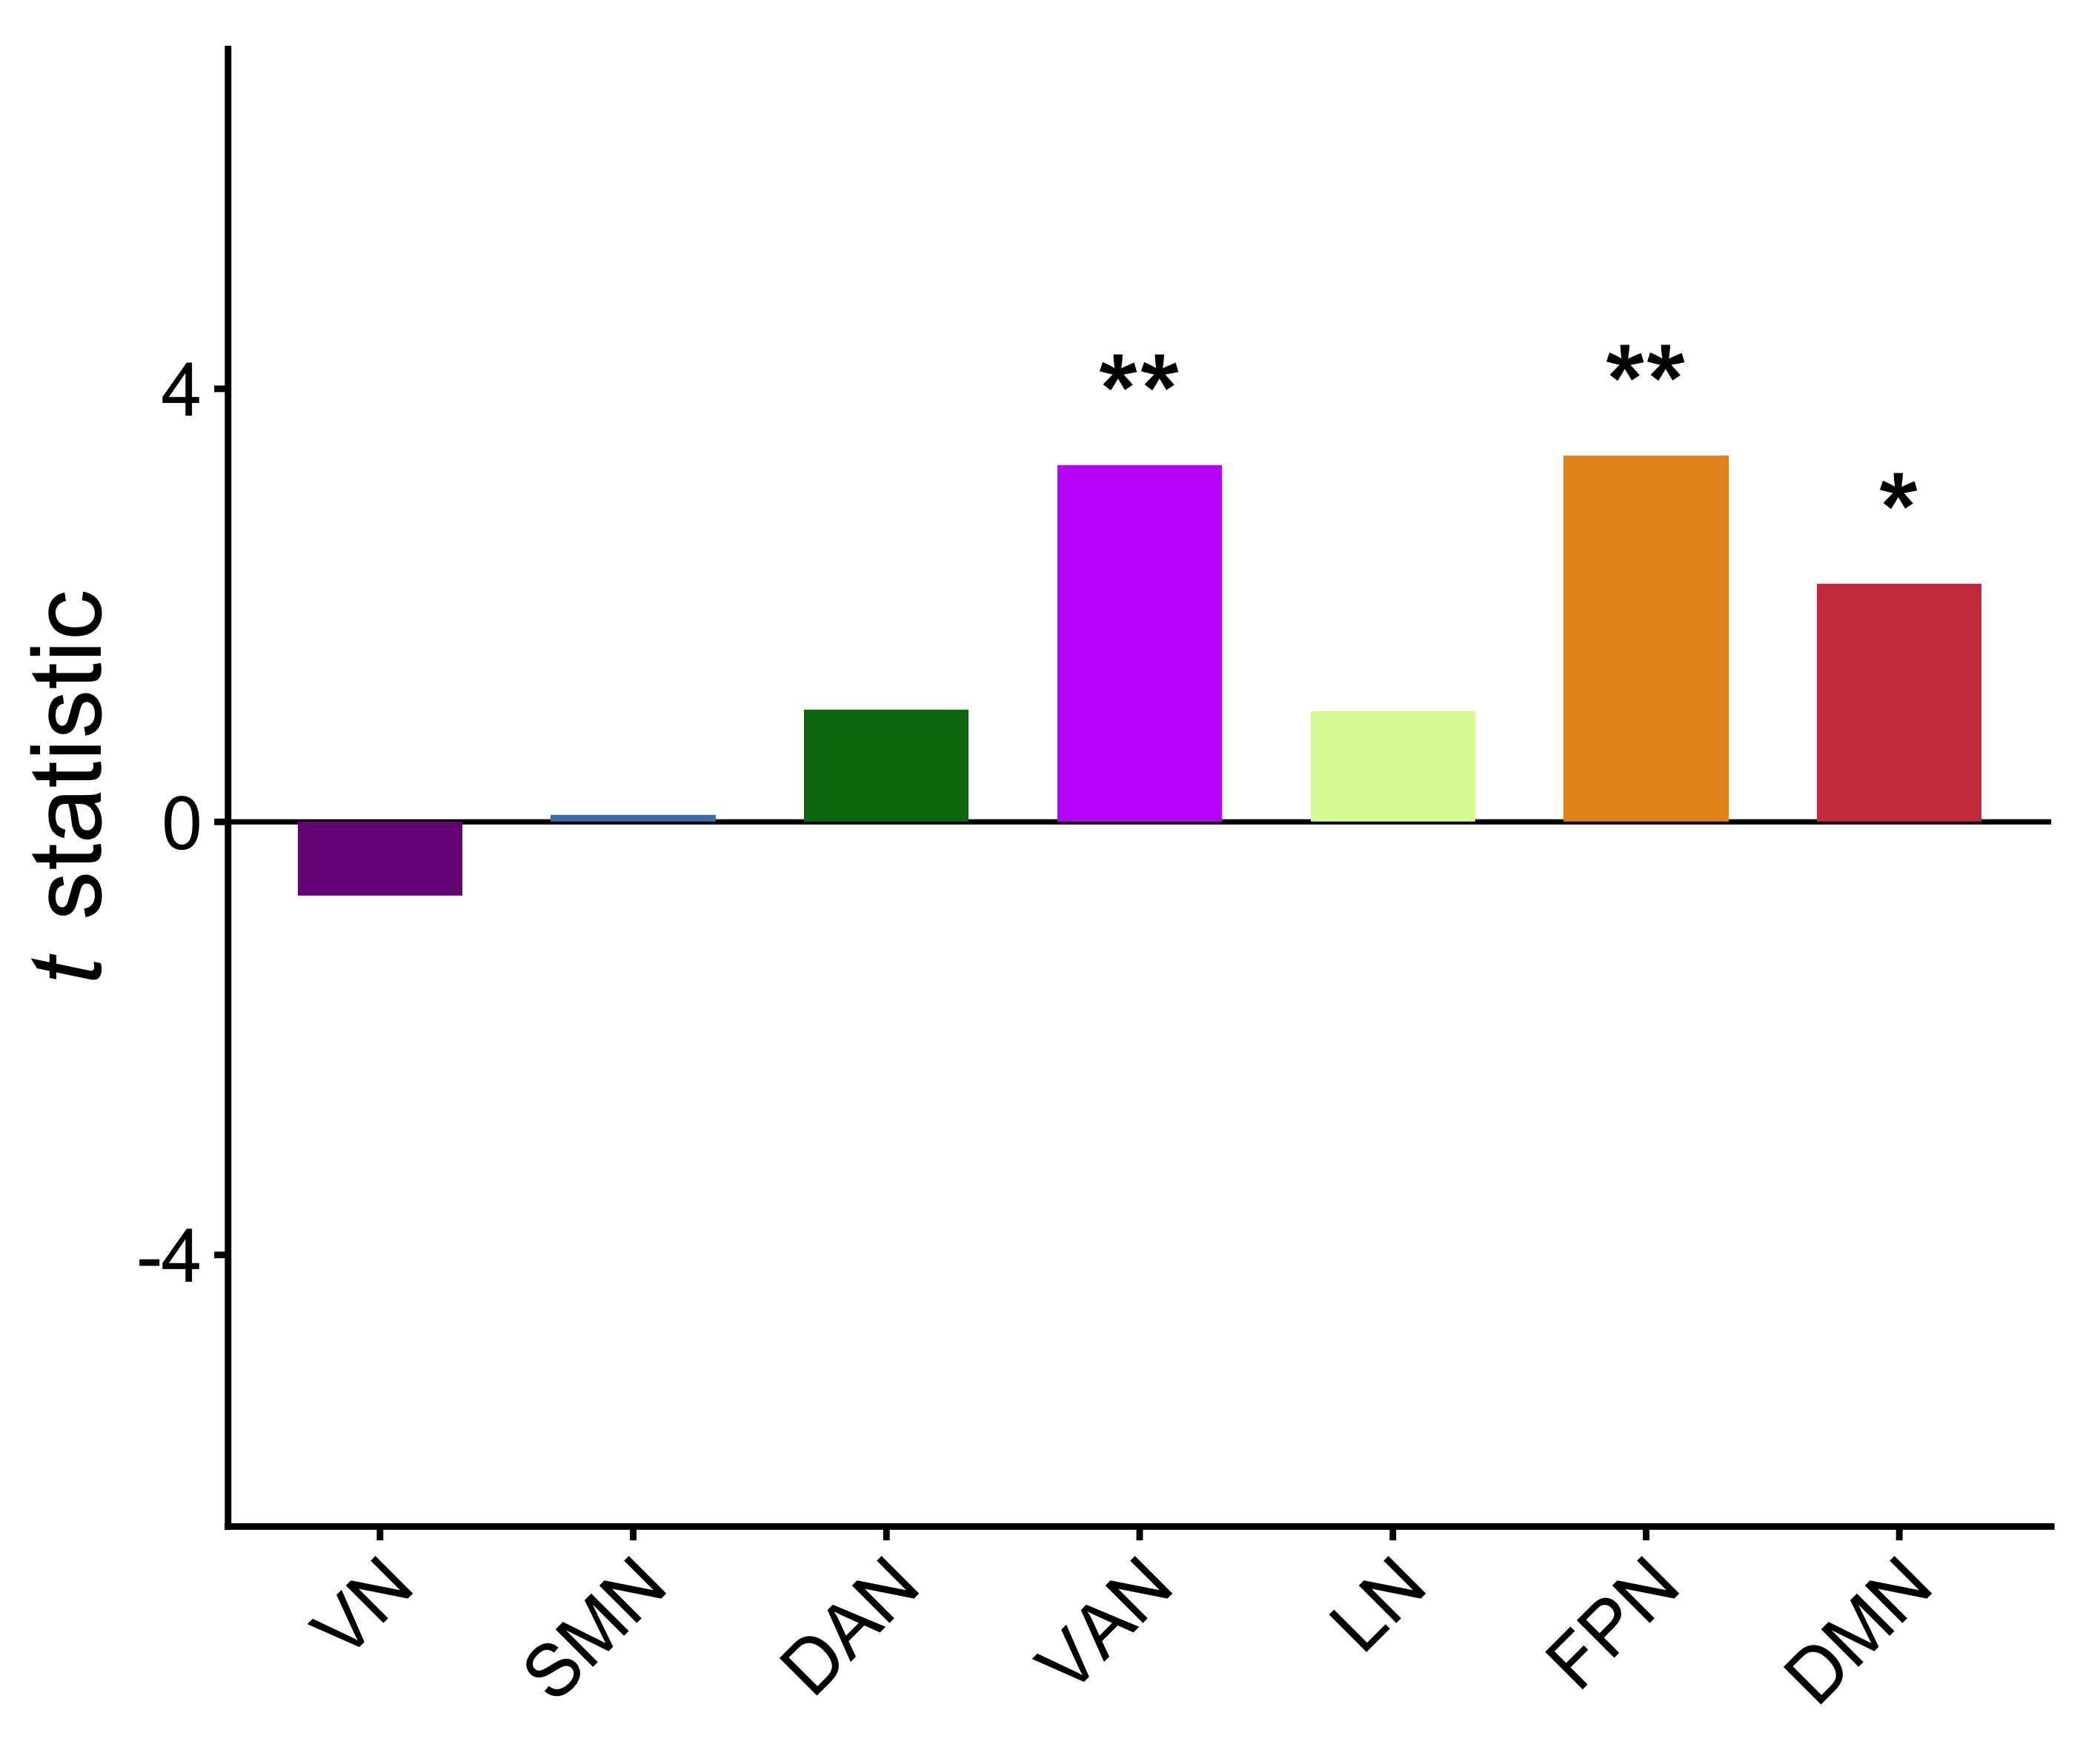

Suzhou_HC_positive_gt3p29_cluster2_n50_mask.func_FunSurfWCF_network_tstat_bar.png


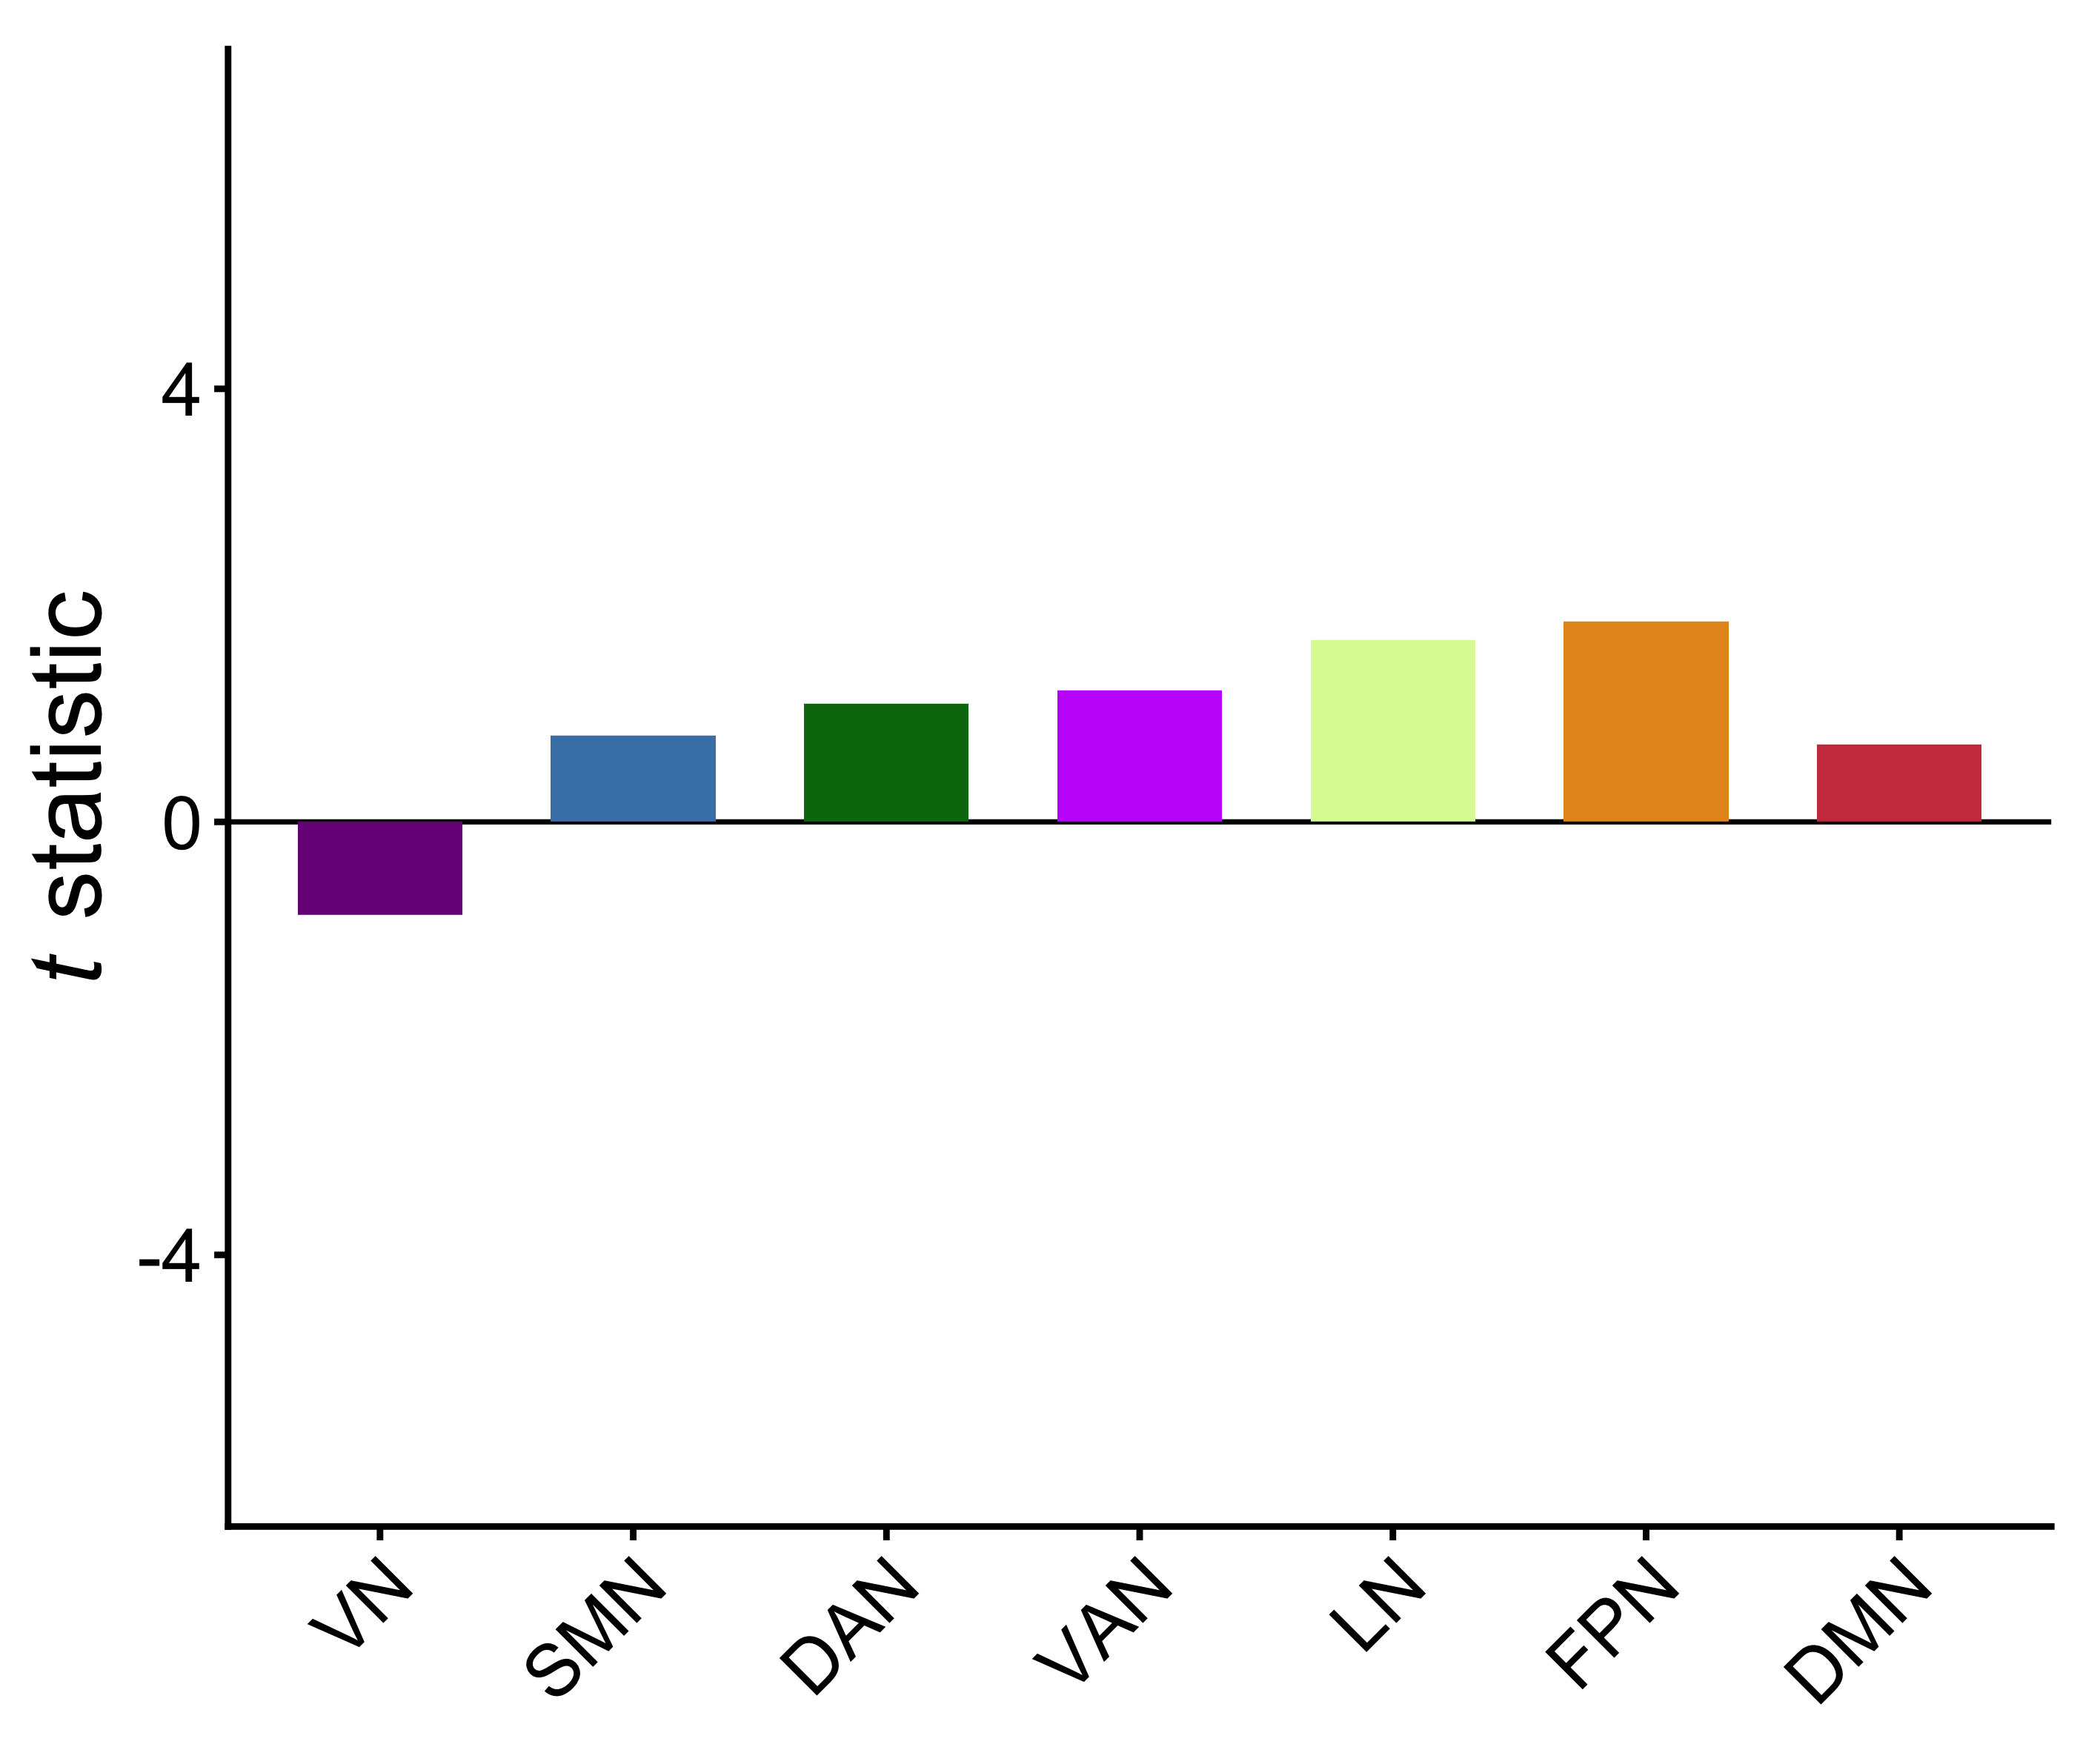

Suzhou_HC_positive_gt3p29_cluster2_n50_mask.func_FunSurfWglobalCF_network_tstat_bar.png


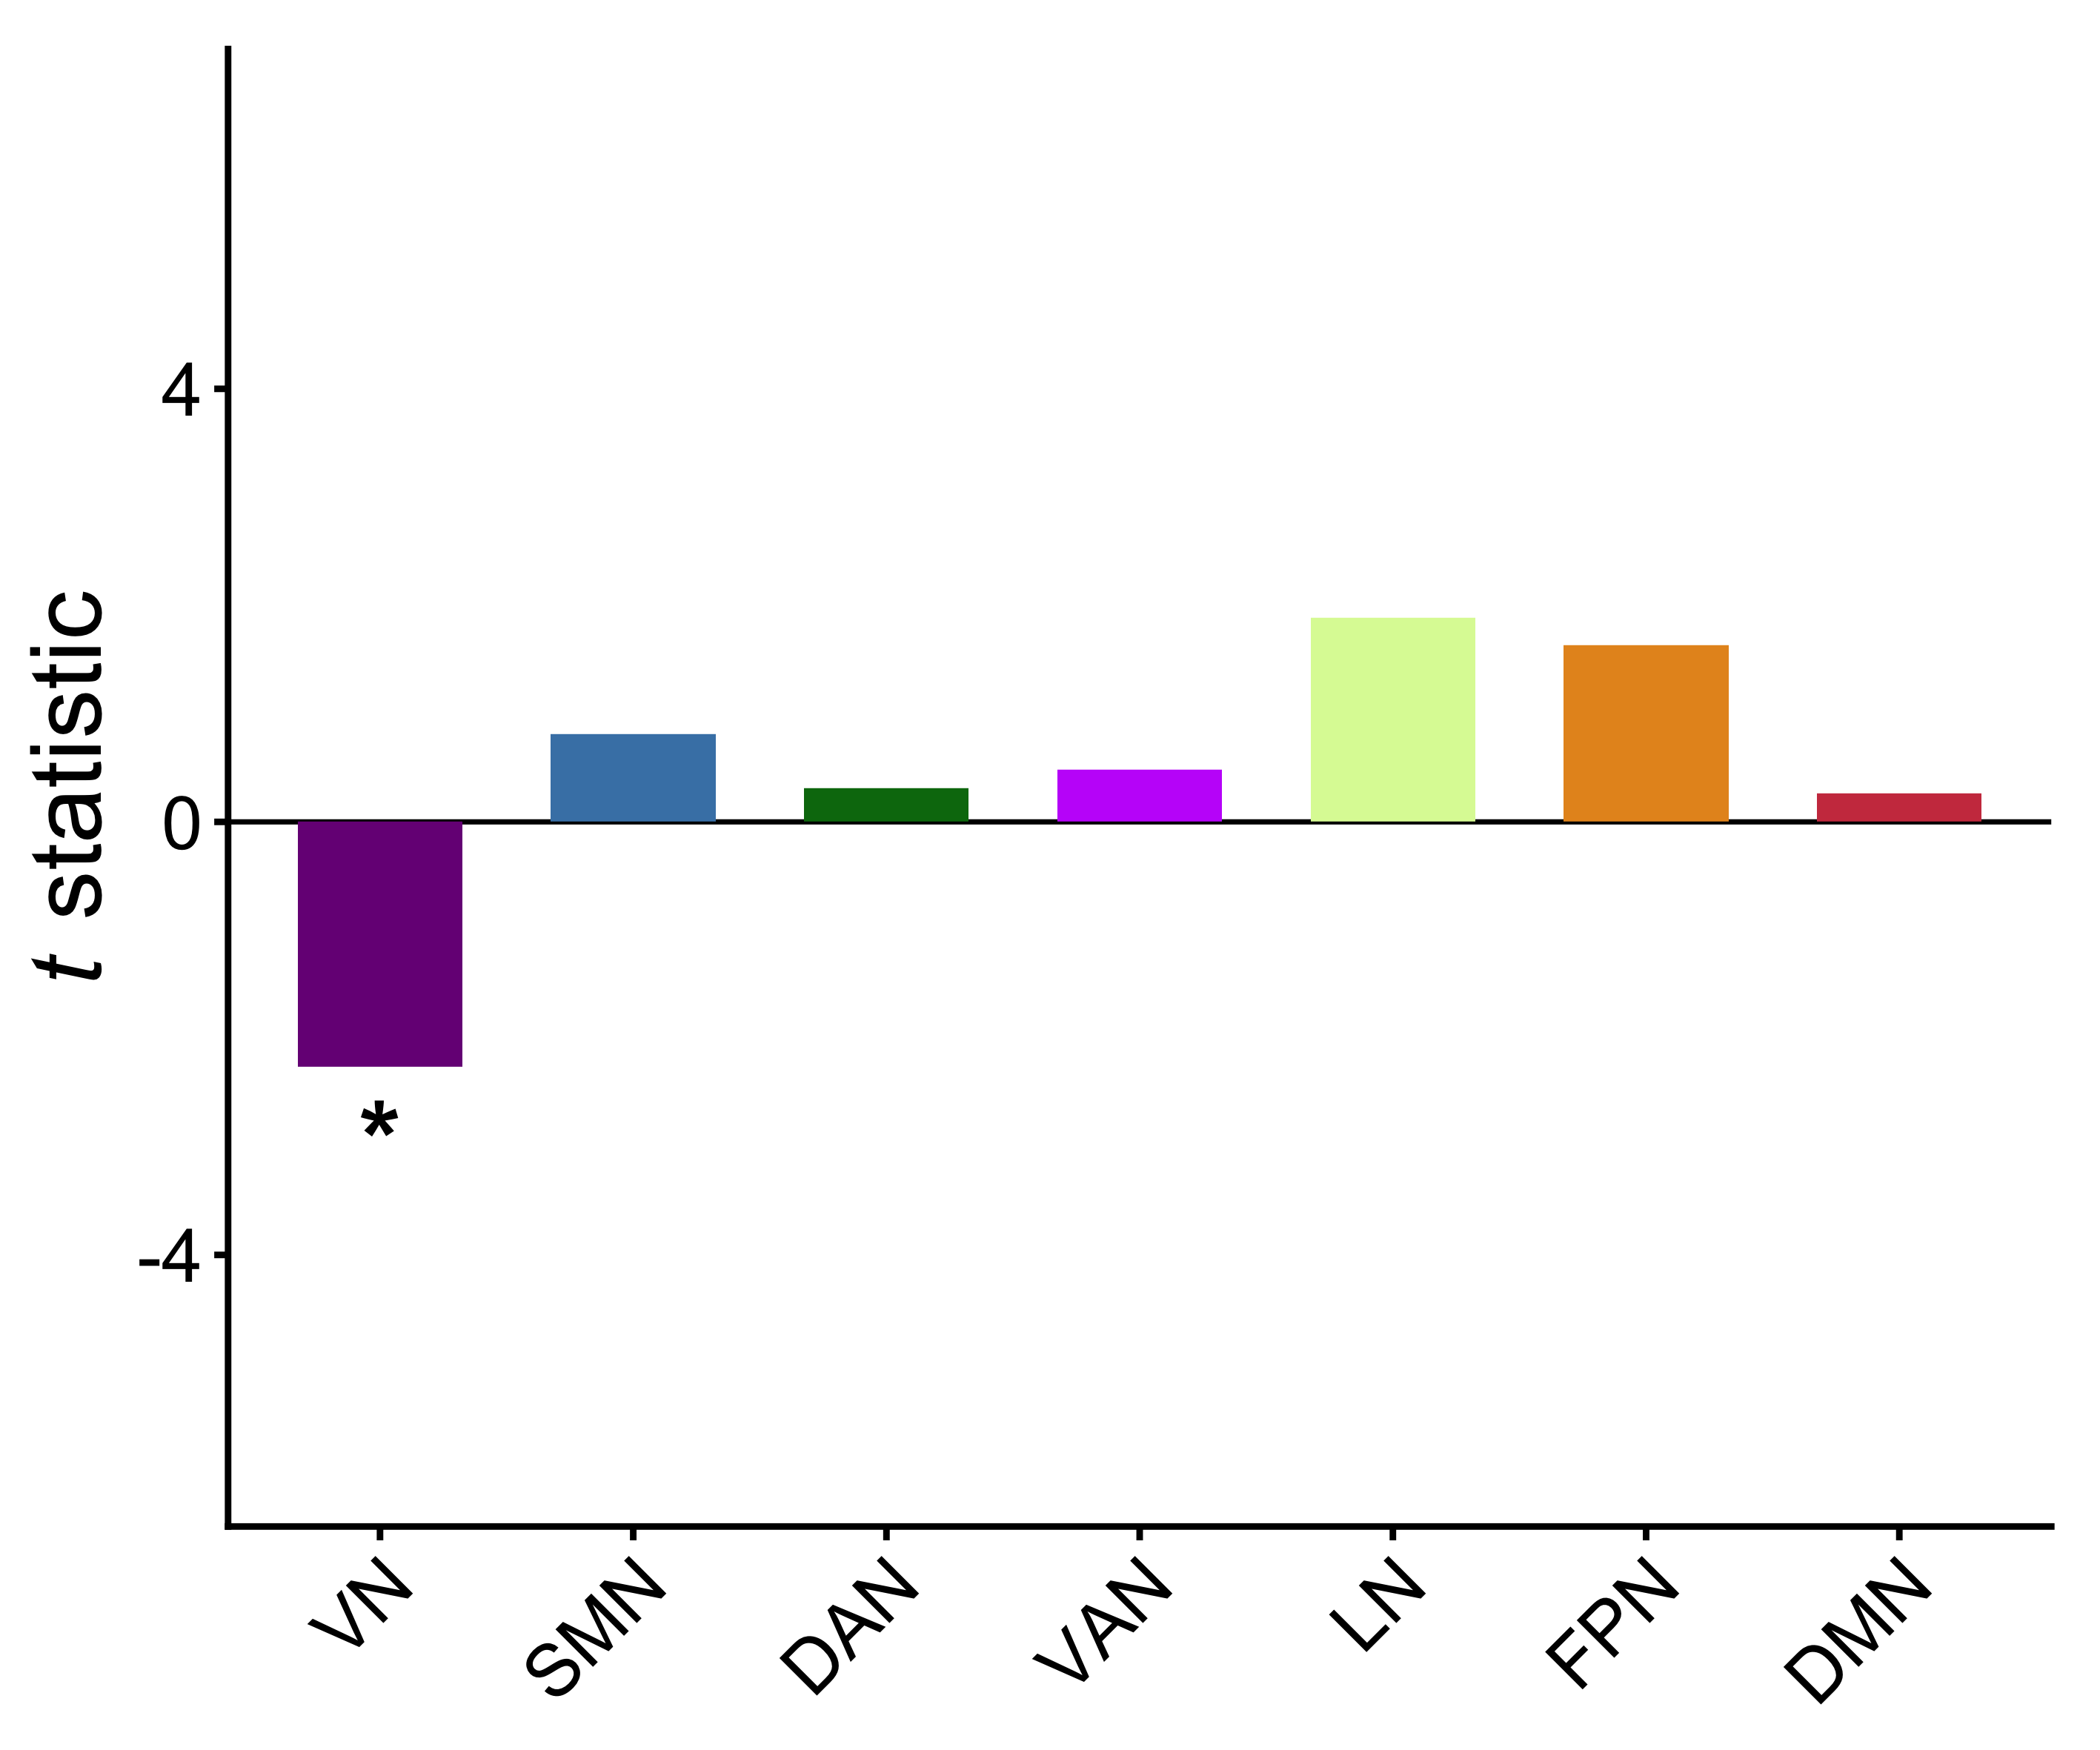

Suzhou_HC_positive_gt3p29_cluster3_n33_mask.func_FunSurfWCF_network_tstat_bar.png


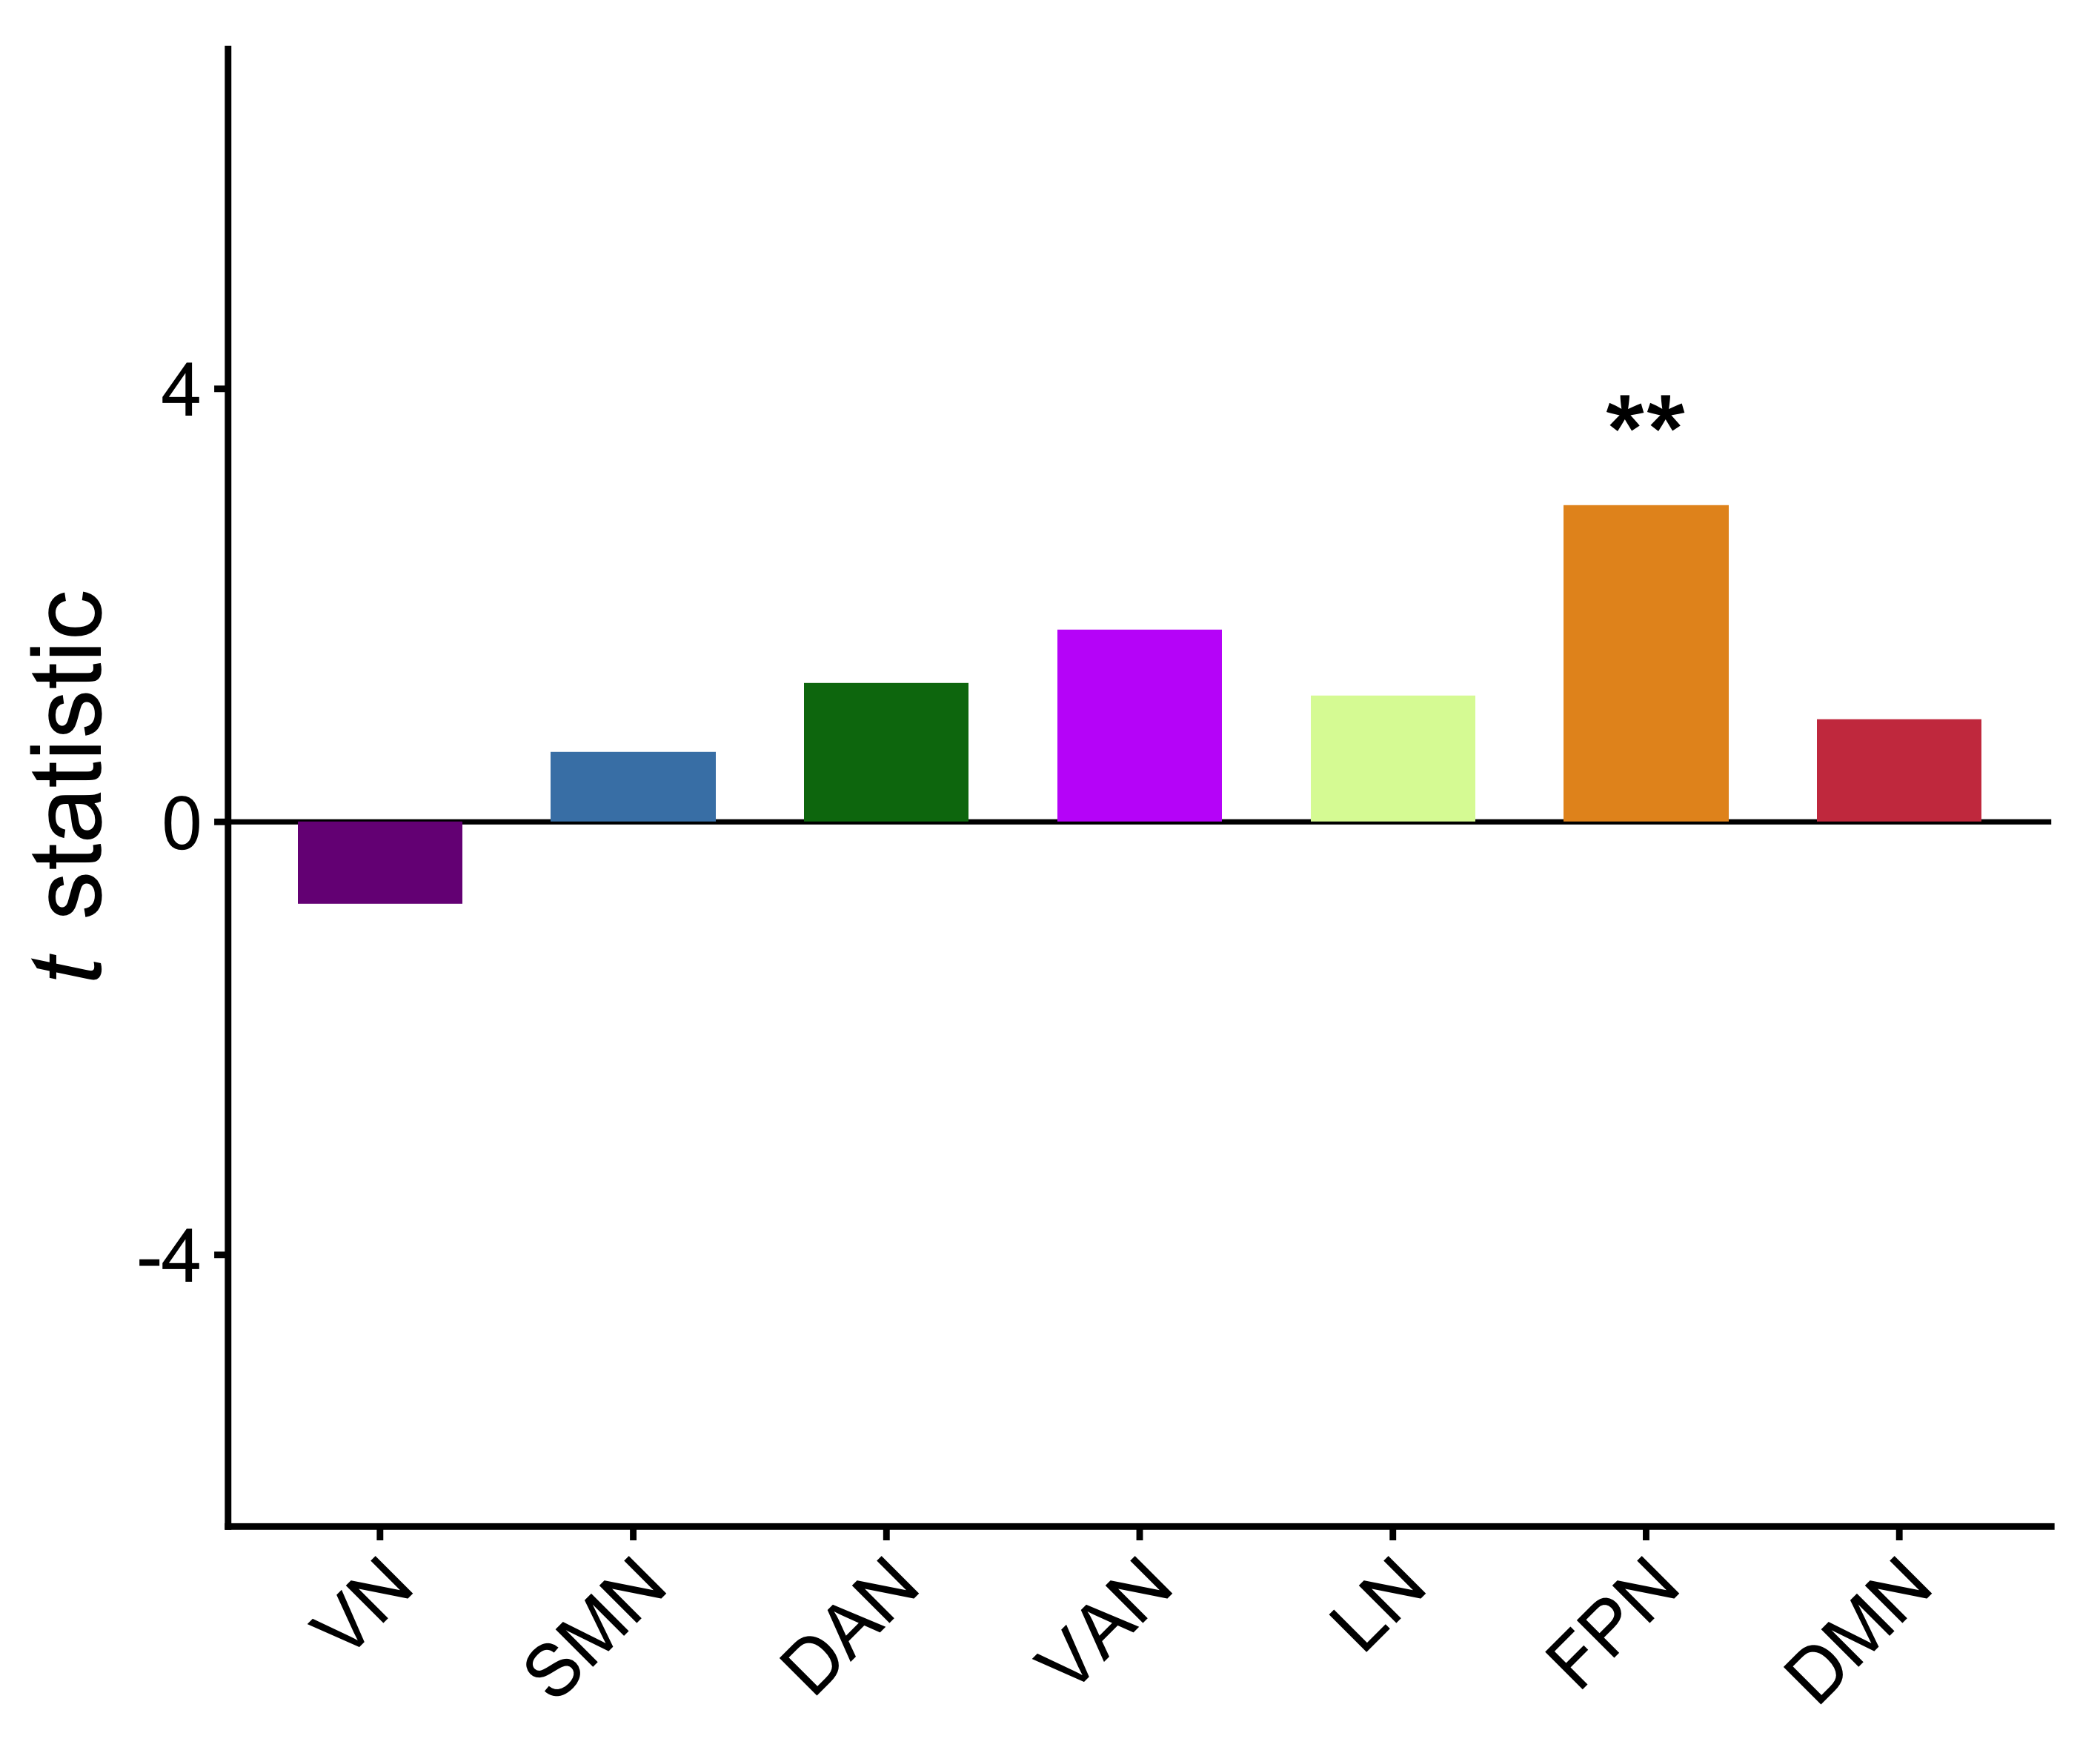

Suzhou_HC_positive_gt3p29_cluster3_n33_mask.func_FunSurfWglobalCF_network_tstat_bar.png


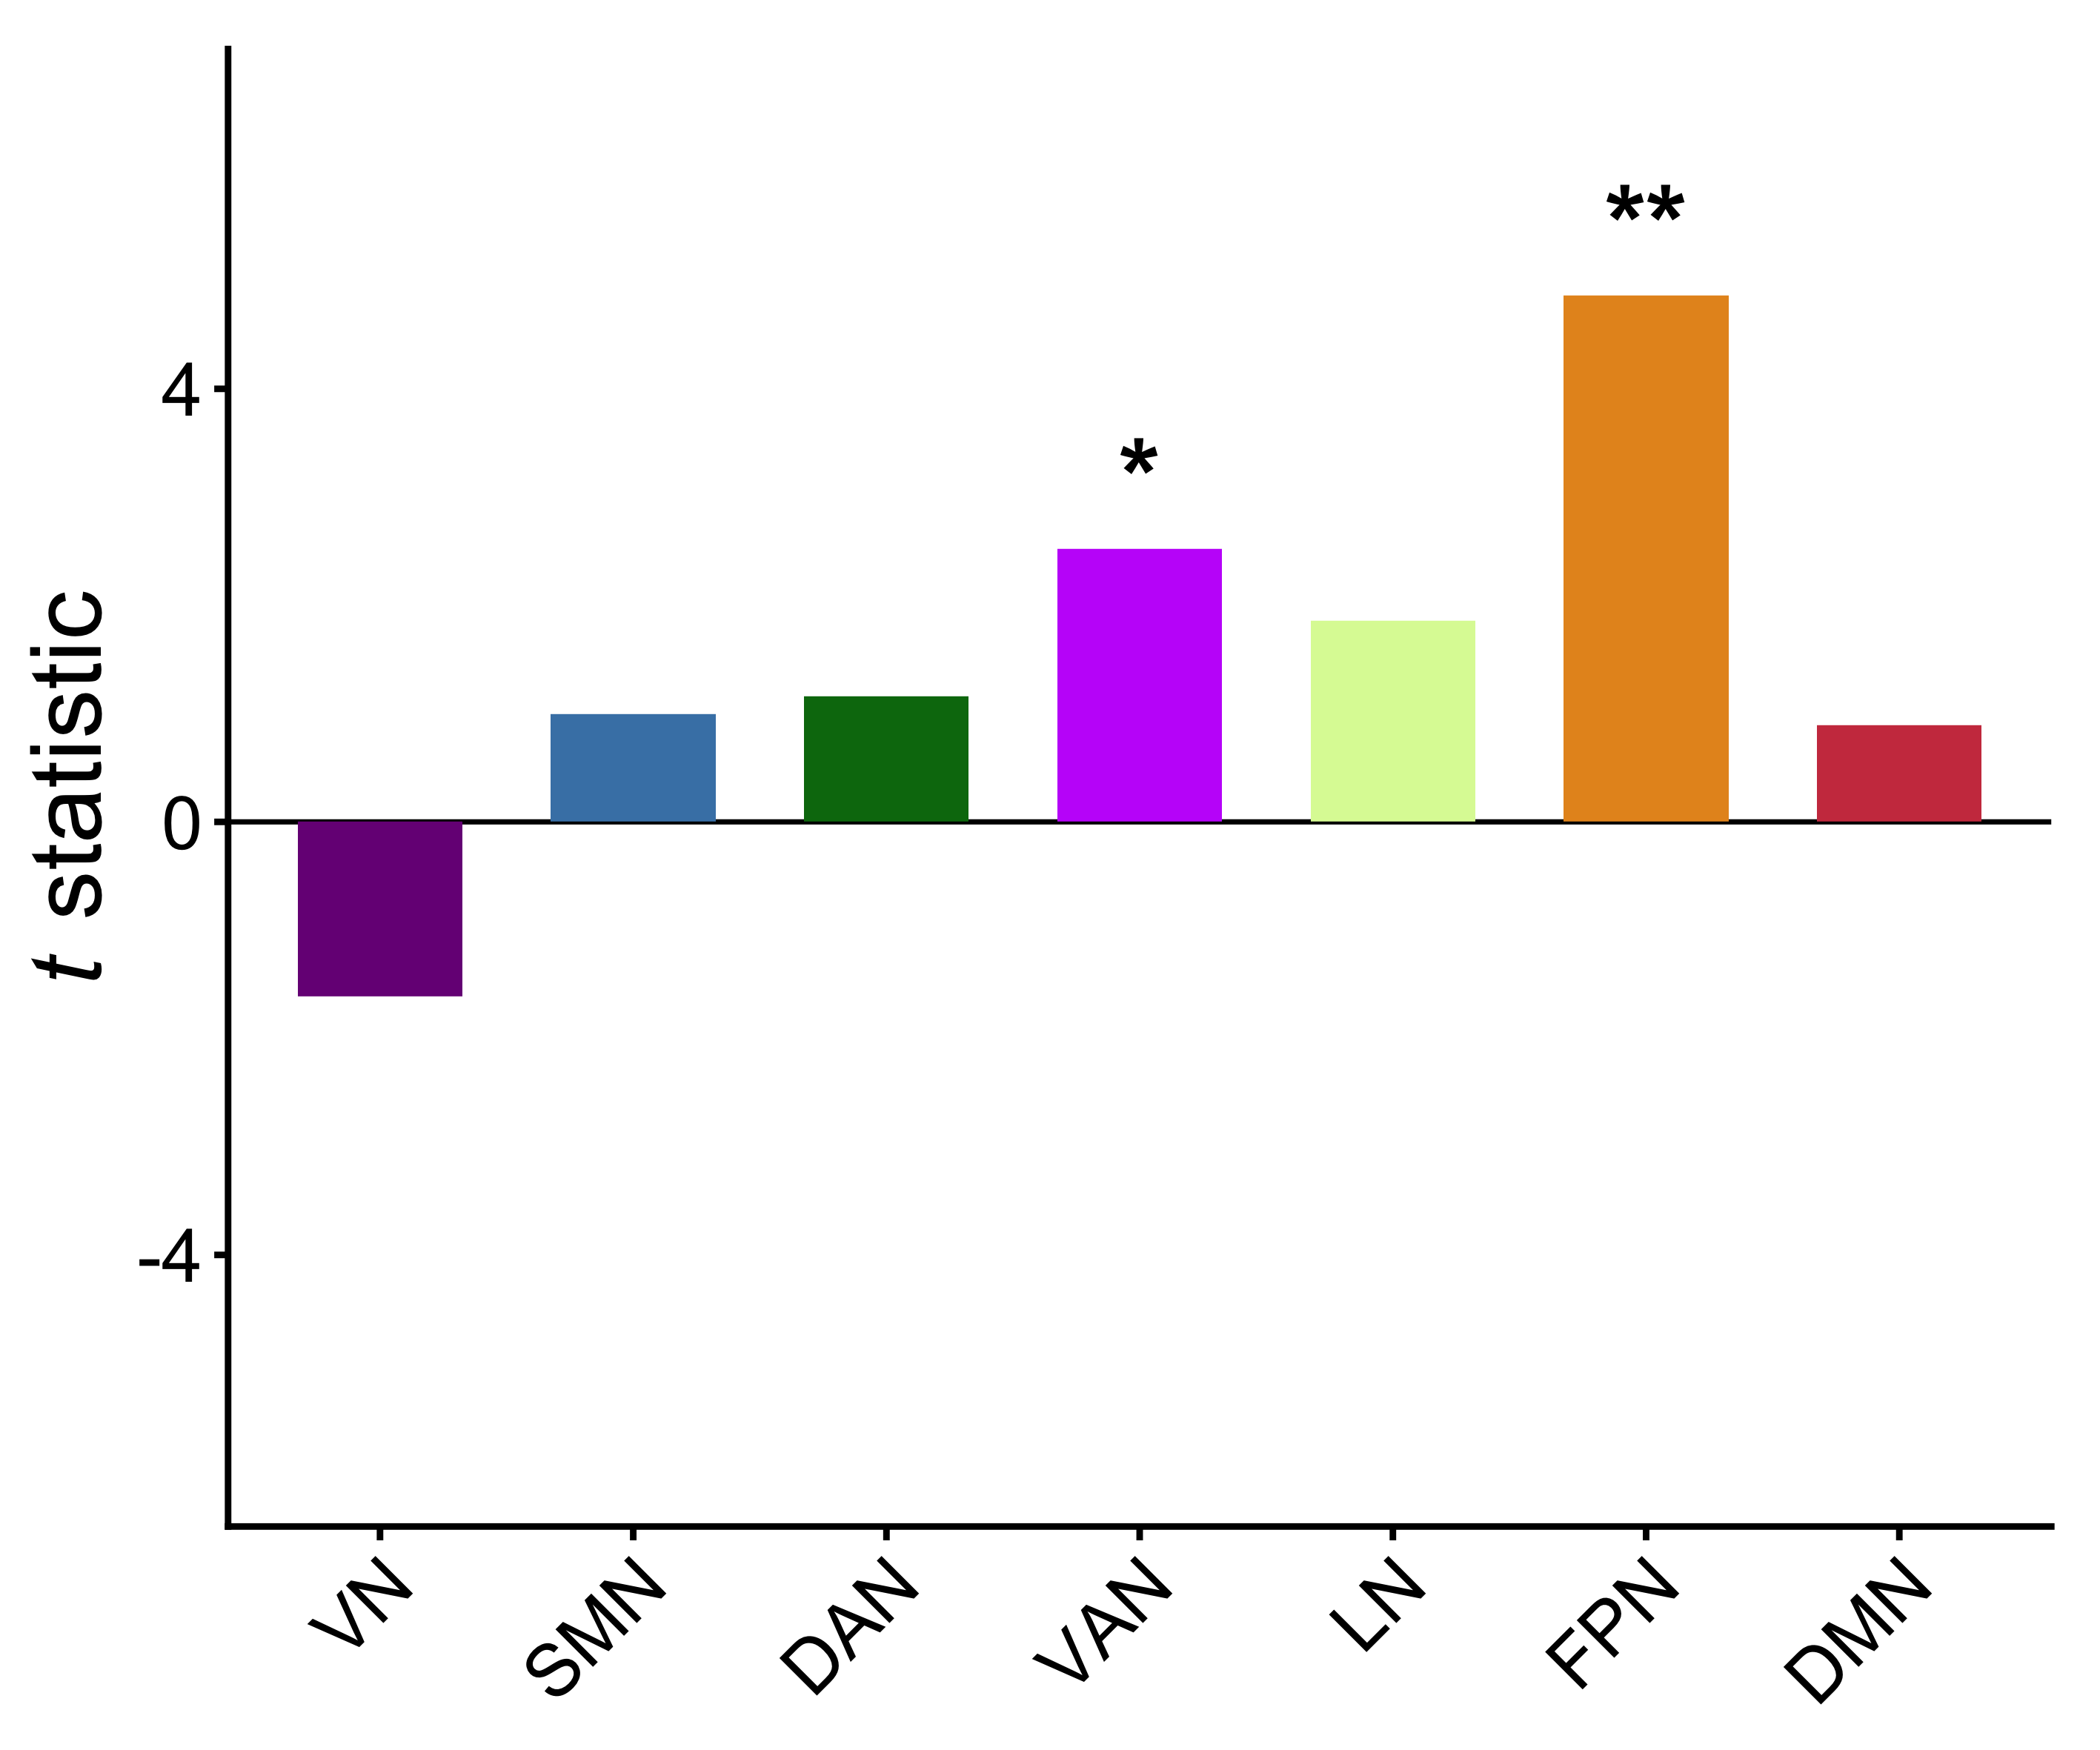

Beijing_IPCAS_positive_gt3p29_cluster1_n69_mask.func_FunSurfWCF_network_tstat_bar.png


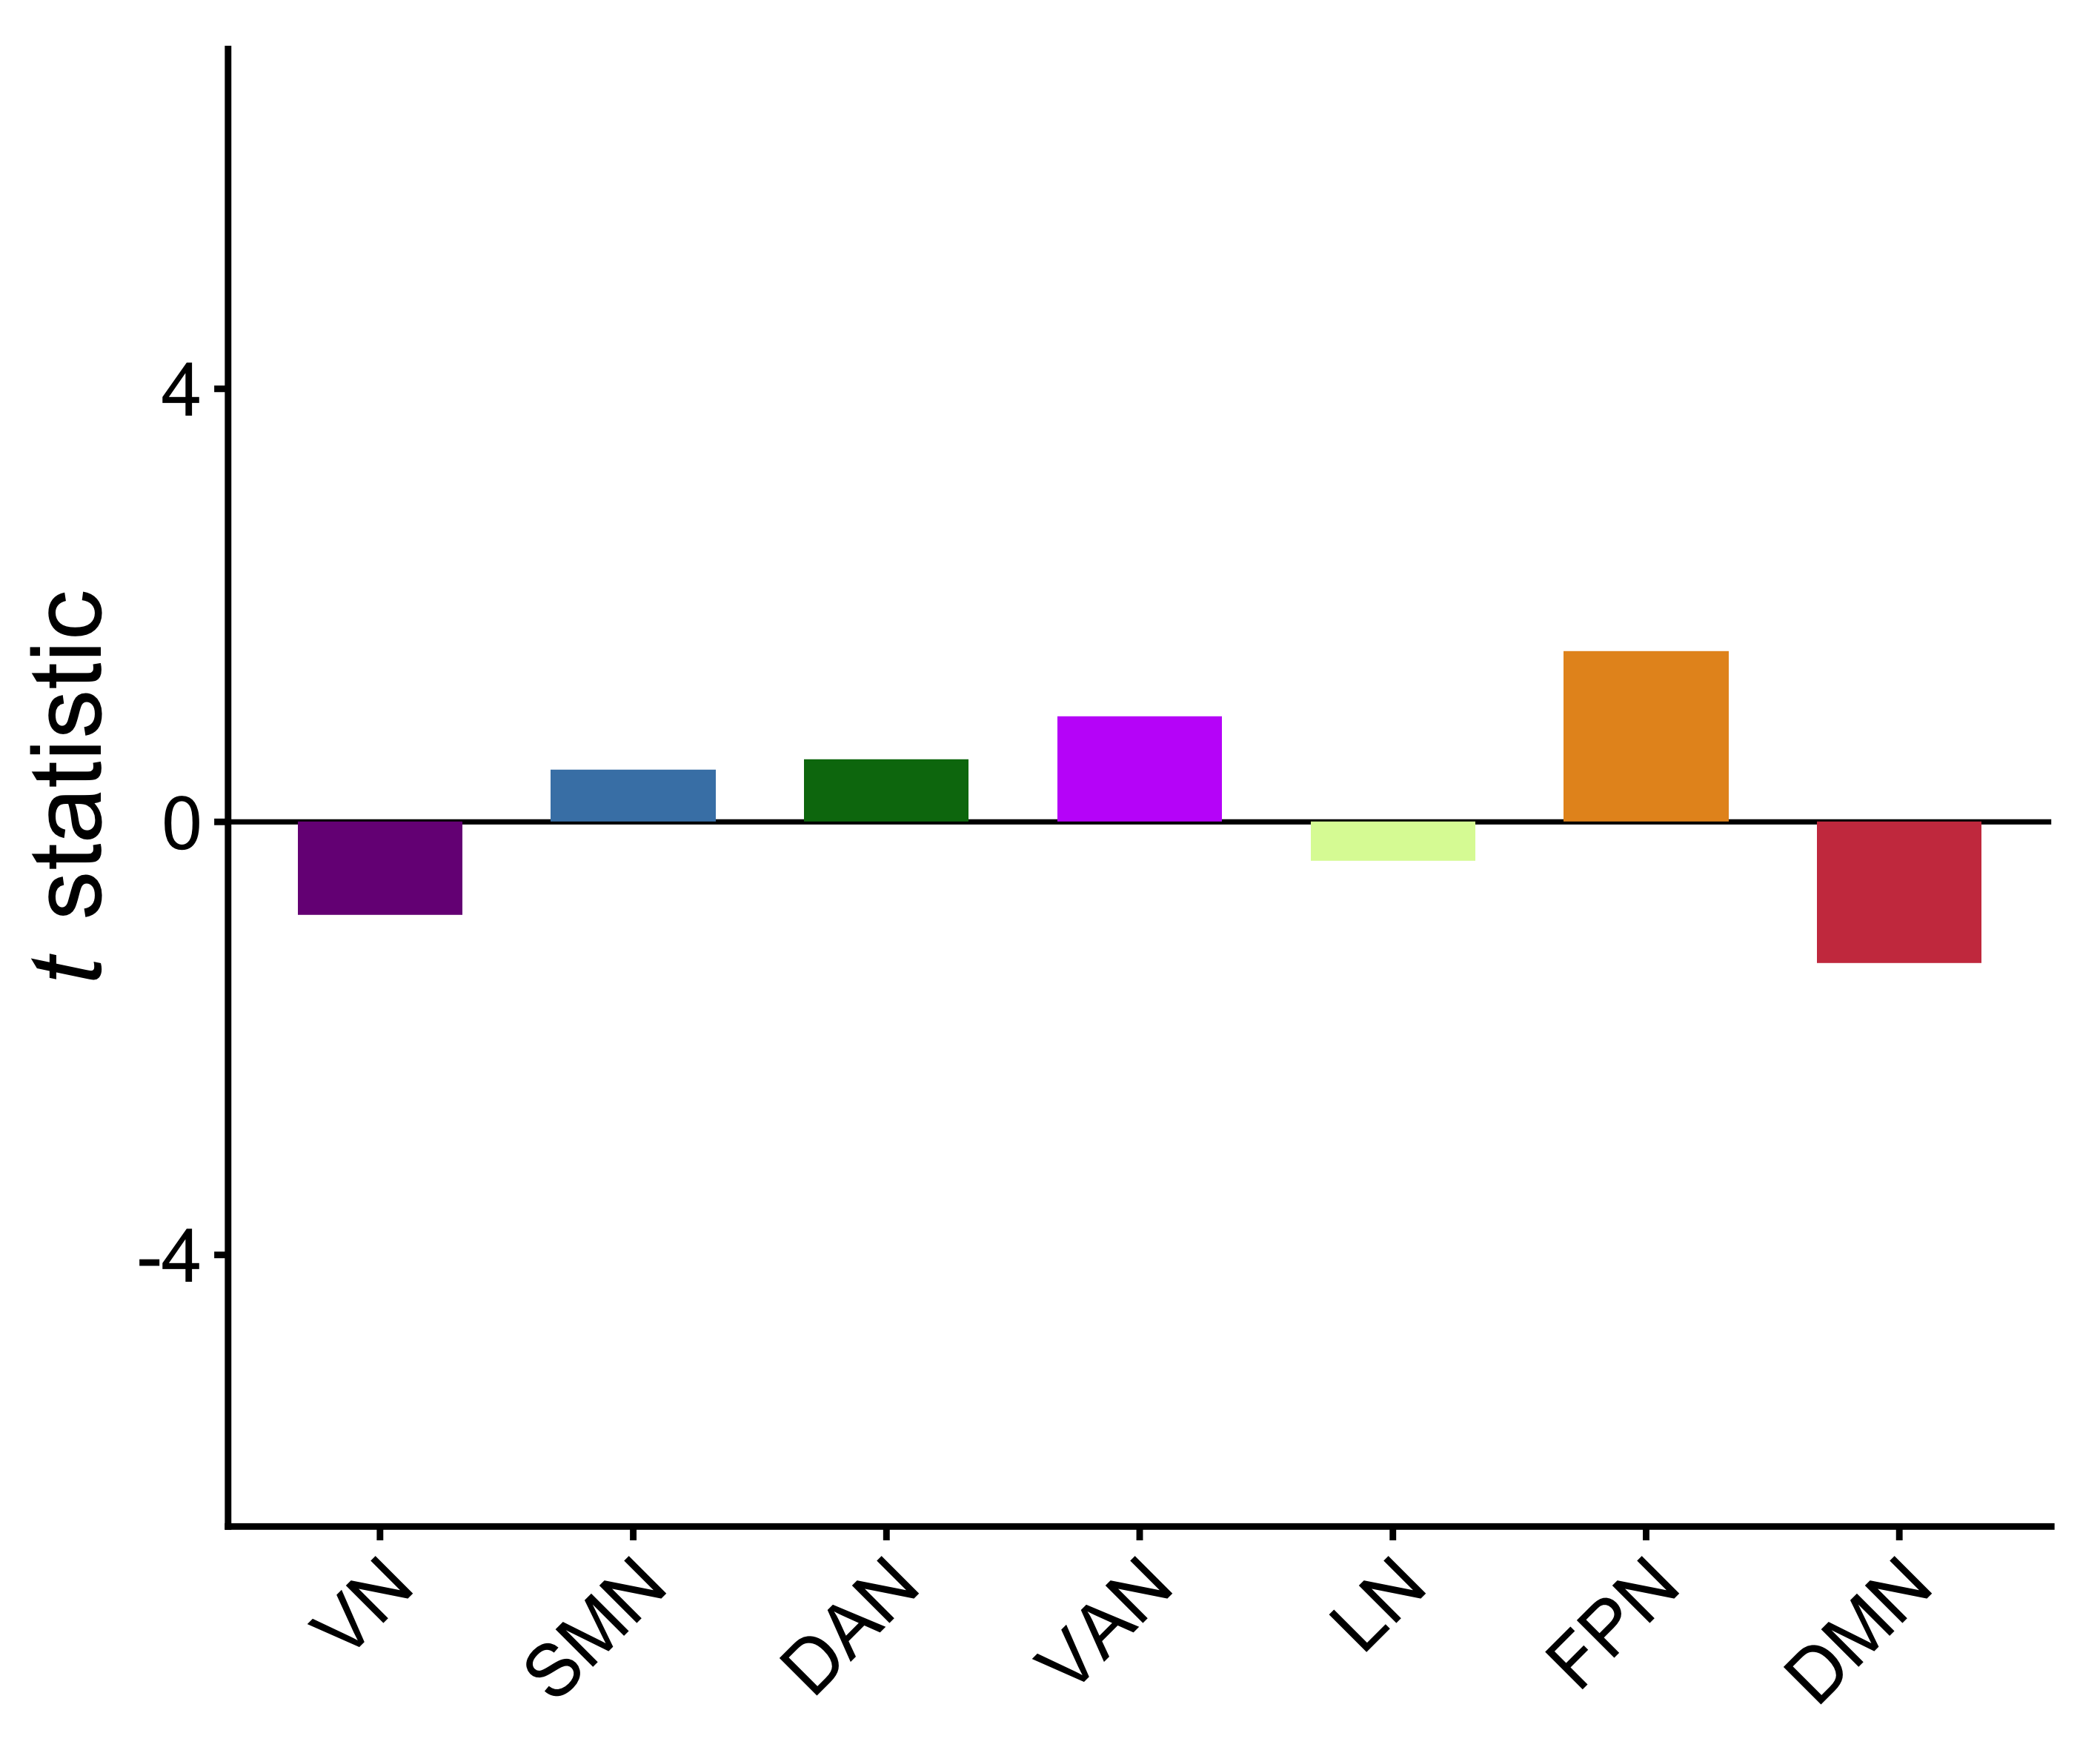

Beijing_IPCAS_positive_gt3p29_cluster1_n69_mask.func_FunSurfWglobalCF_network_tstat_bar.png


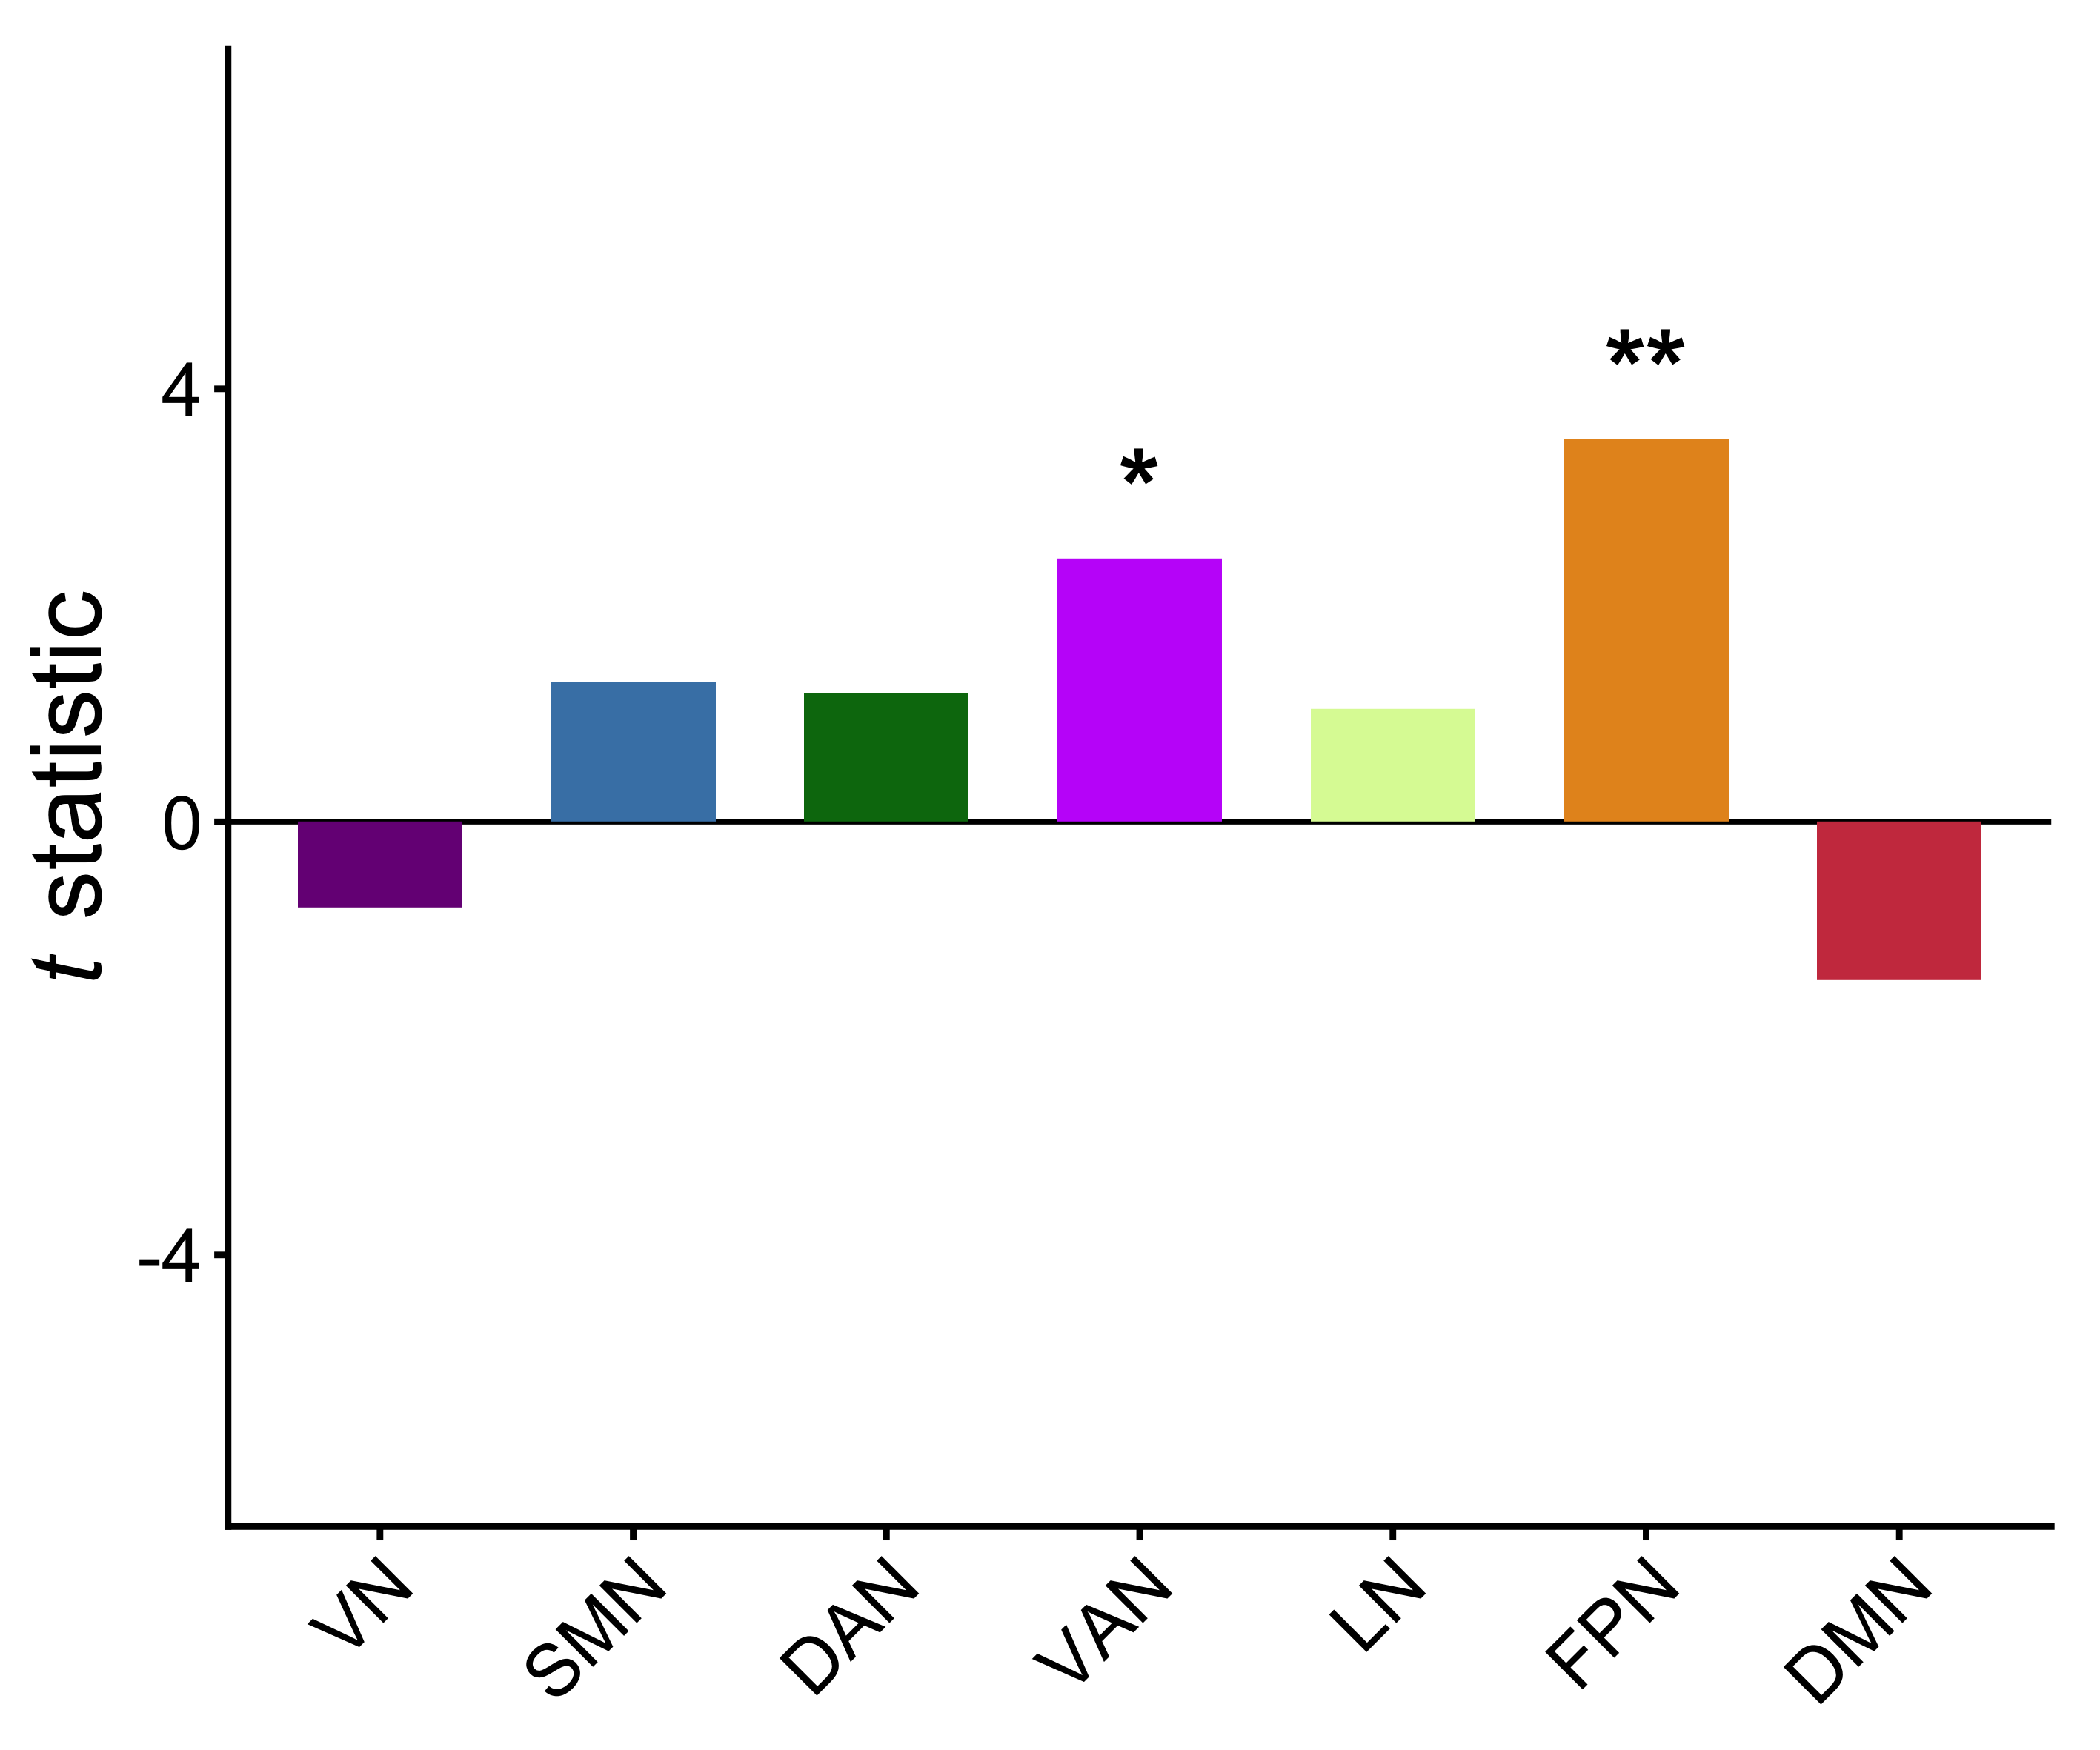

Beijing_IPCAS_positive_gt3p29_cluster2_n50_mask.func_FunSurfWCF_network_tstat_bar.png


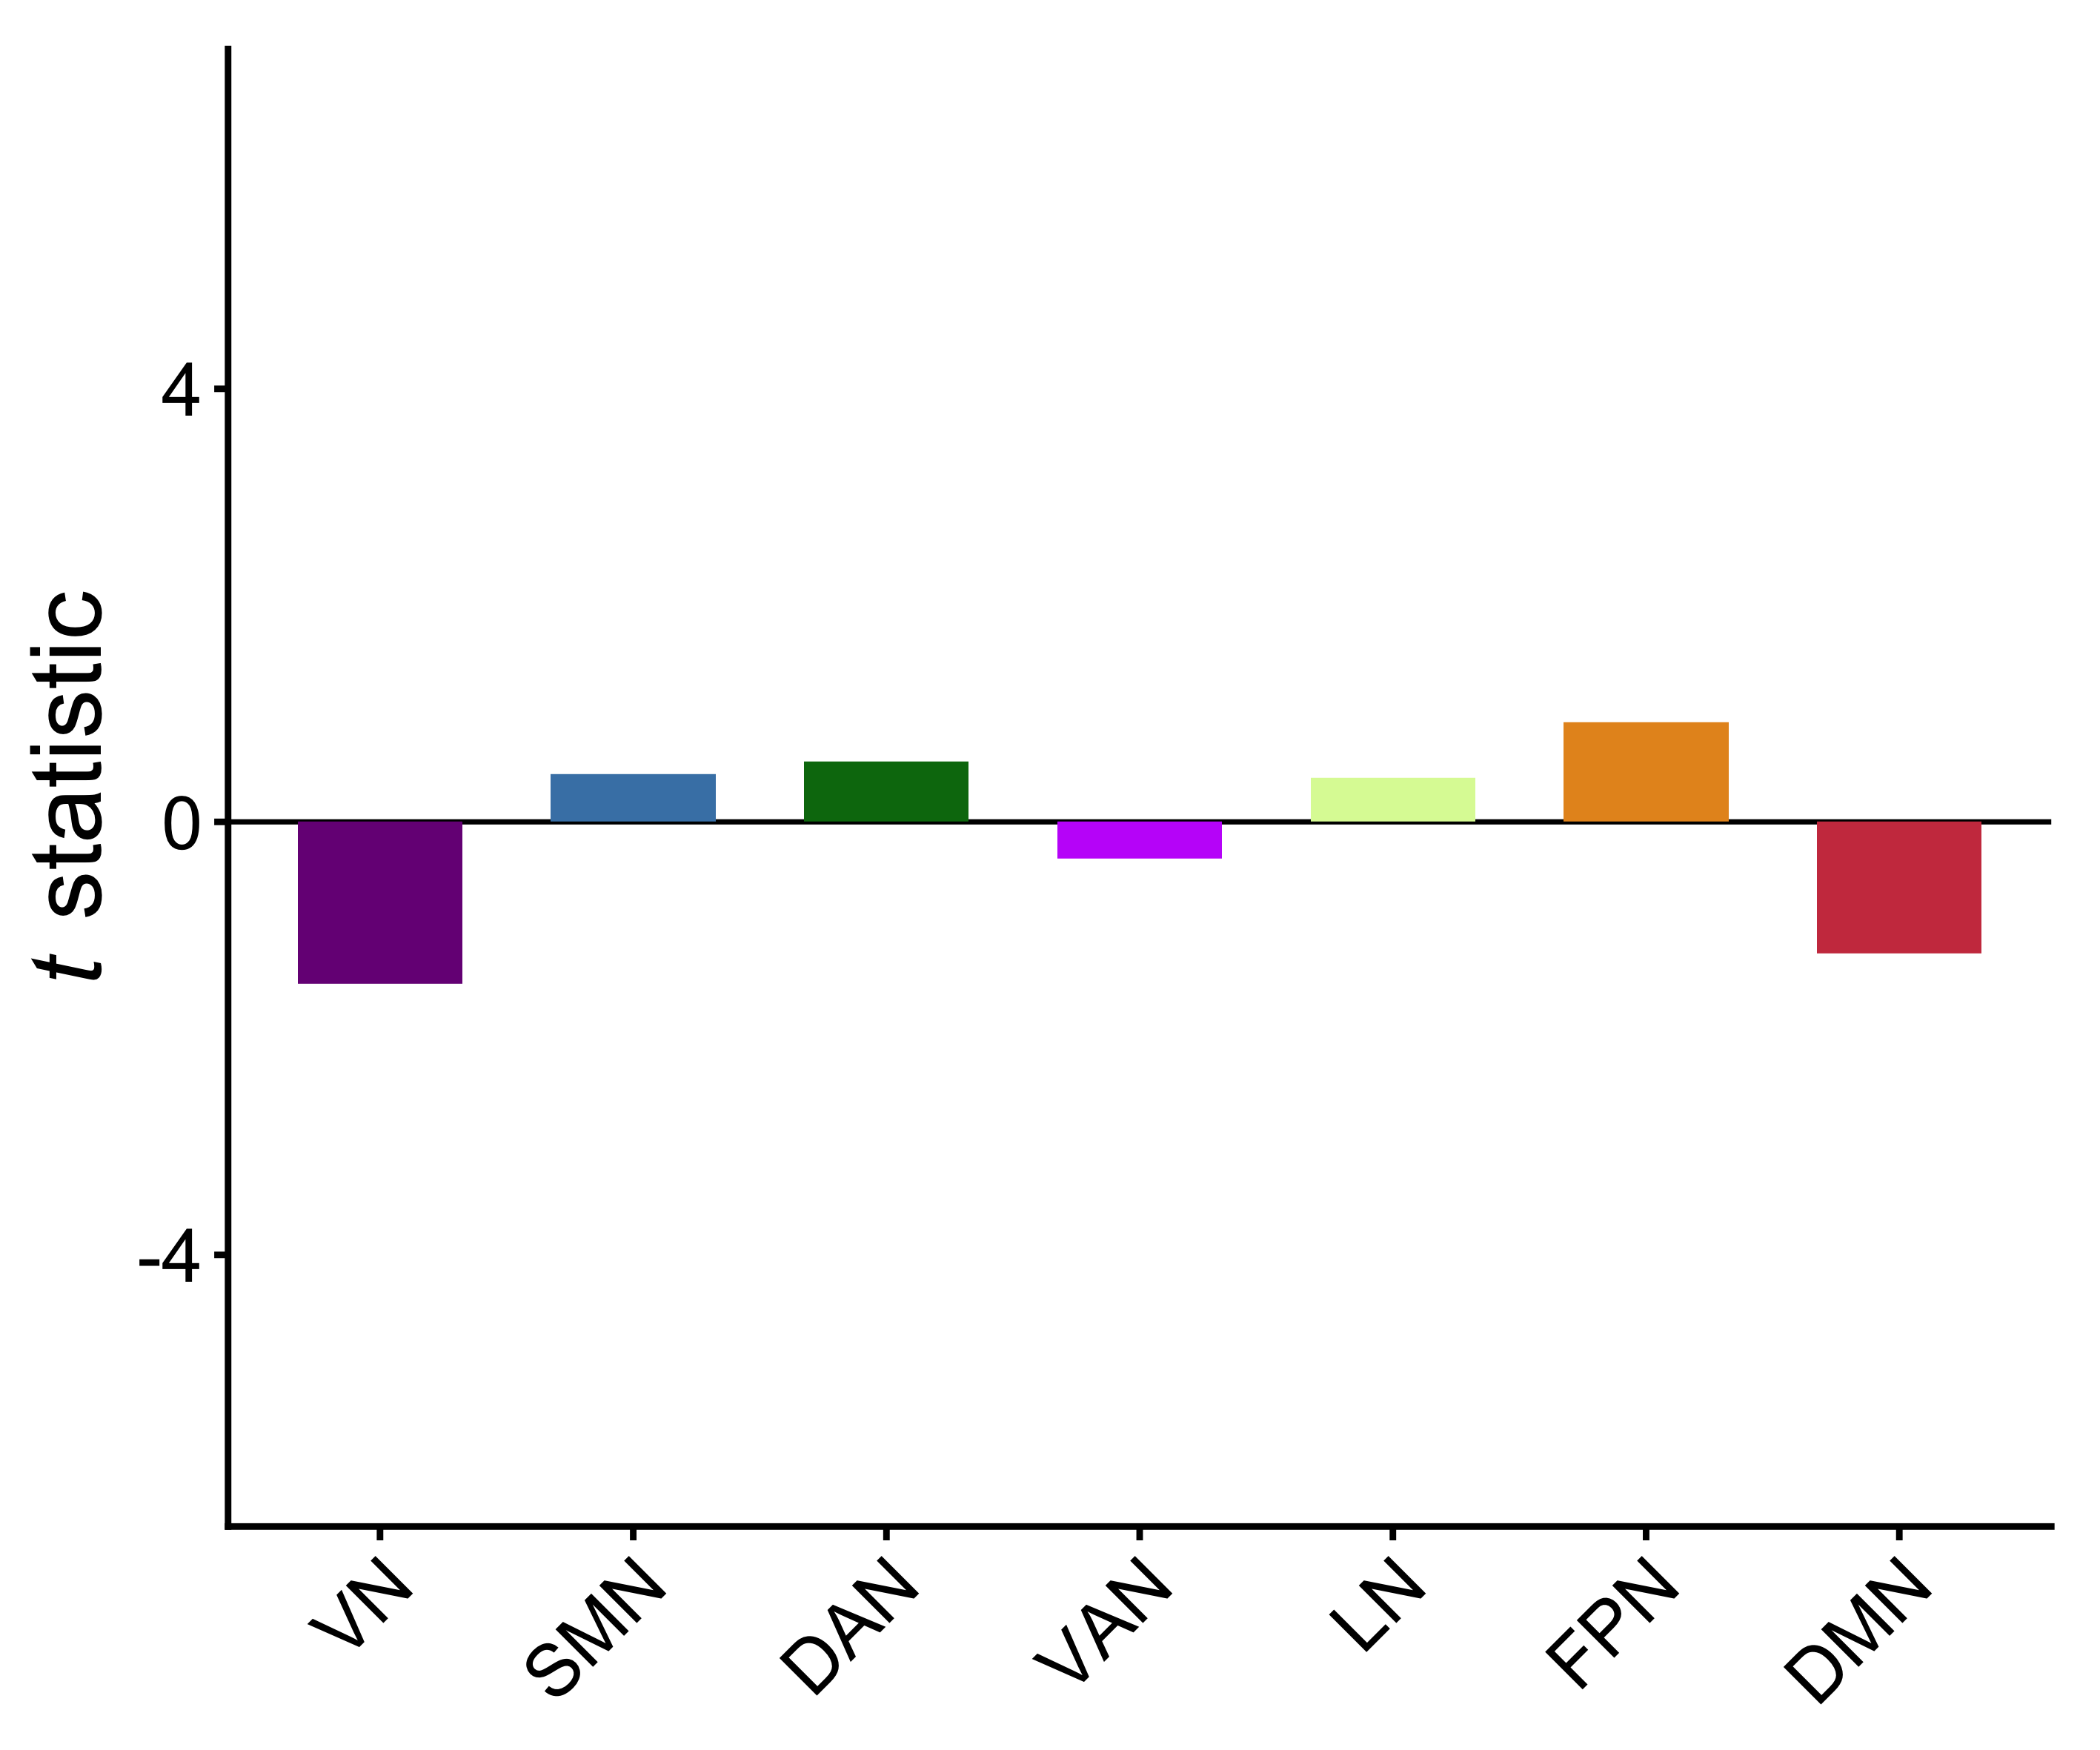

Beijing_IPCAS_positive_gt3p29_cluster2_n50_mask.func_FunSurfWglobalCF_network_tstat_bar.png


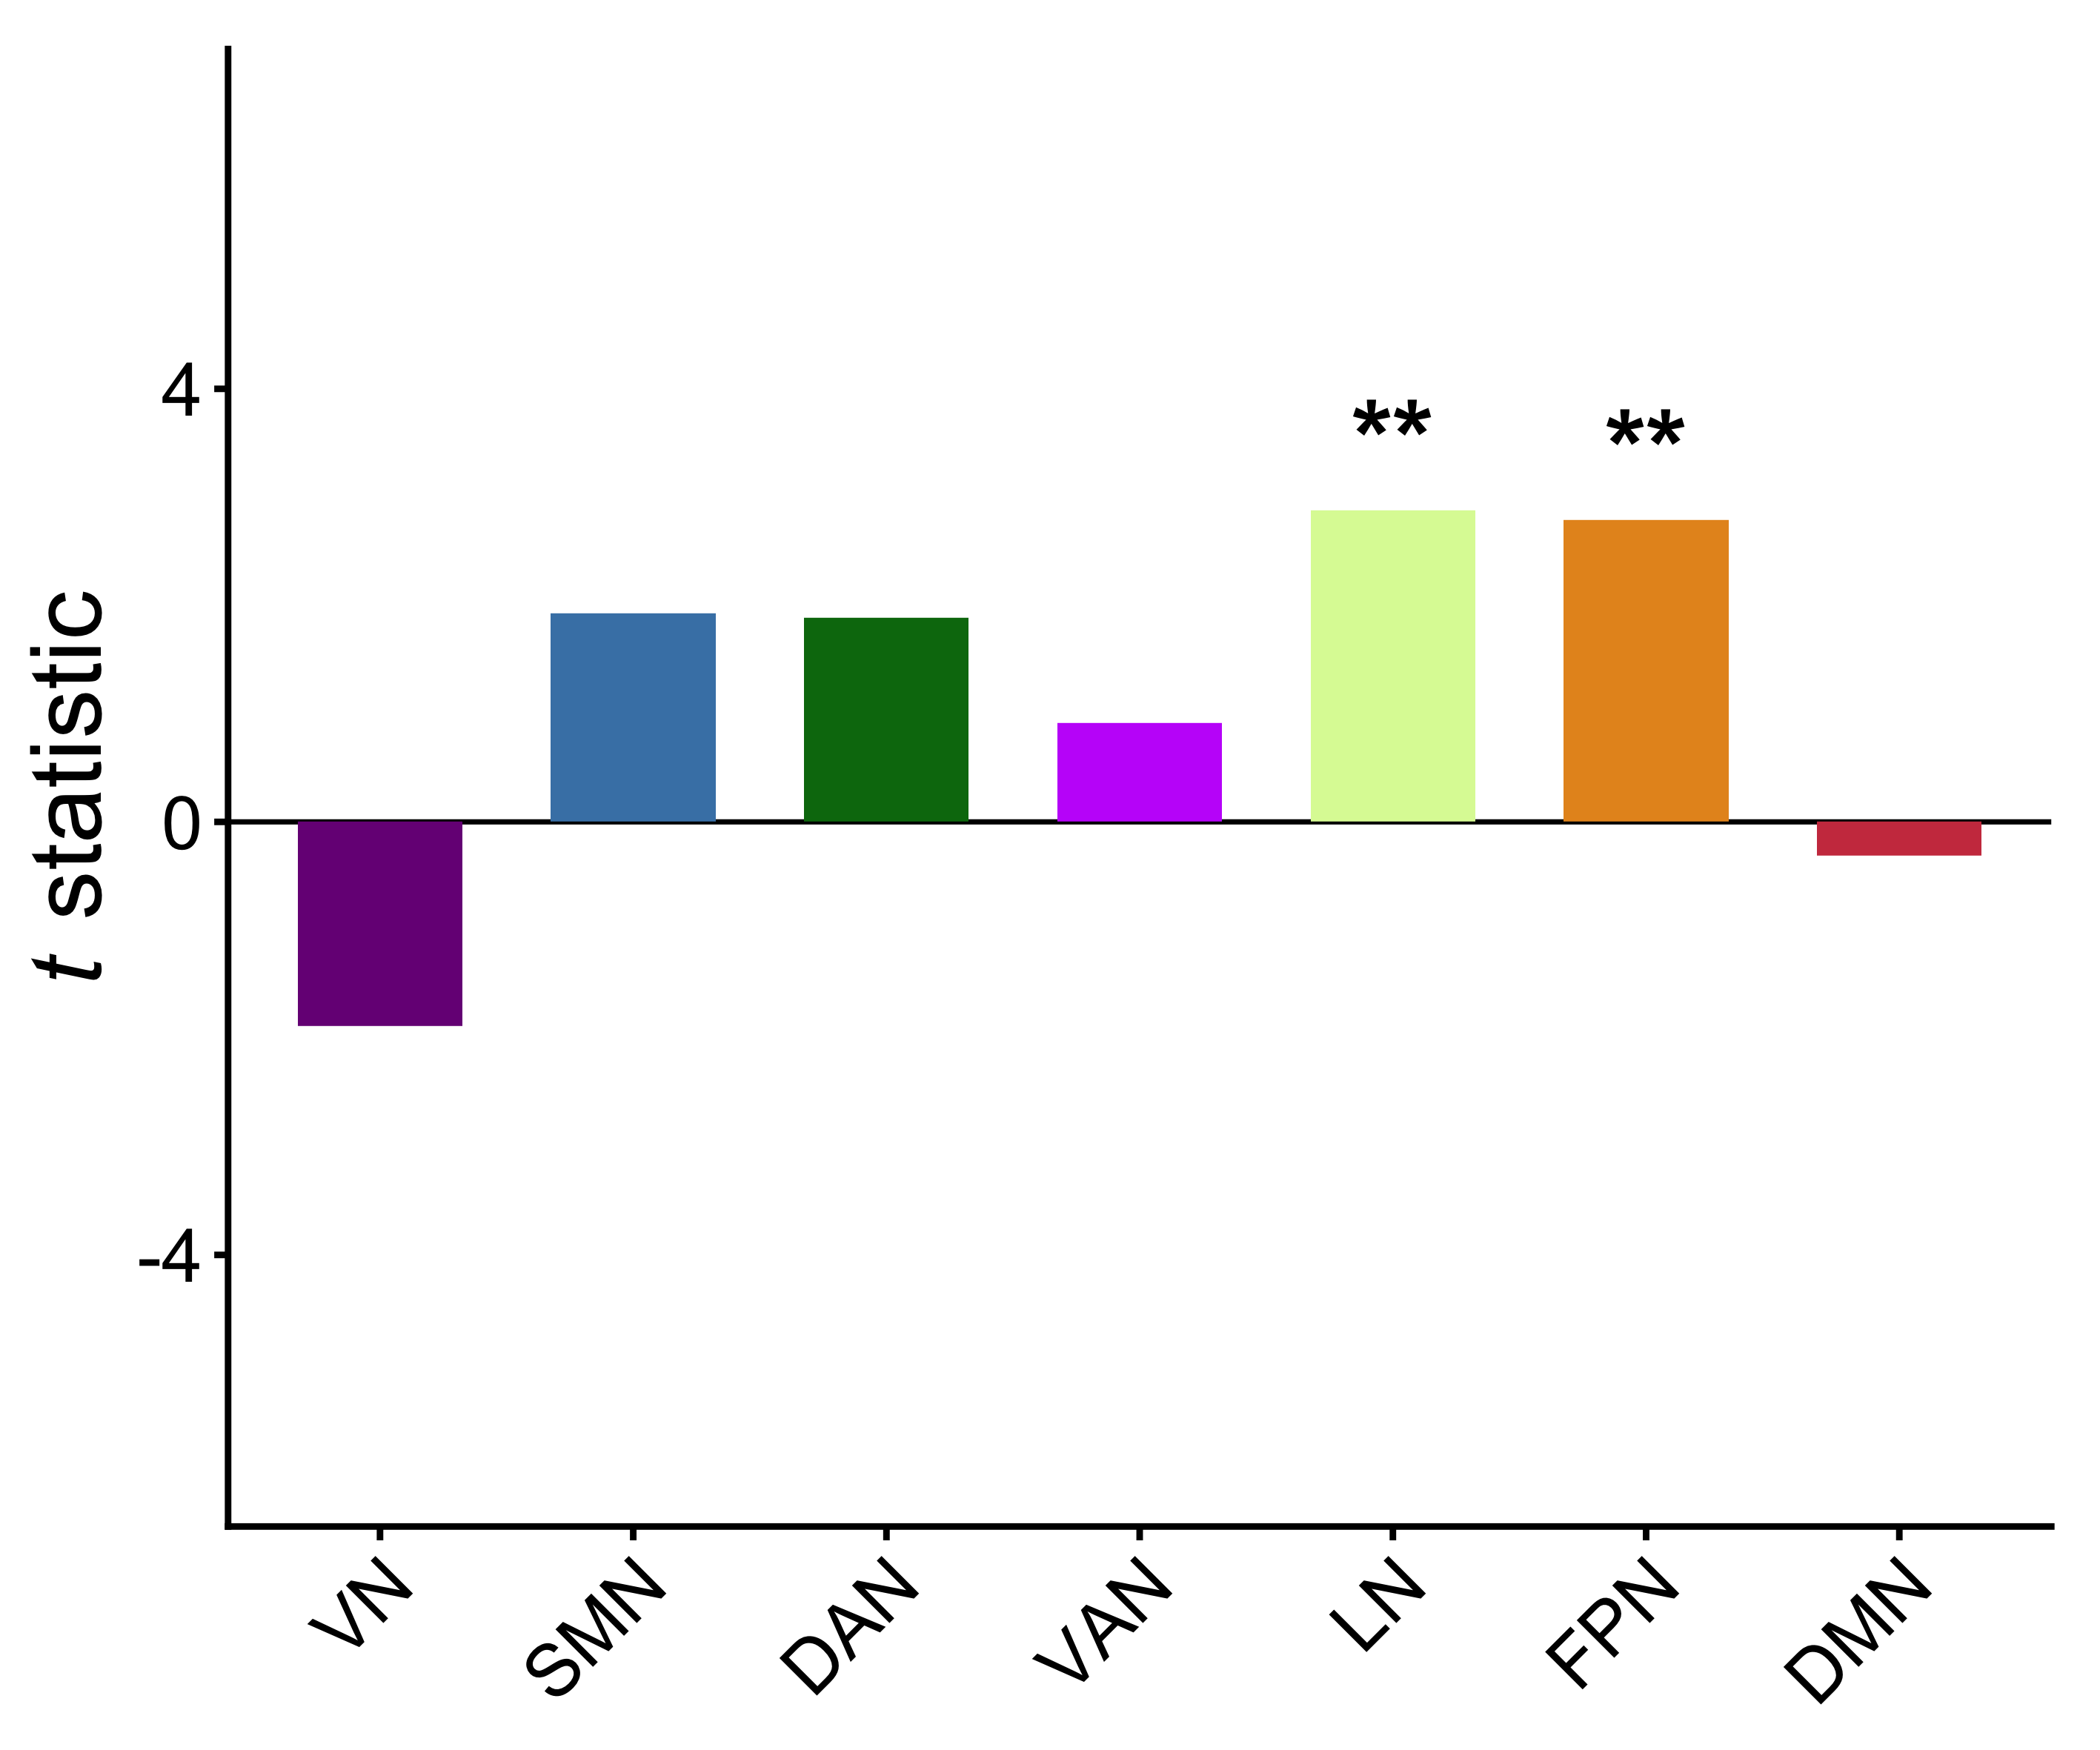

Beijing_IPCAS_positive_gt3p29_cluster3_n33_mask.func_FunSurfWCF_network_tstat_bar.png


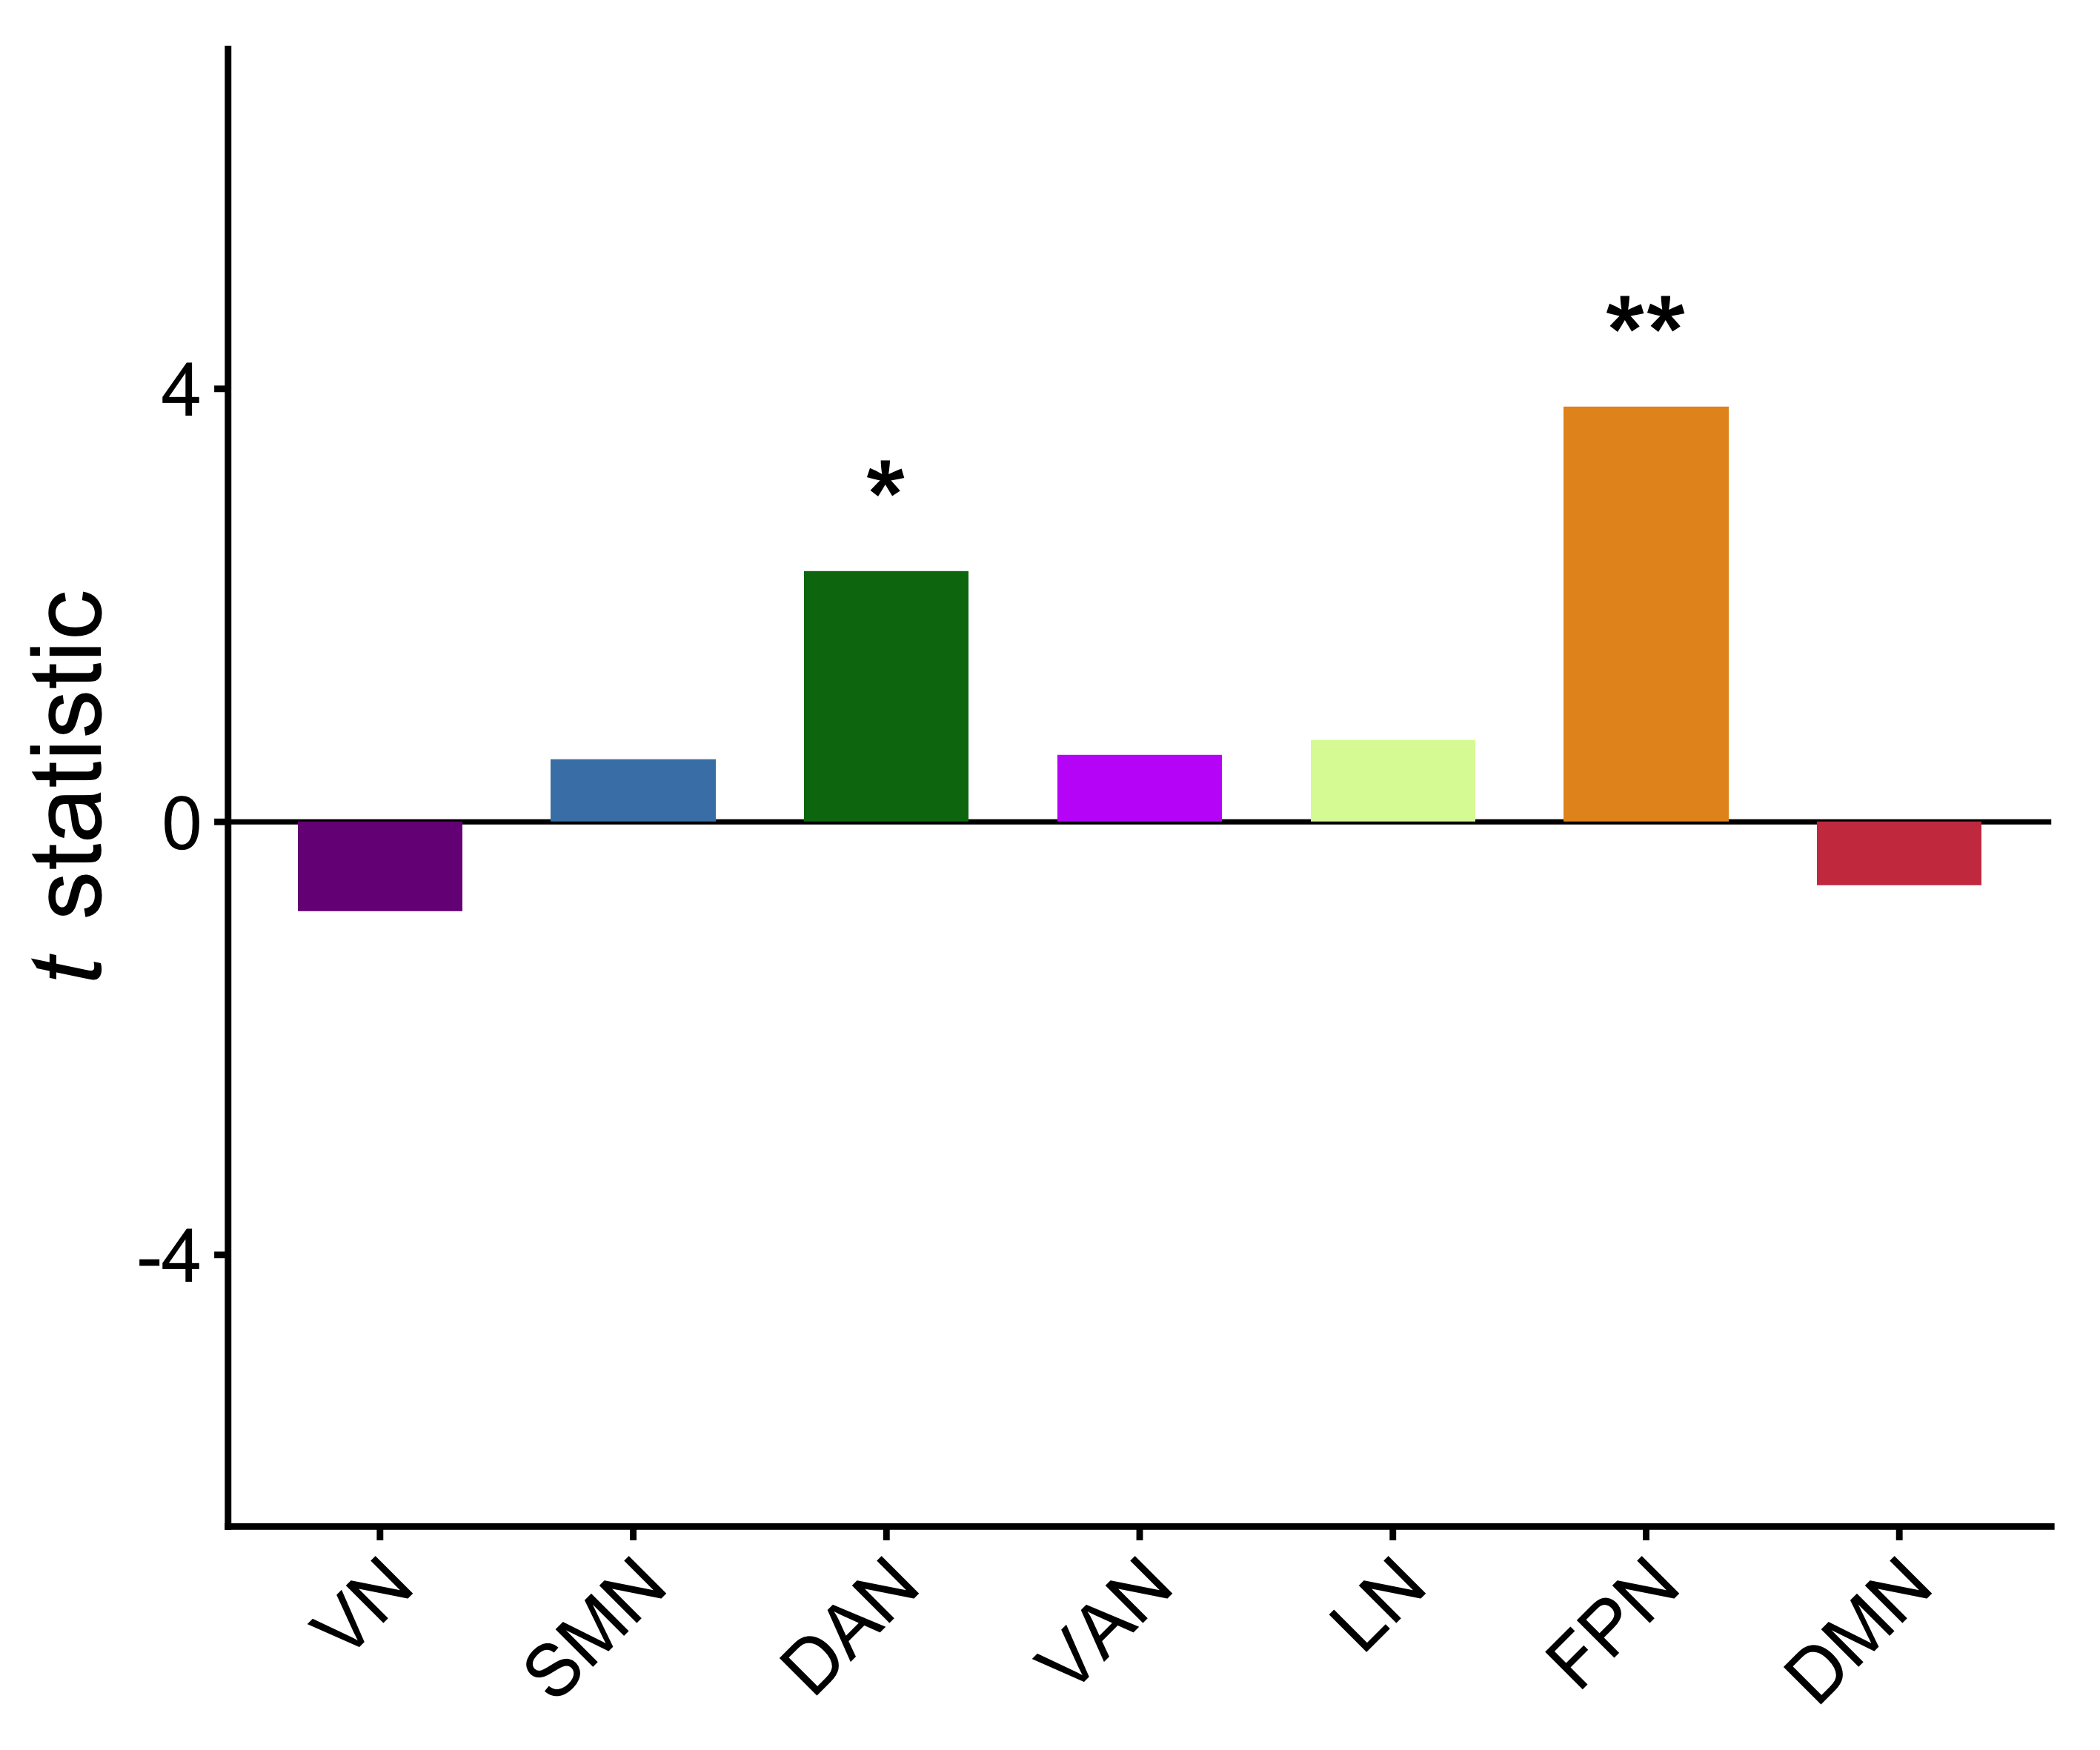

Beijing_IPCAS_positive_gt3p29_cluster3_n33_mask.func_FunSurfWglobalCF_network_tstat_bar.png


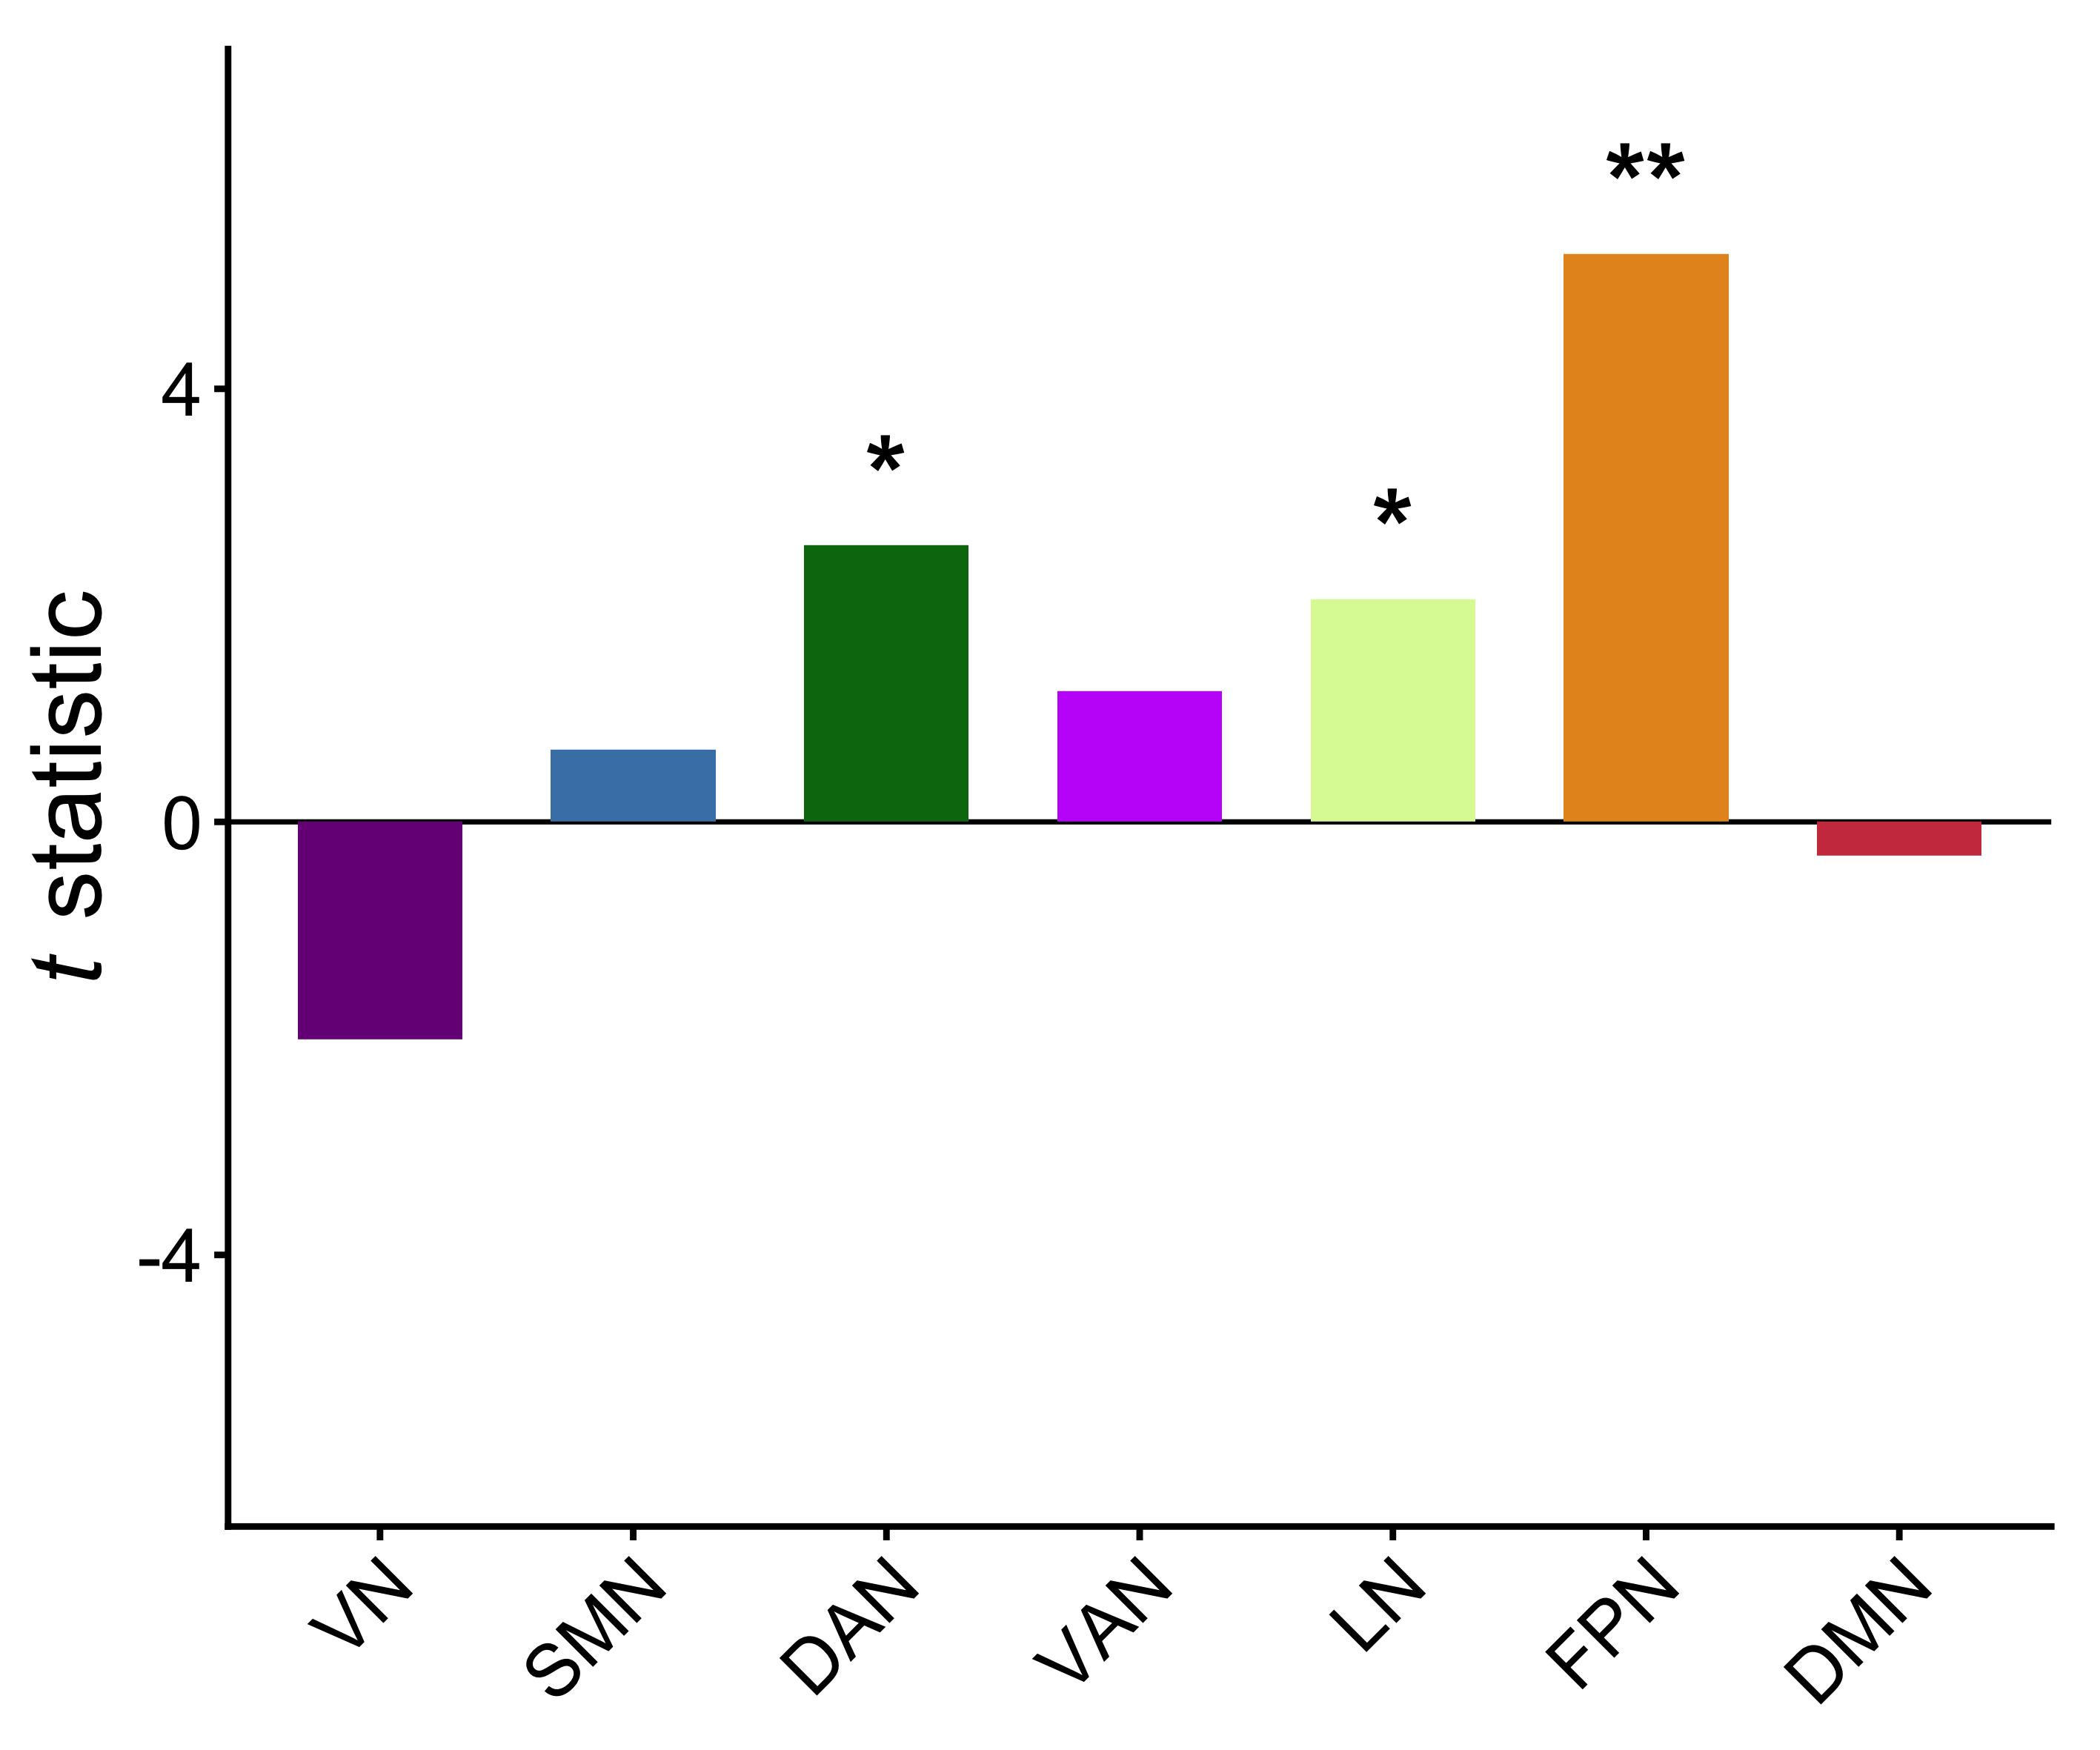

Beijing_PKUGE_positive_gt3p29_cluster1_n69_mask.func_FunSurfWCF_network_tstat_bar.png


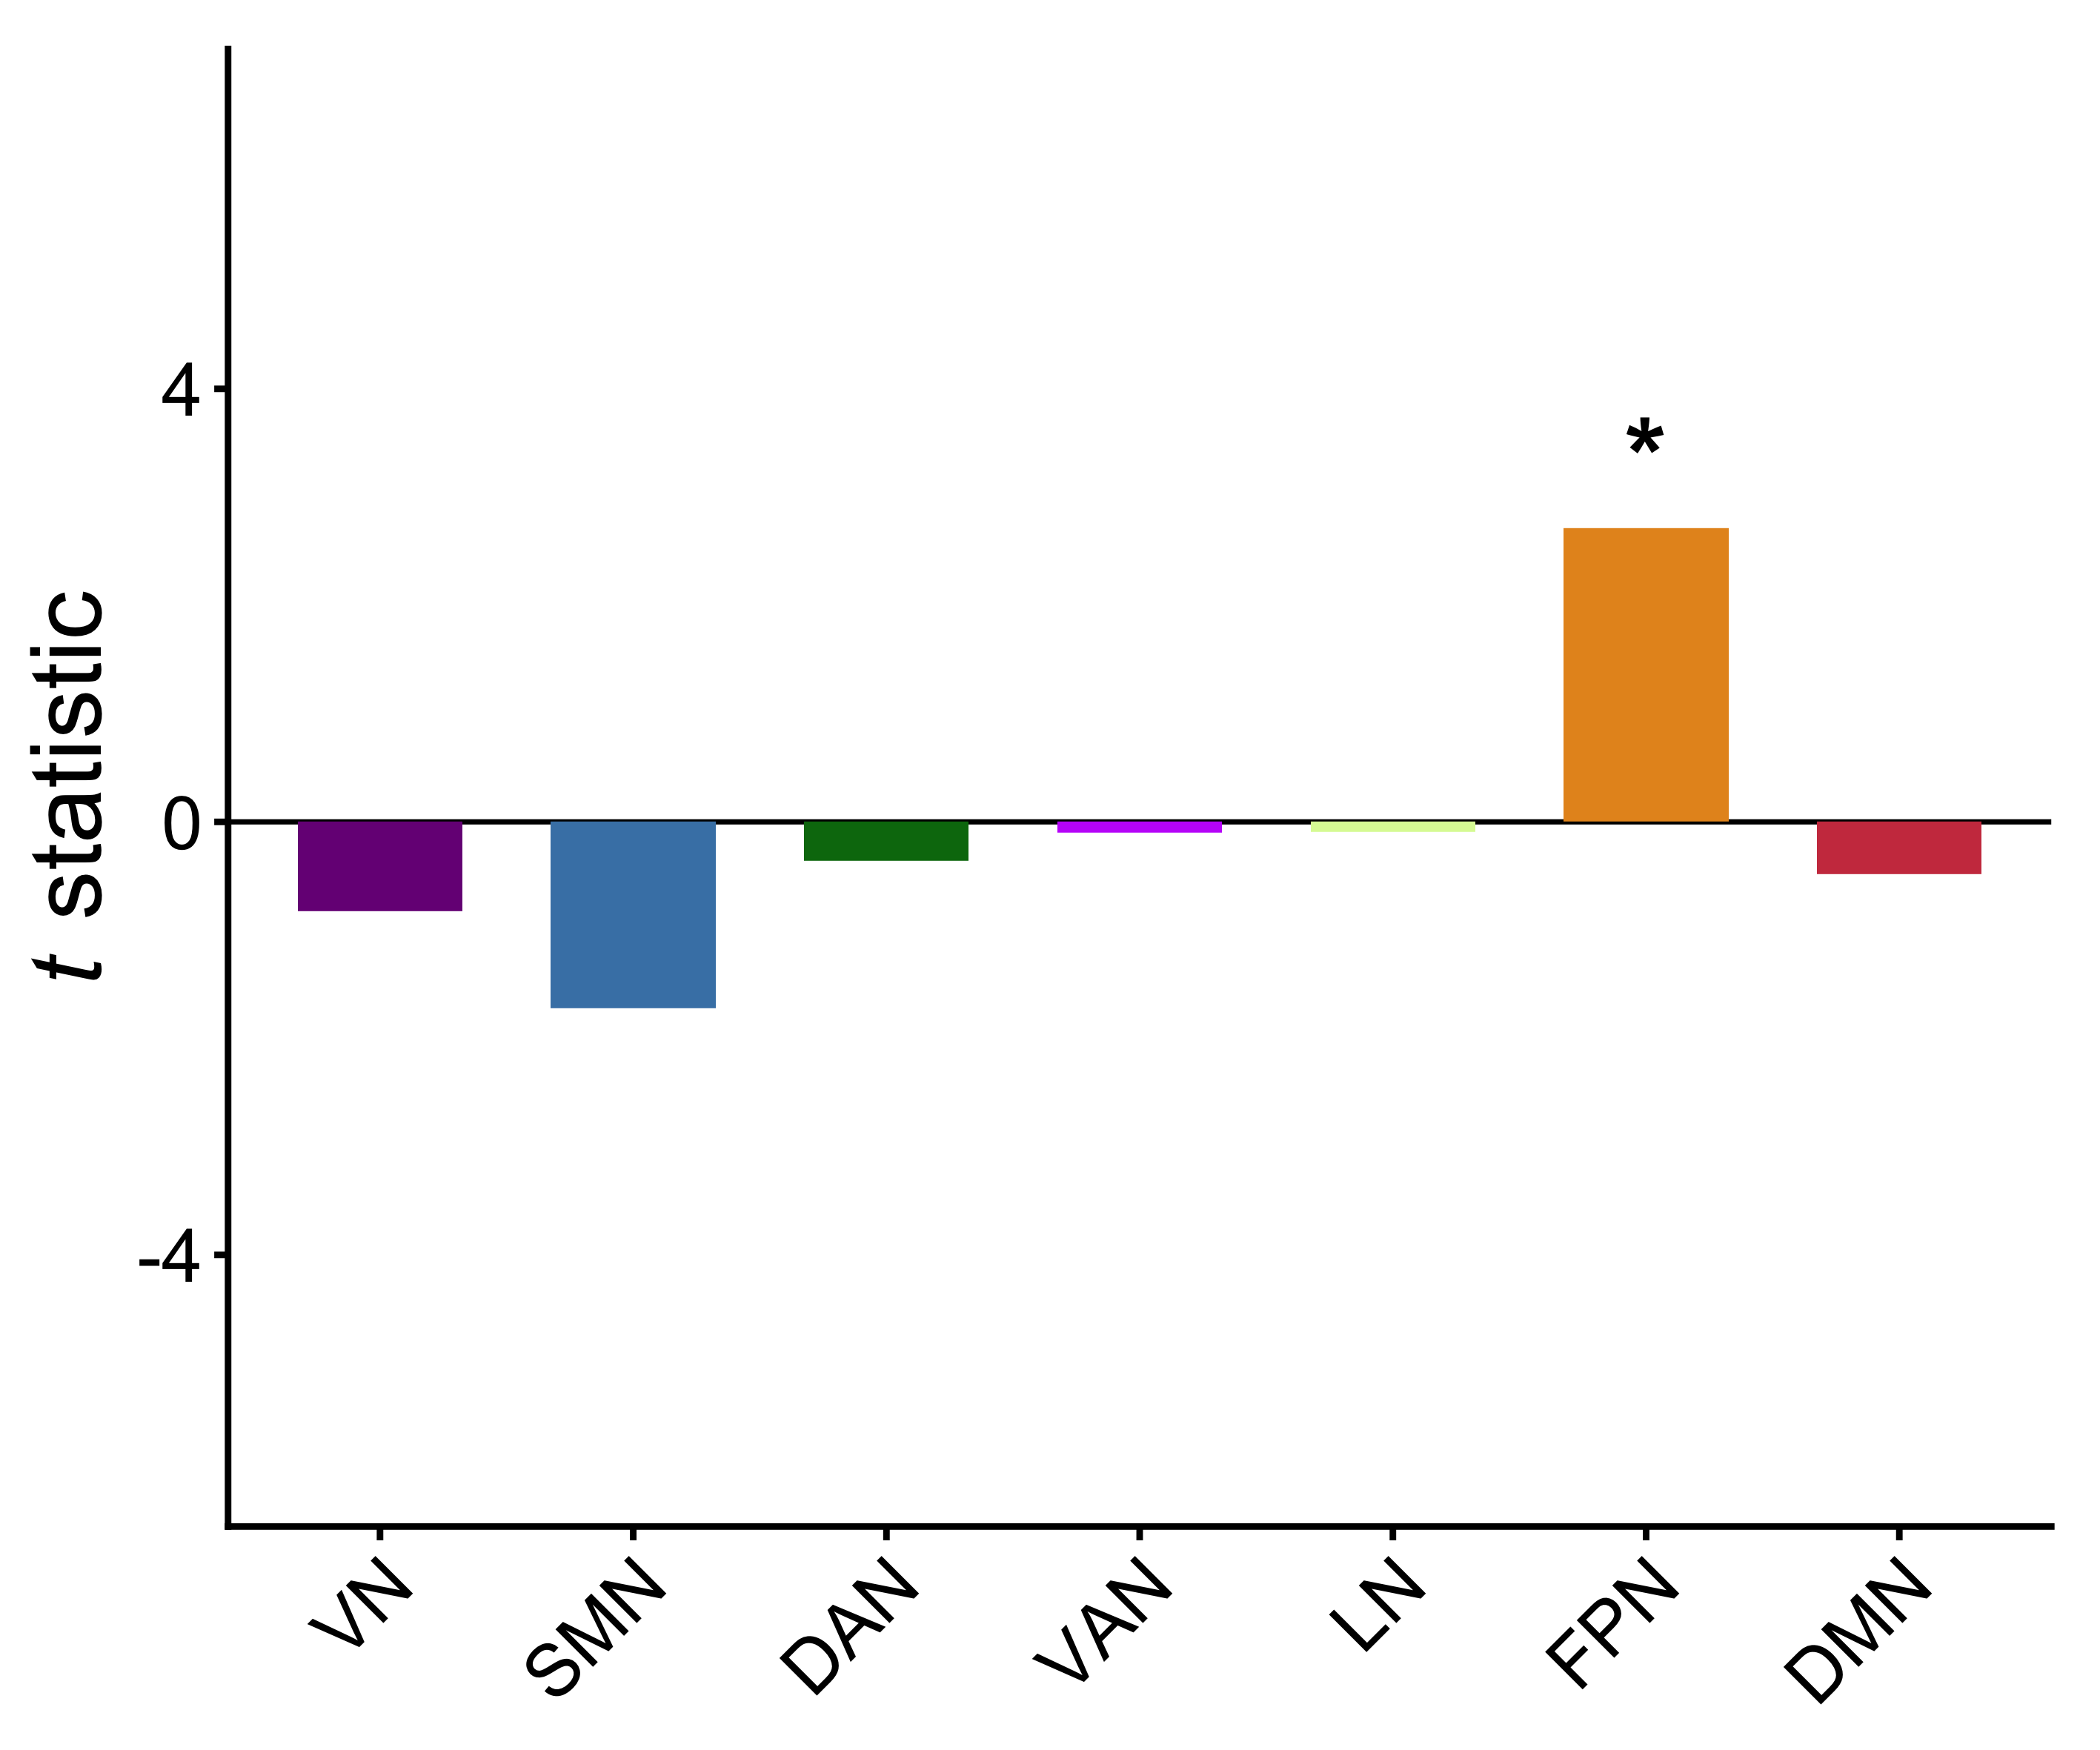

Beijing_PKUGE_positive_gt3p29_cluster1_n69_mask.func_FunSurfWglobalCF_network_tstat_bar.png


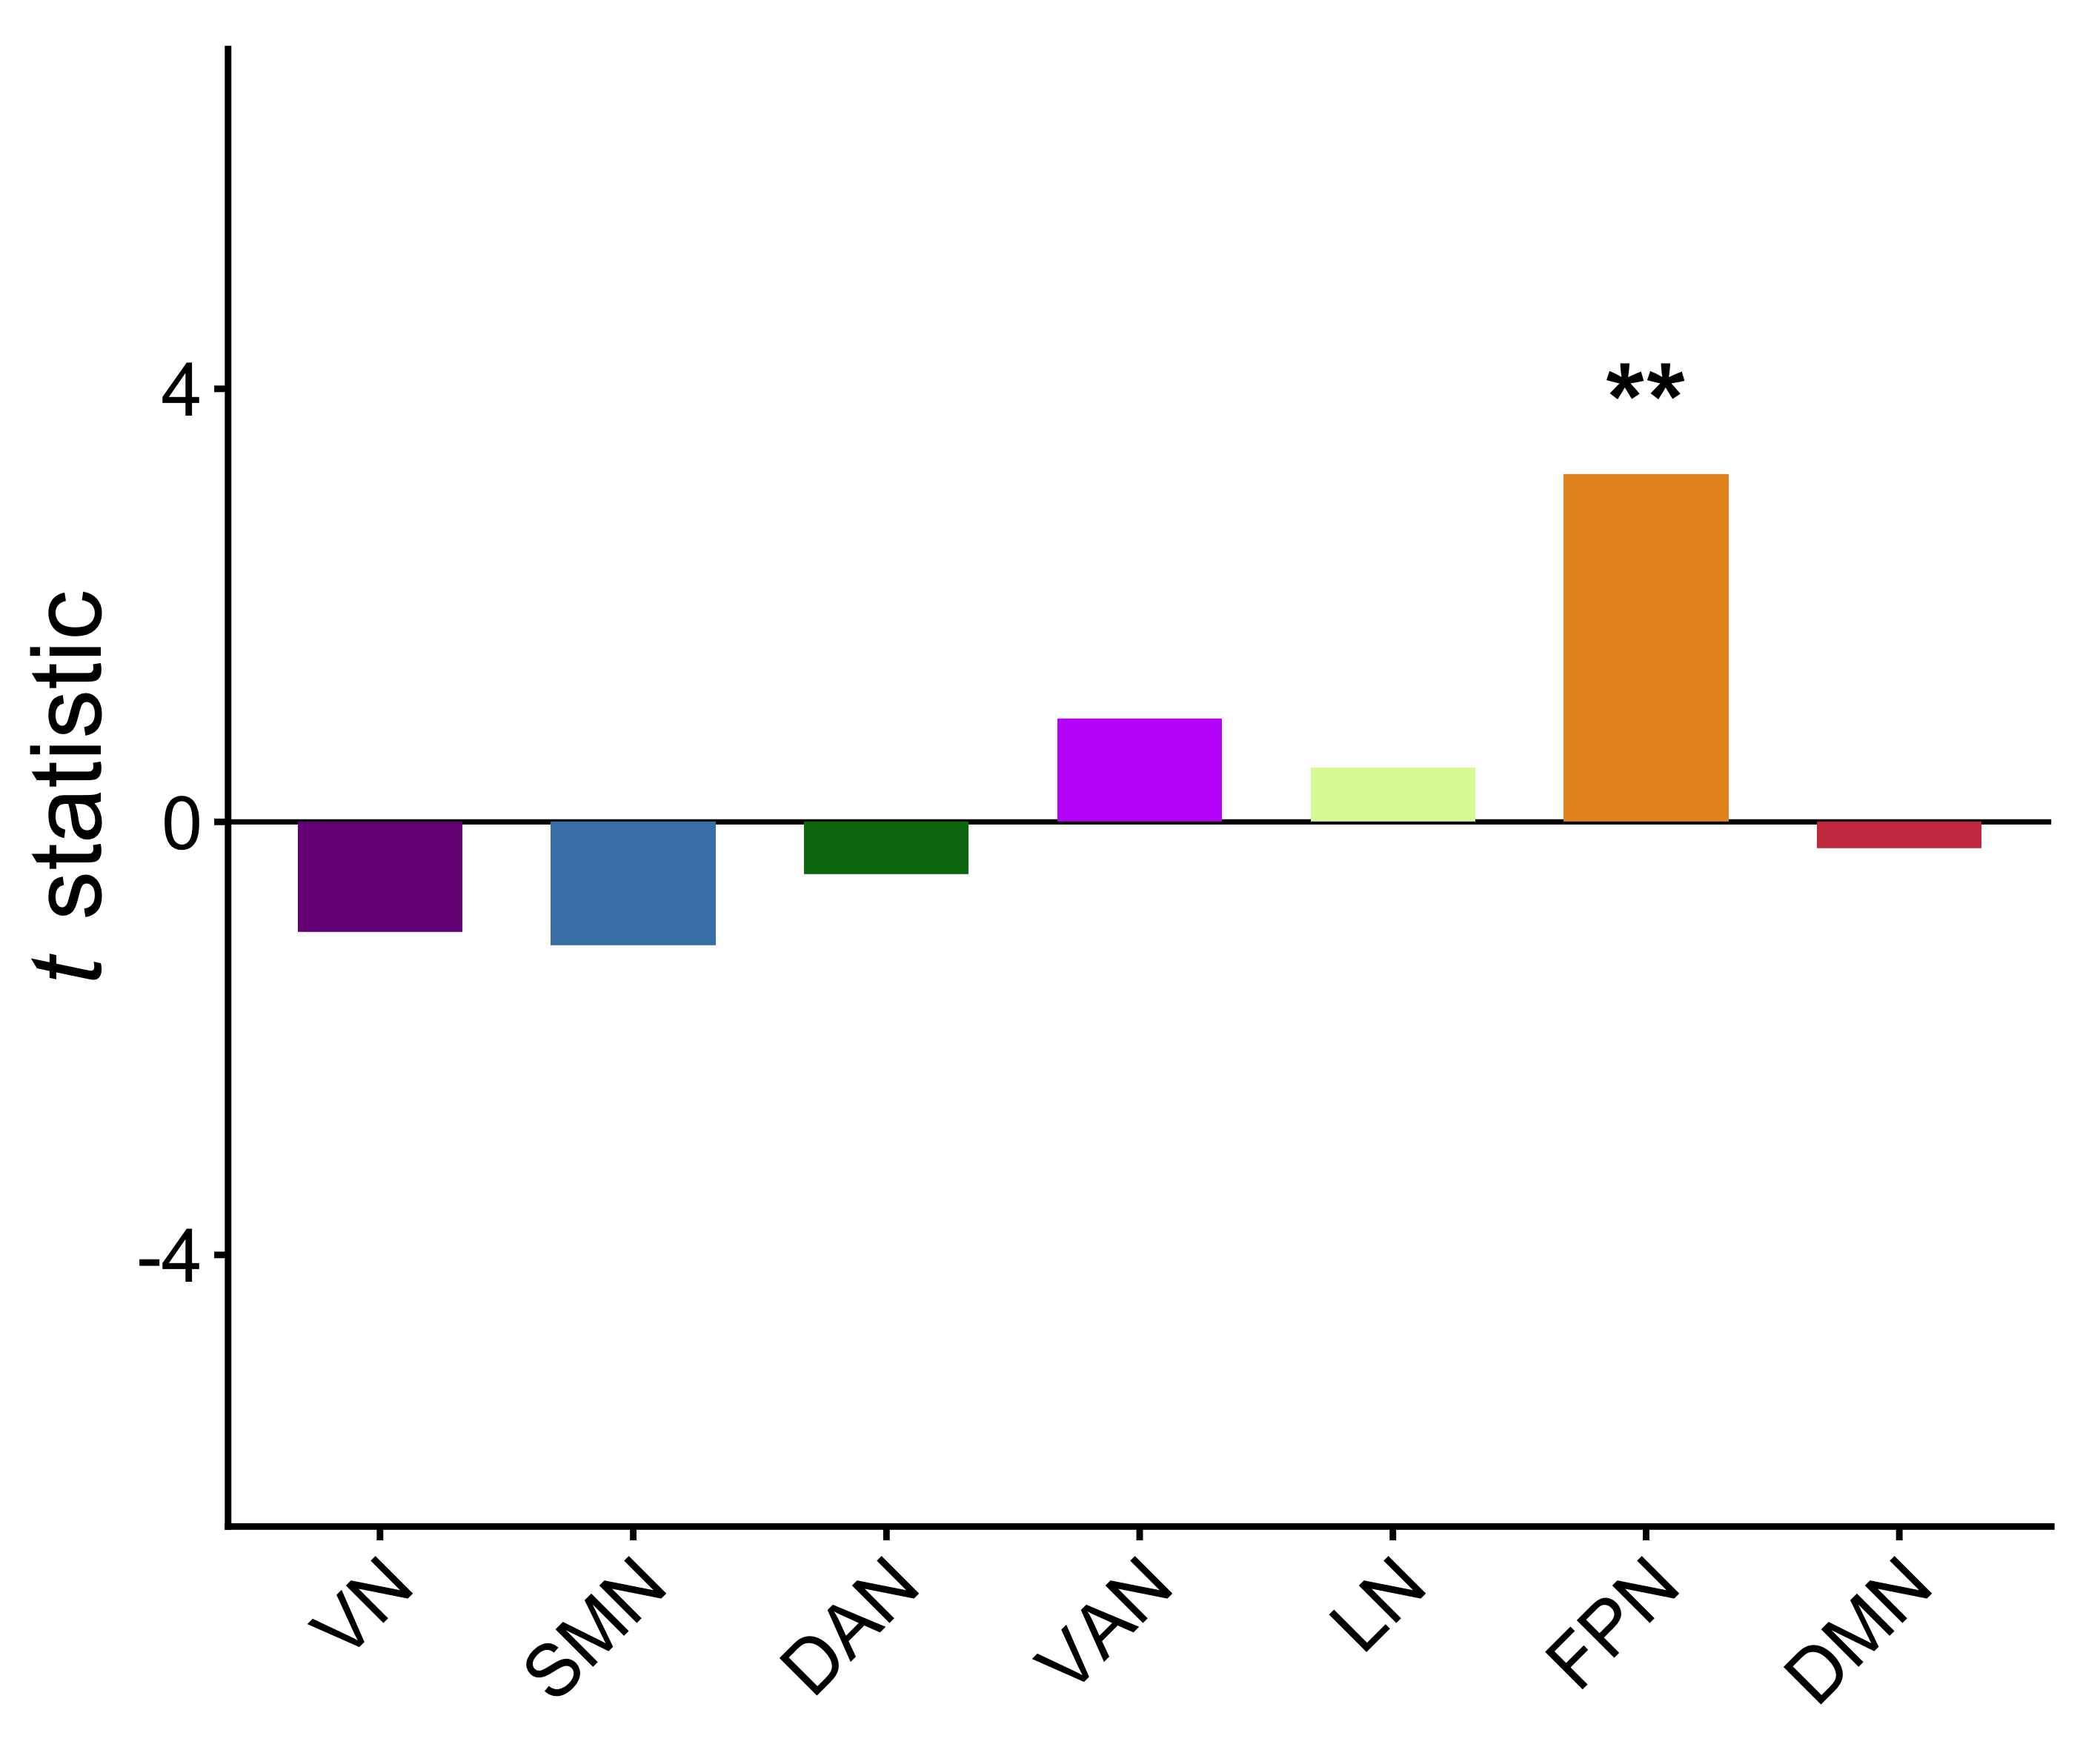

Beijing_PKUGE_positive_gt3p29_cluster2_n50_mask.func_FunSurfWCF_network_tstat_bar.png


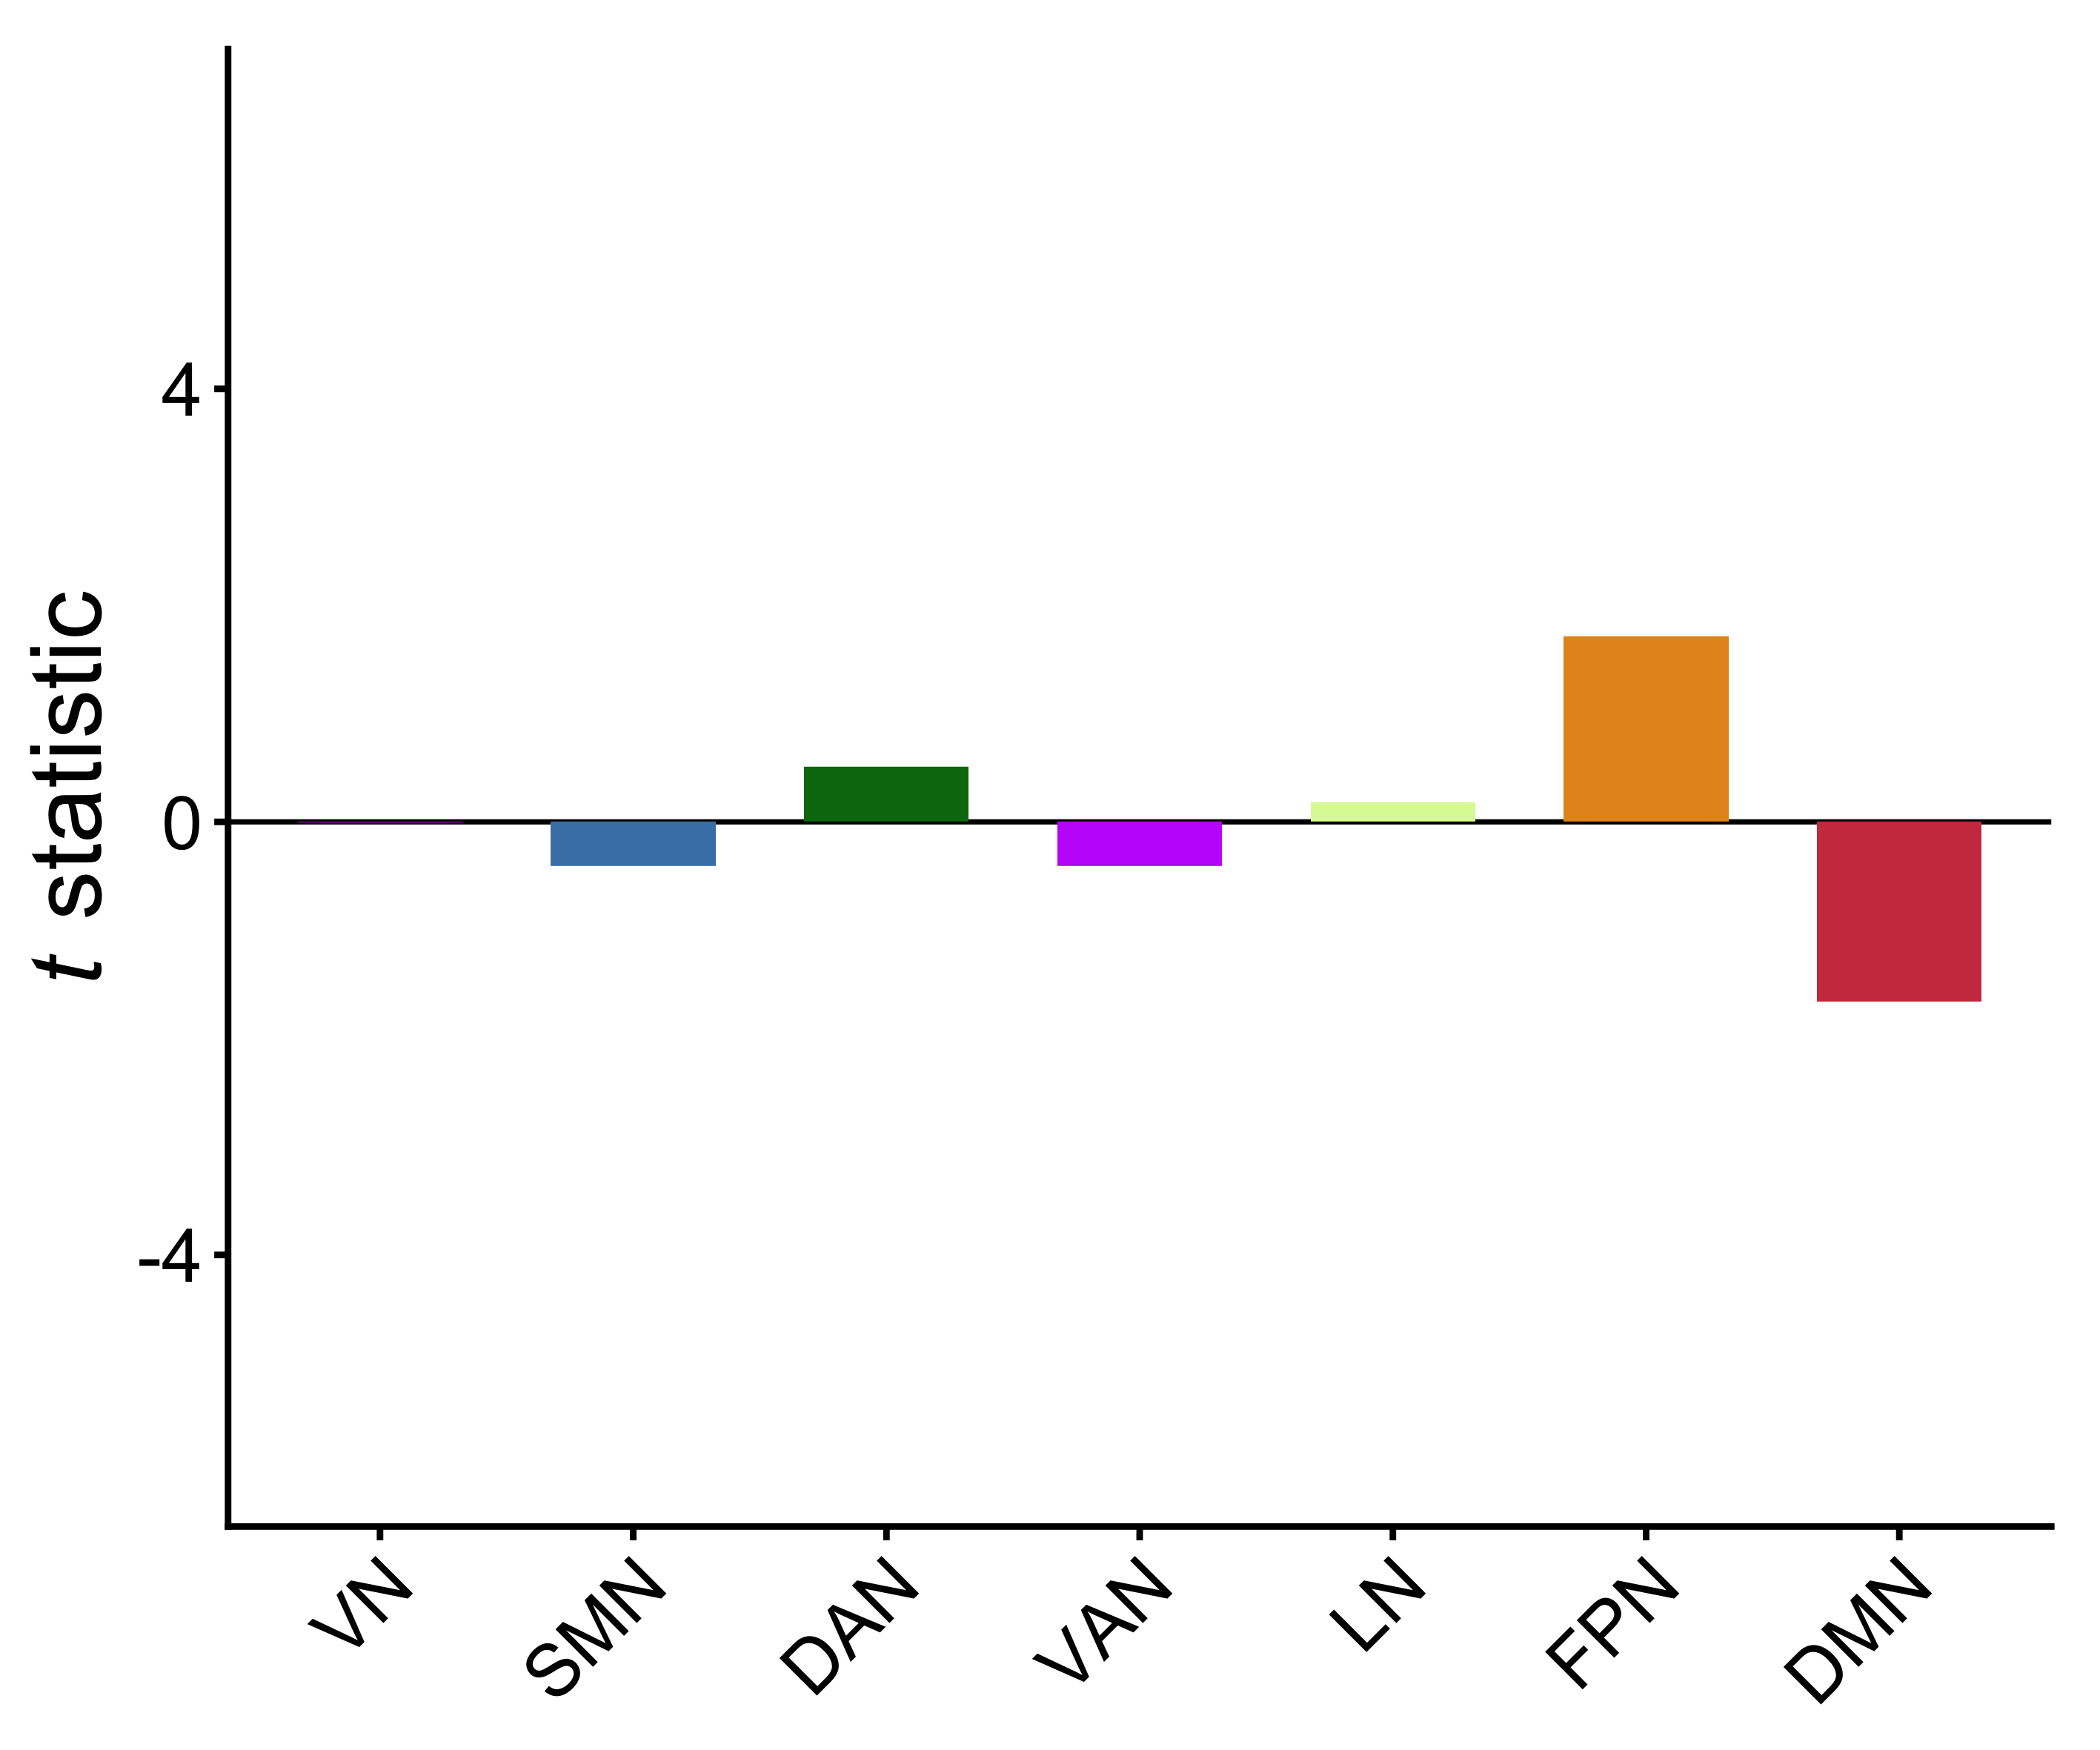

Beijing_PKUGE_positive_gt3p29_cluster2_n50_mask.func_FunSurfWglobalCF_network_tstat_bar.png


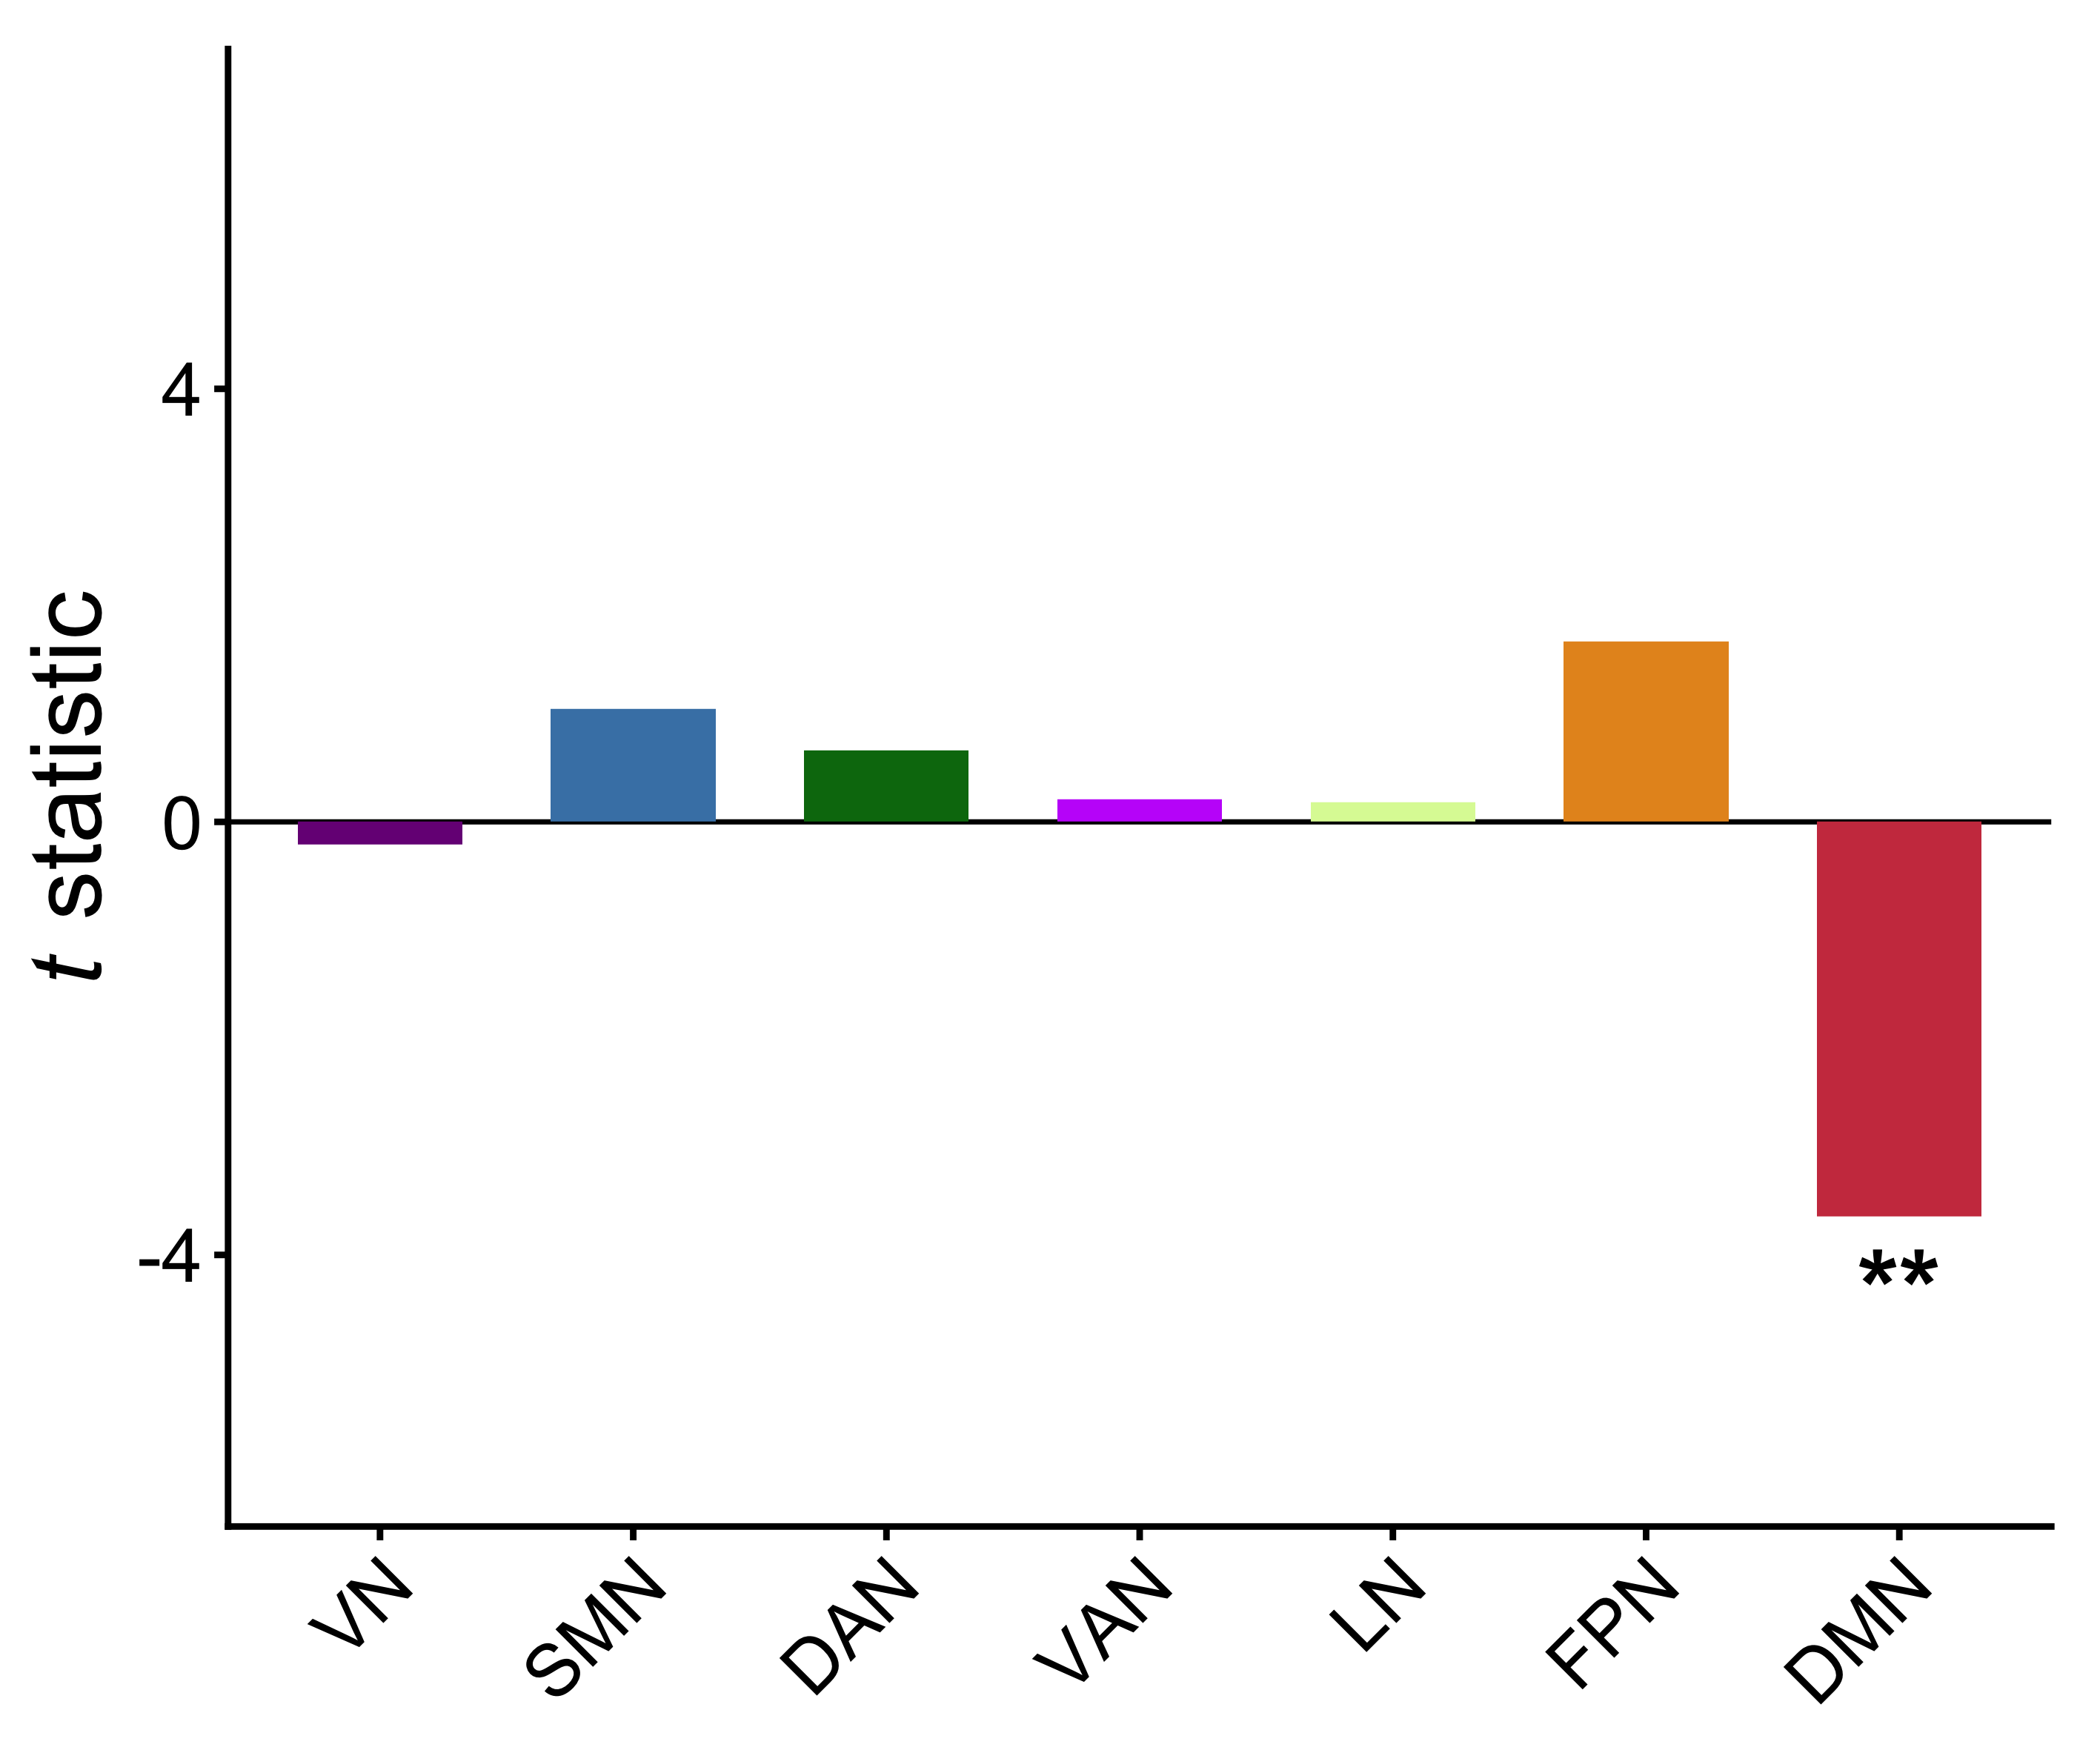

Beijing_PKUGE_positive_gt3p29_cluster3_n33_mask.func_FunSurfWCF_network_tstat_bar.png


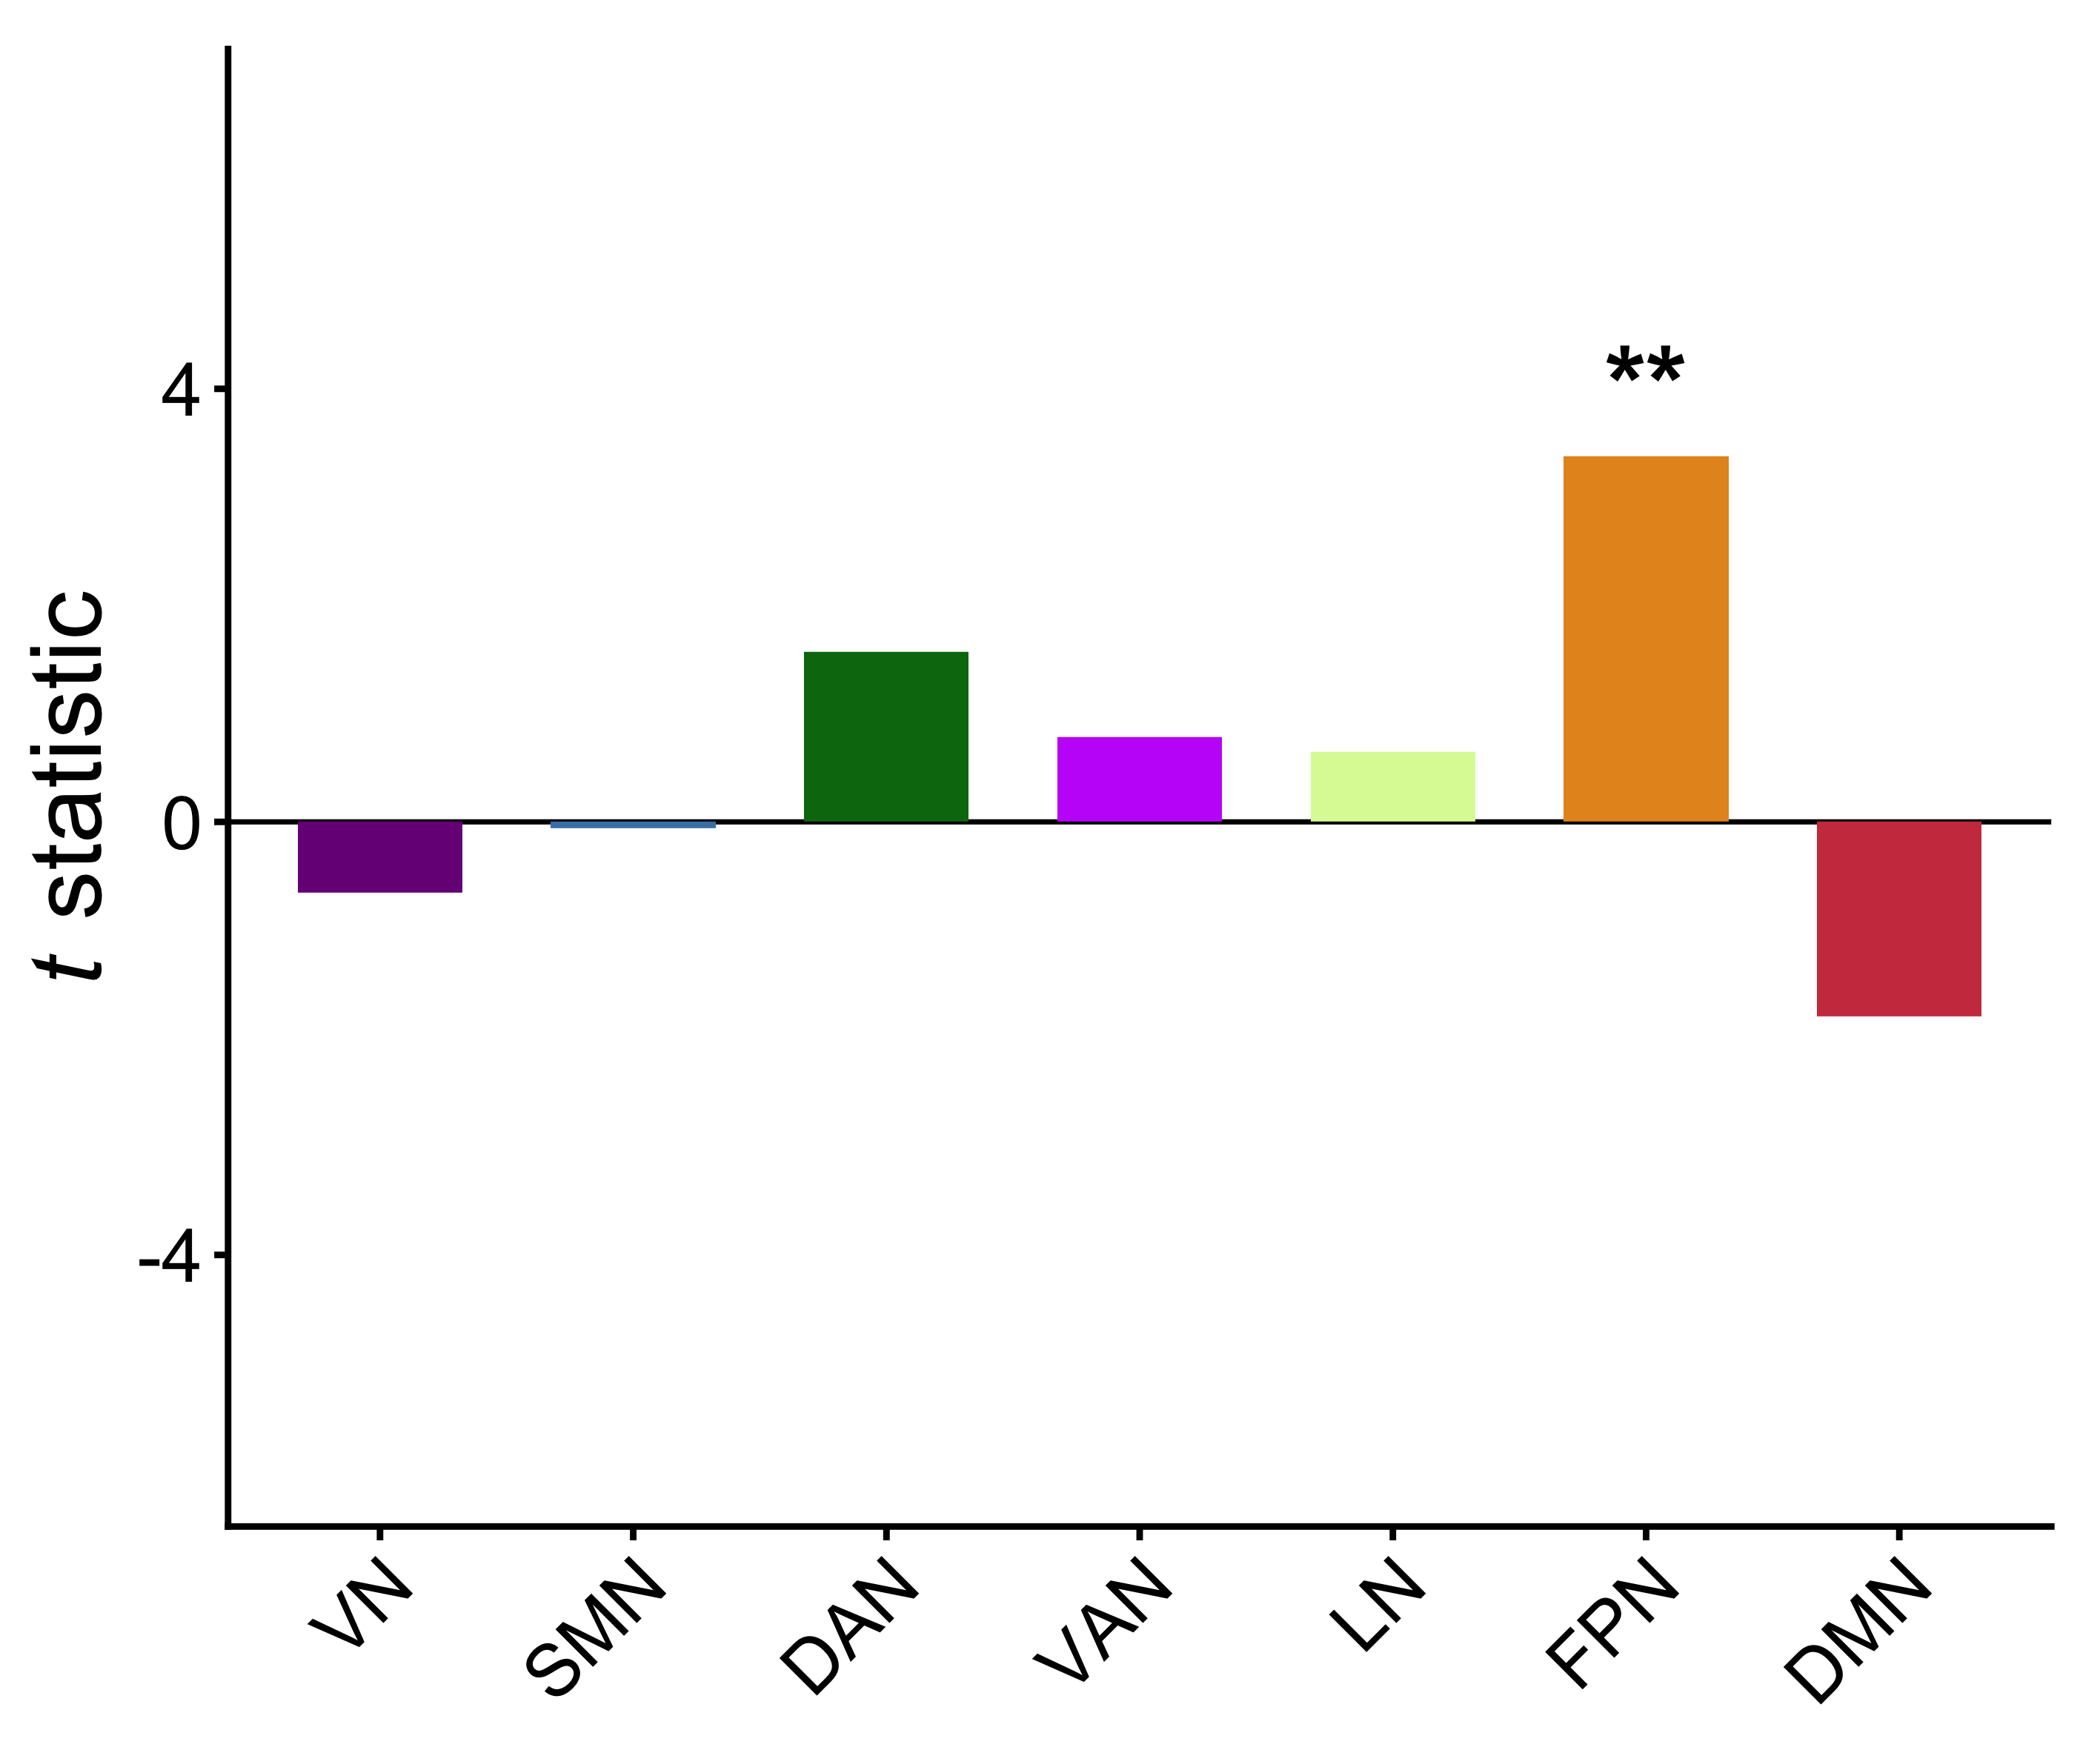

Beijing_PKUGE_positive_gt3p29_cluster3_n33_mask.func_FunSurfWglobalCF_network_tstat_bar.png


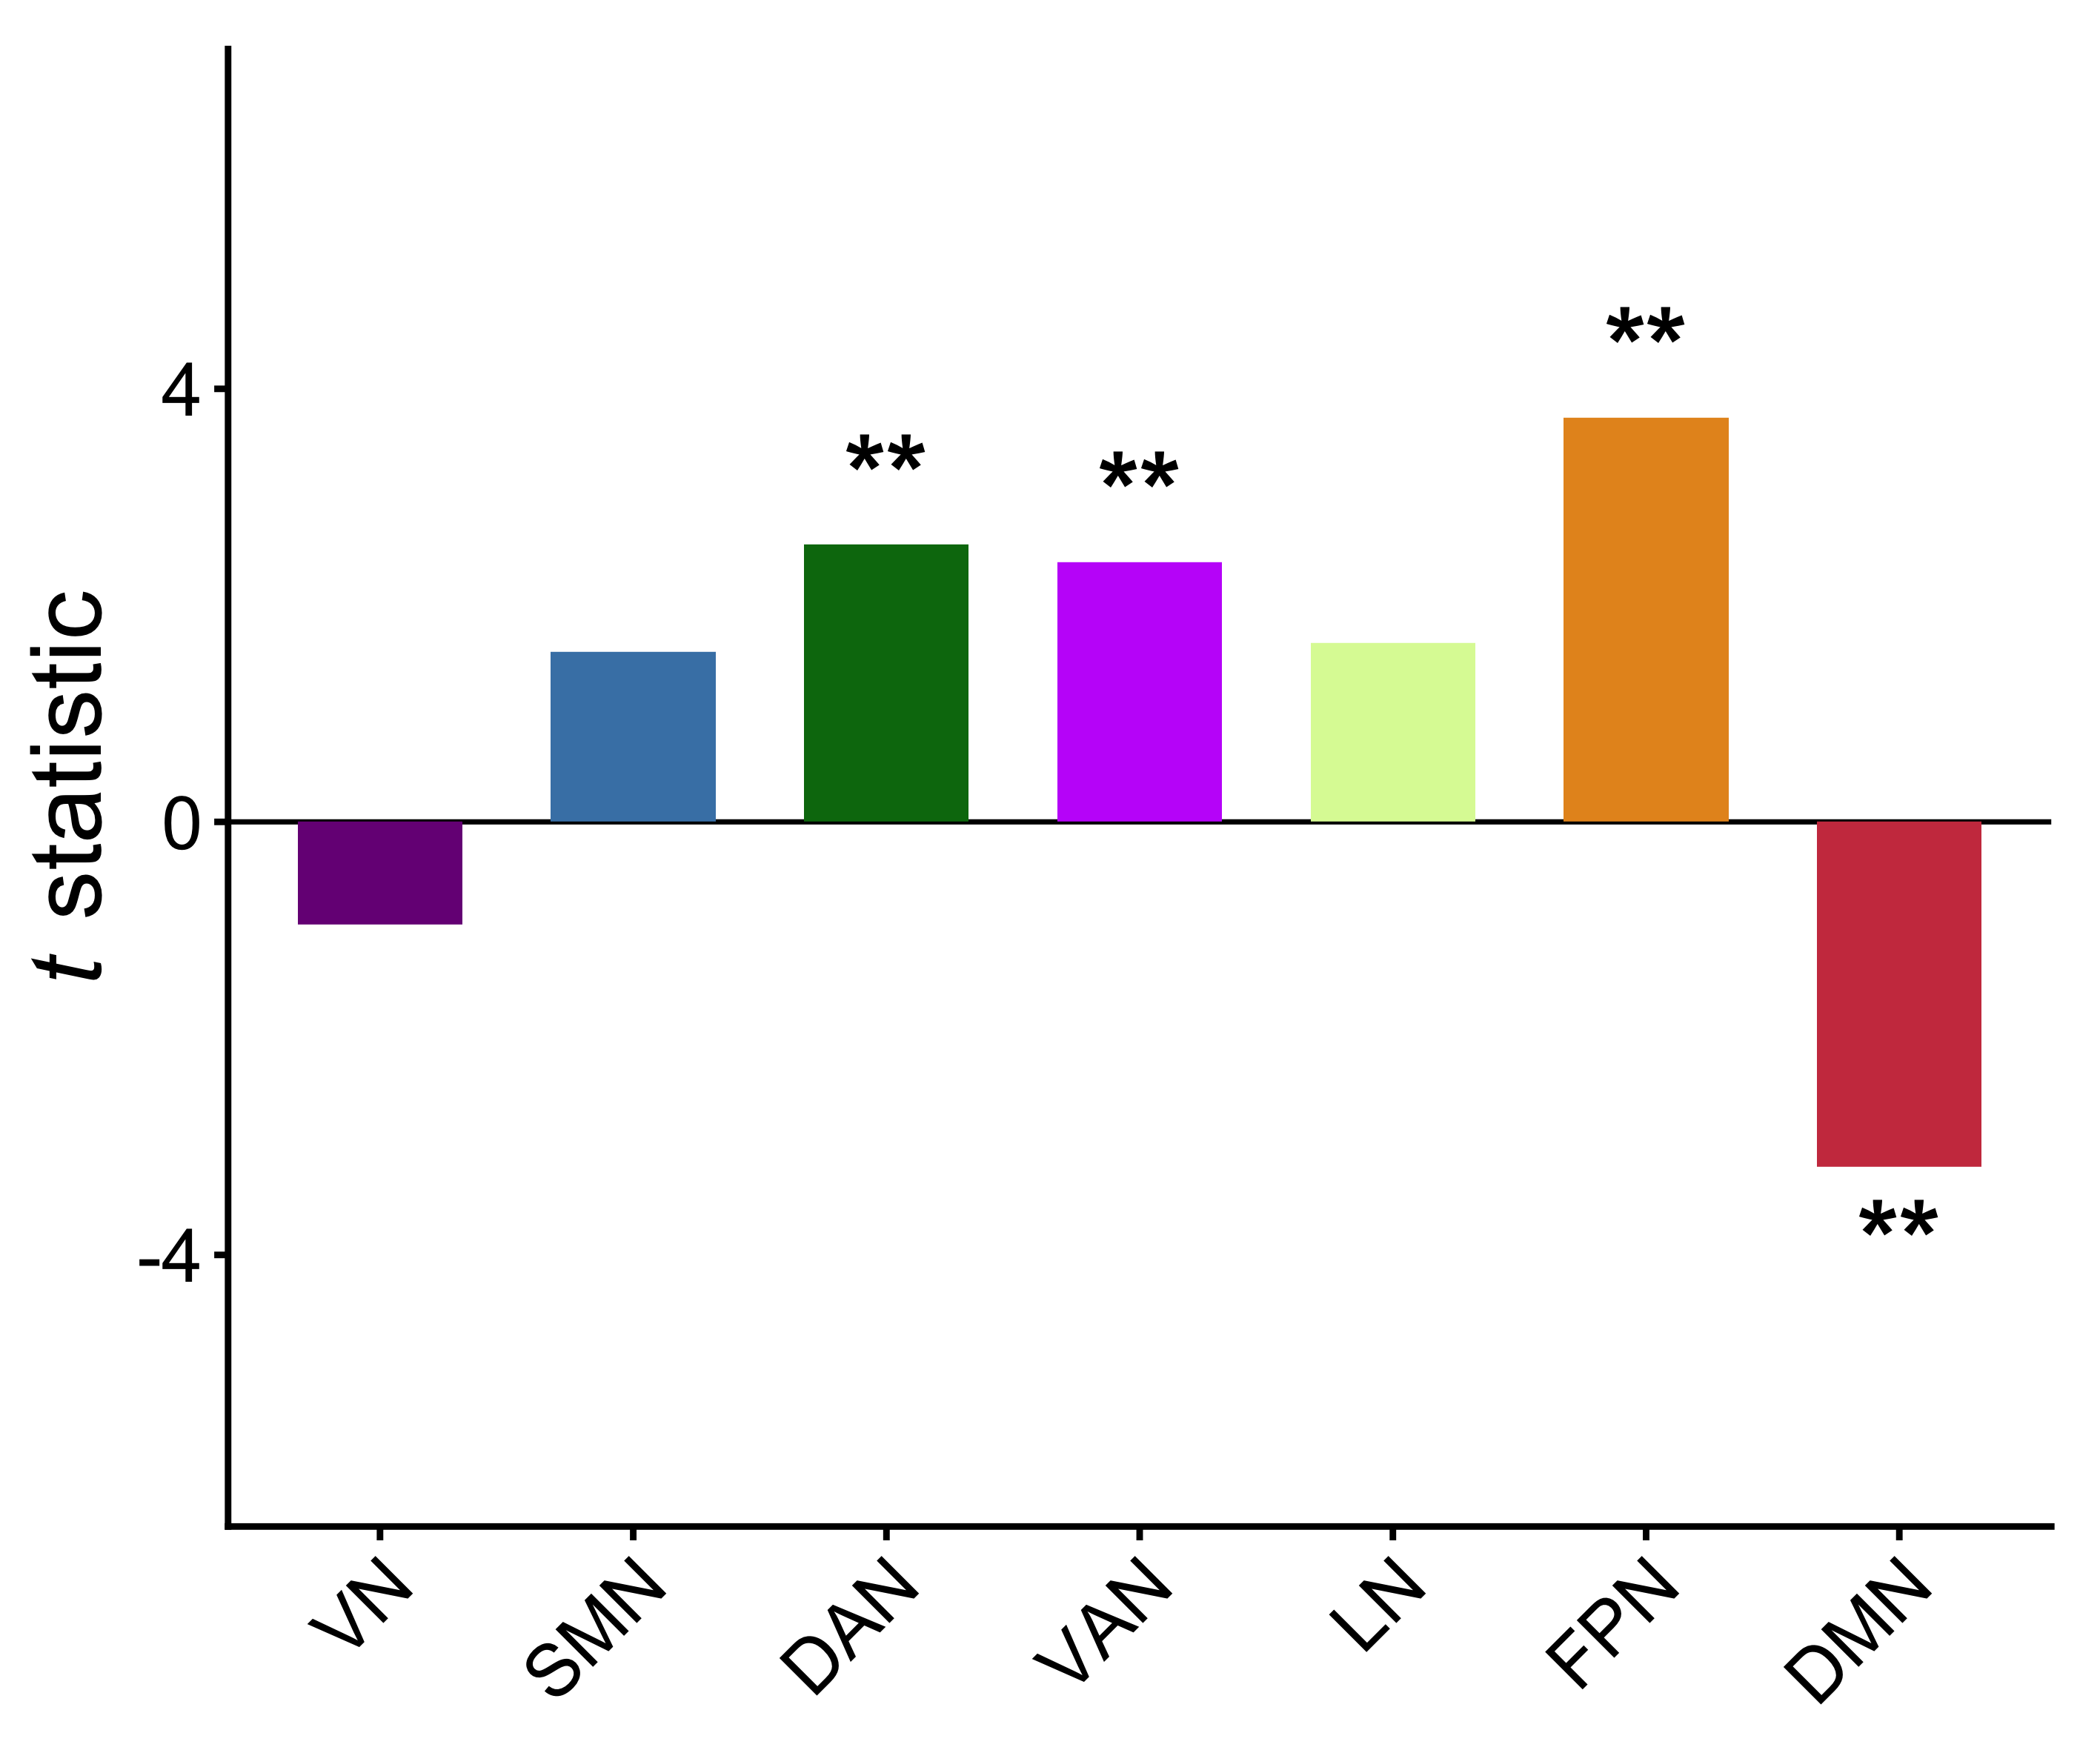

Beijing_PKUSIEMENS_positive_gt3p29_cluster1_n69_mask.func_FunSurfWCF_network_tstat_bar.png


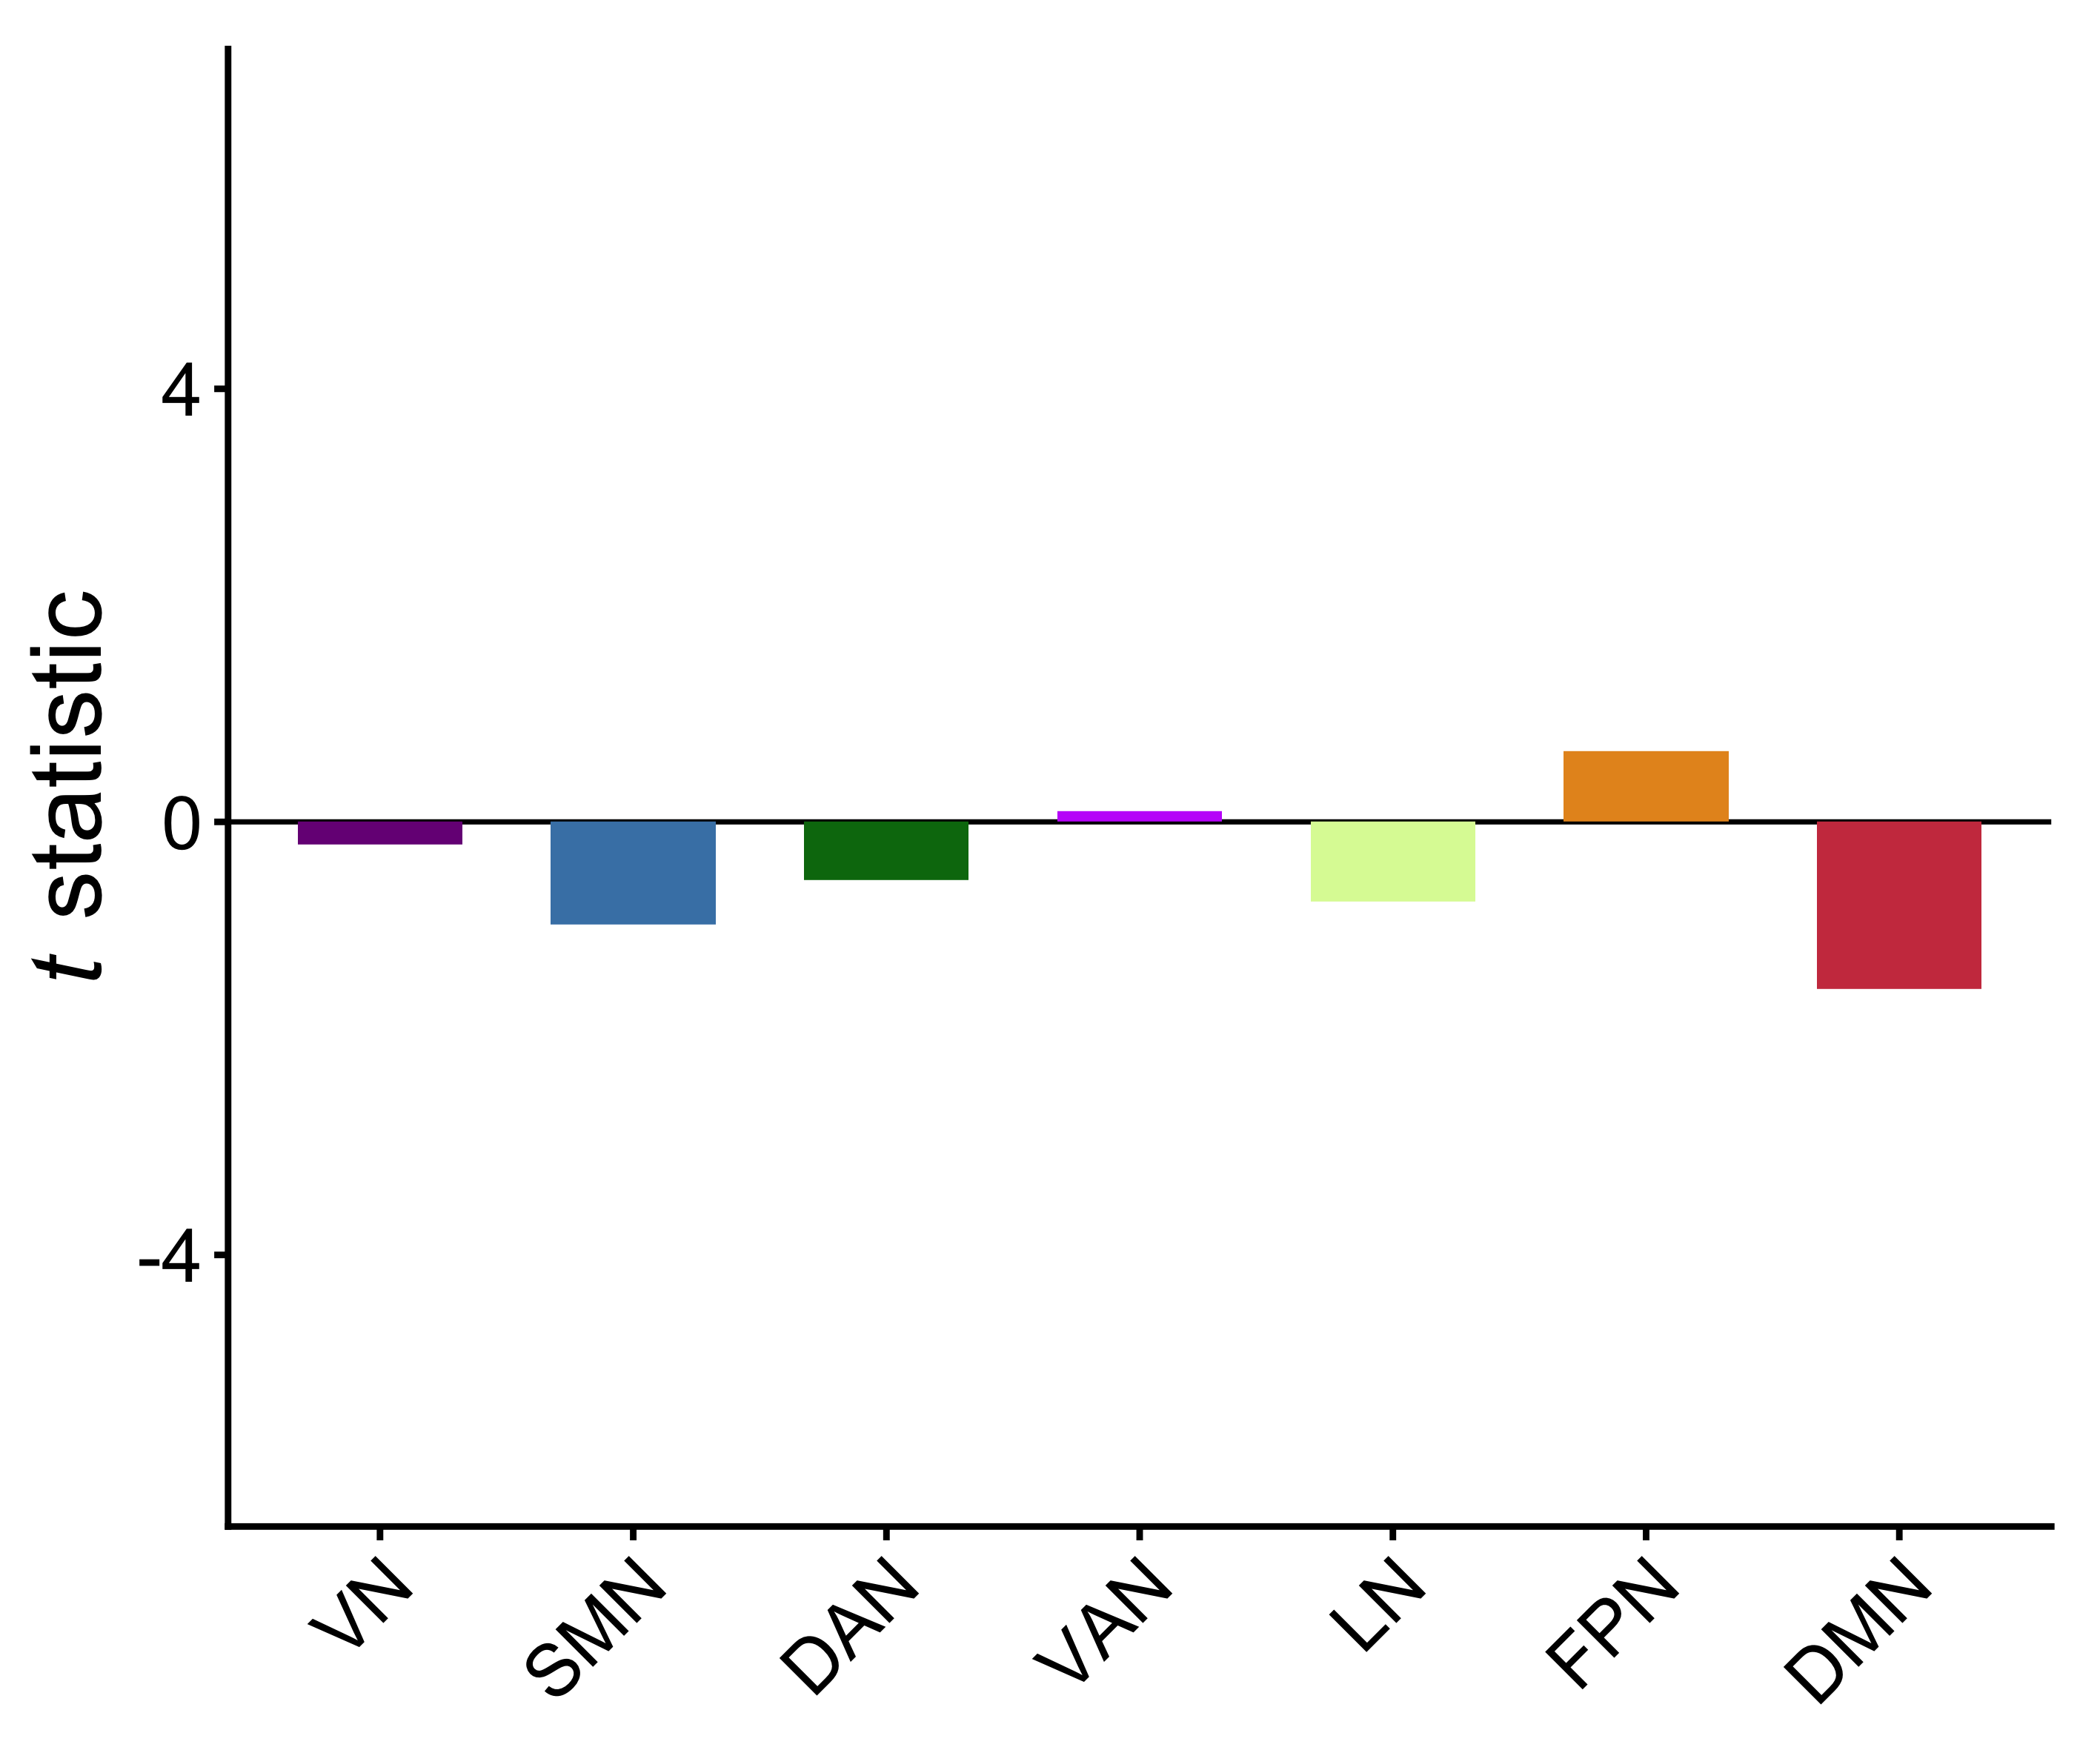

Beijing_PKUSIEMENS_positive_gt3p29_cluster1_n69_mask.func_FunSurfWglobalCF_network_tstat_bar.png


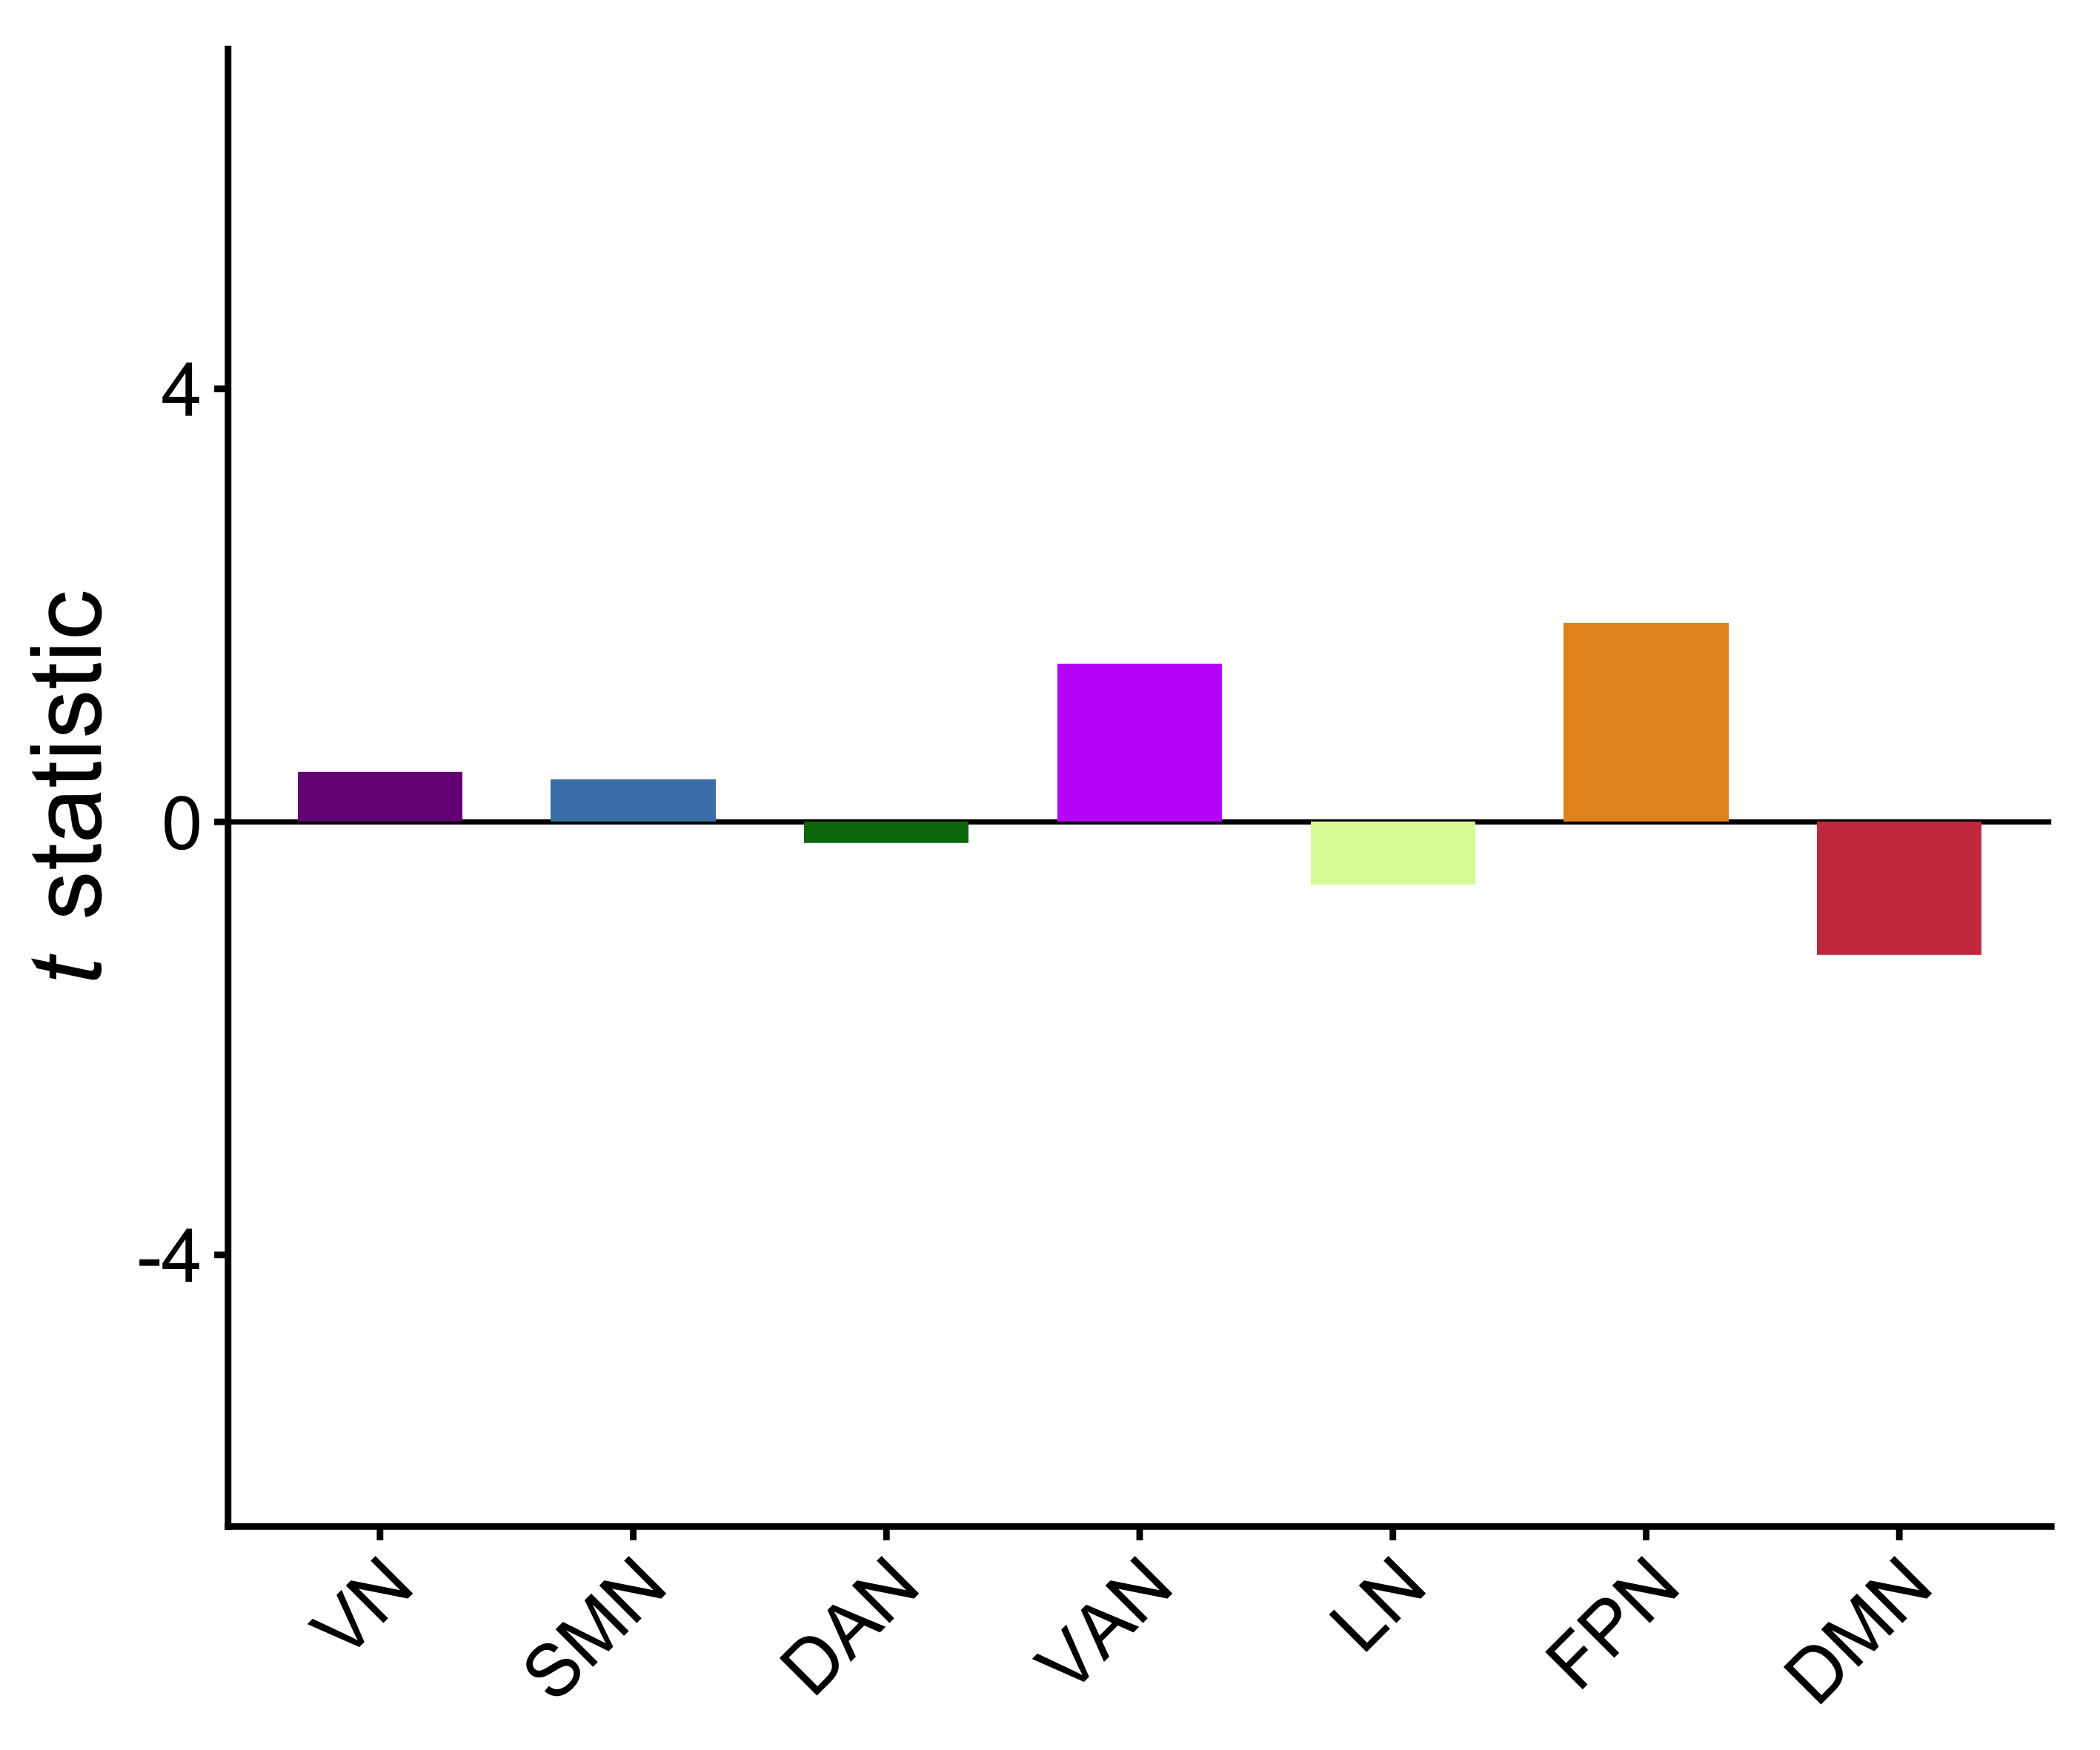

Beijing_PKUSIEMENS_positive_gt3p29_cluster2_n50_mask.func_FunSurfWCF_network_tstat_bar.png


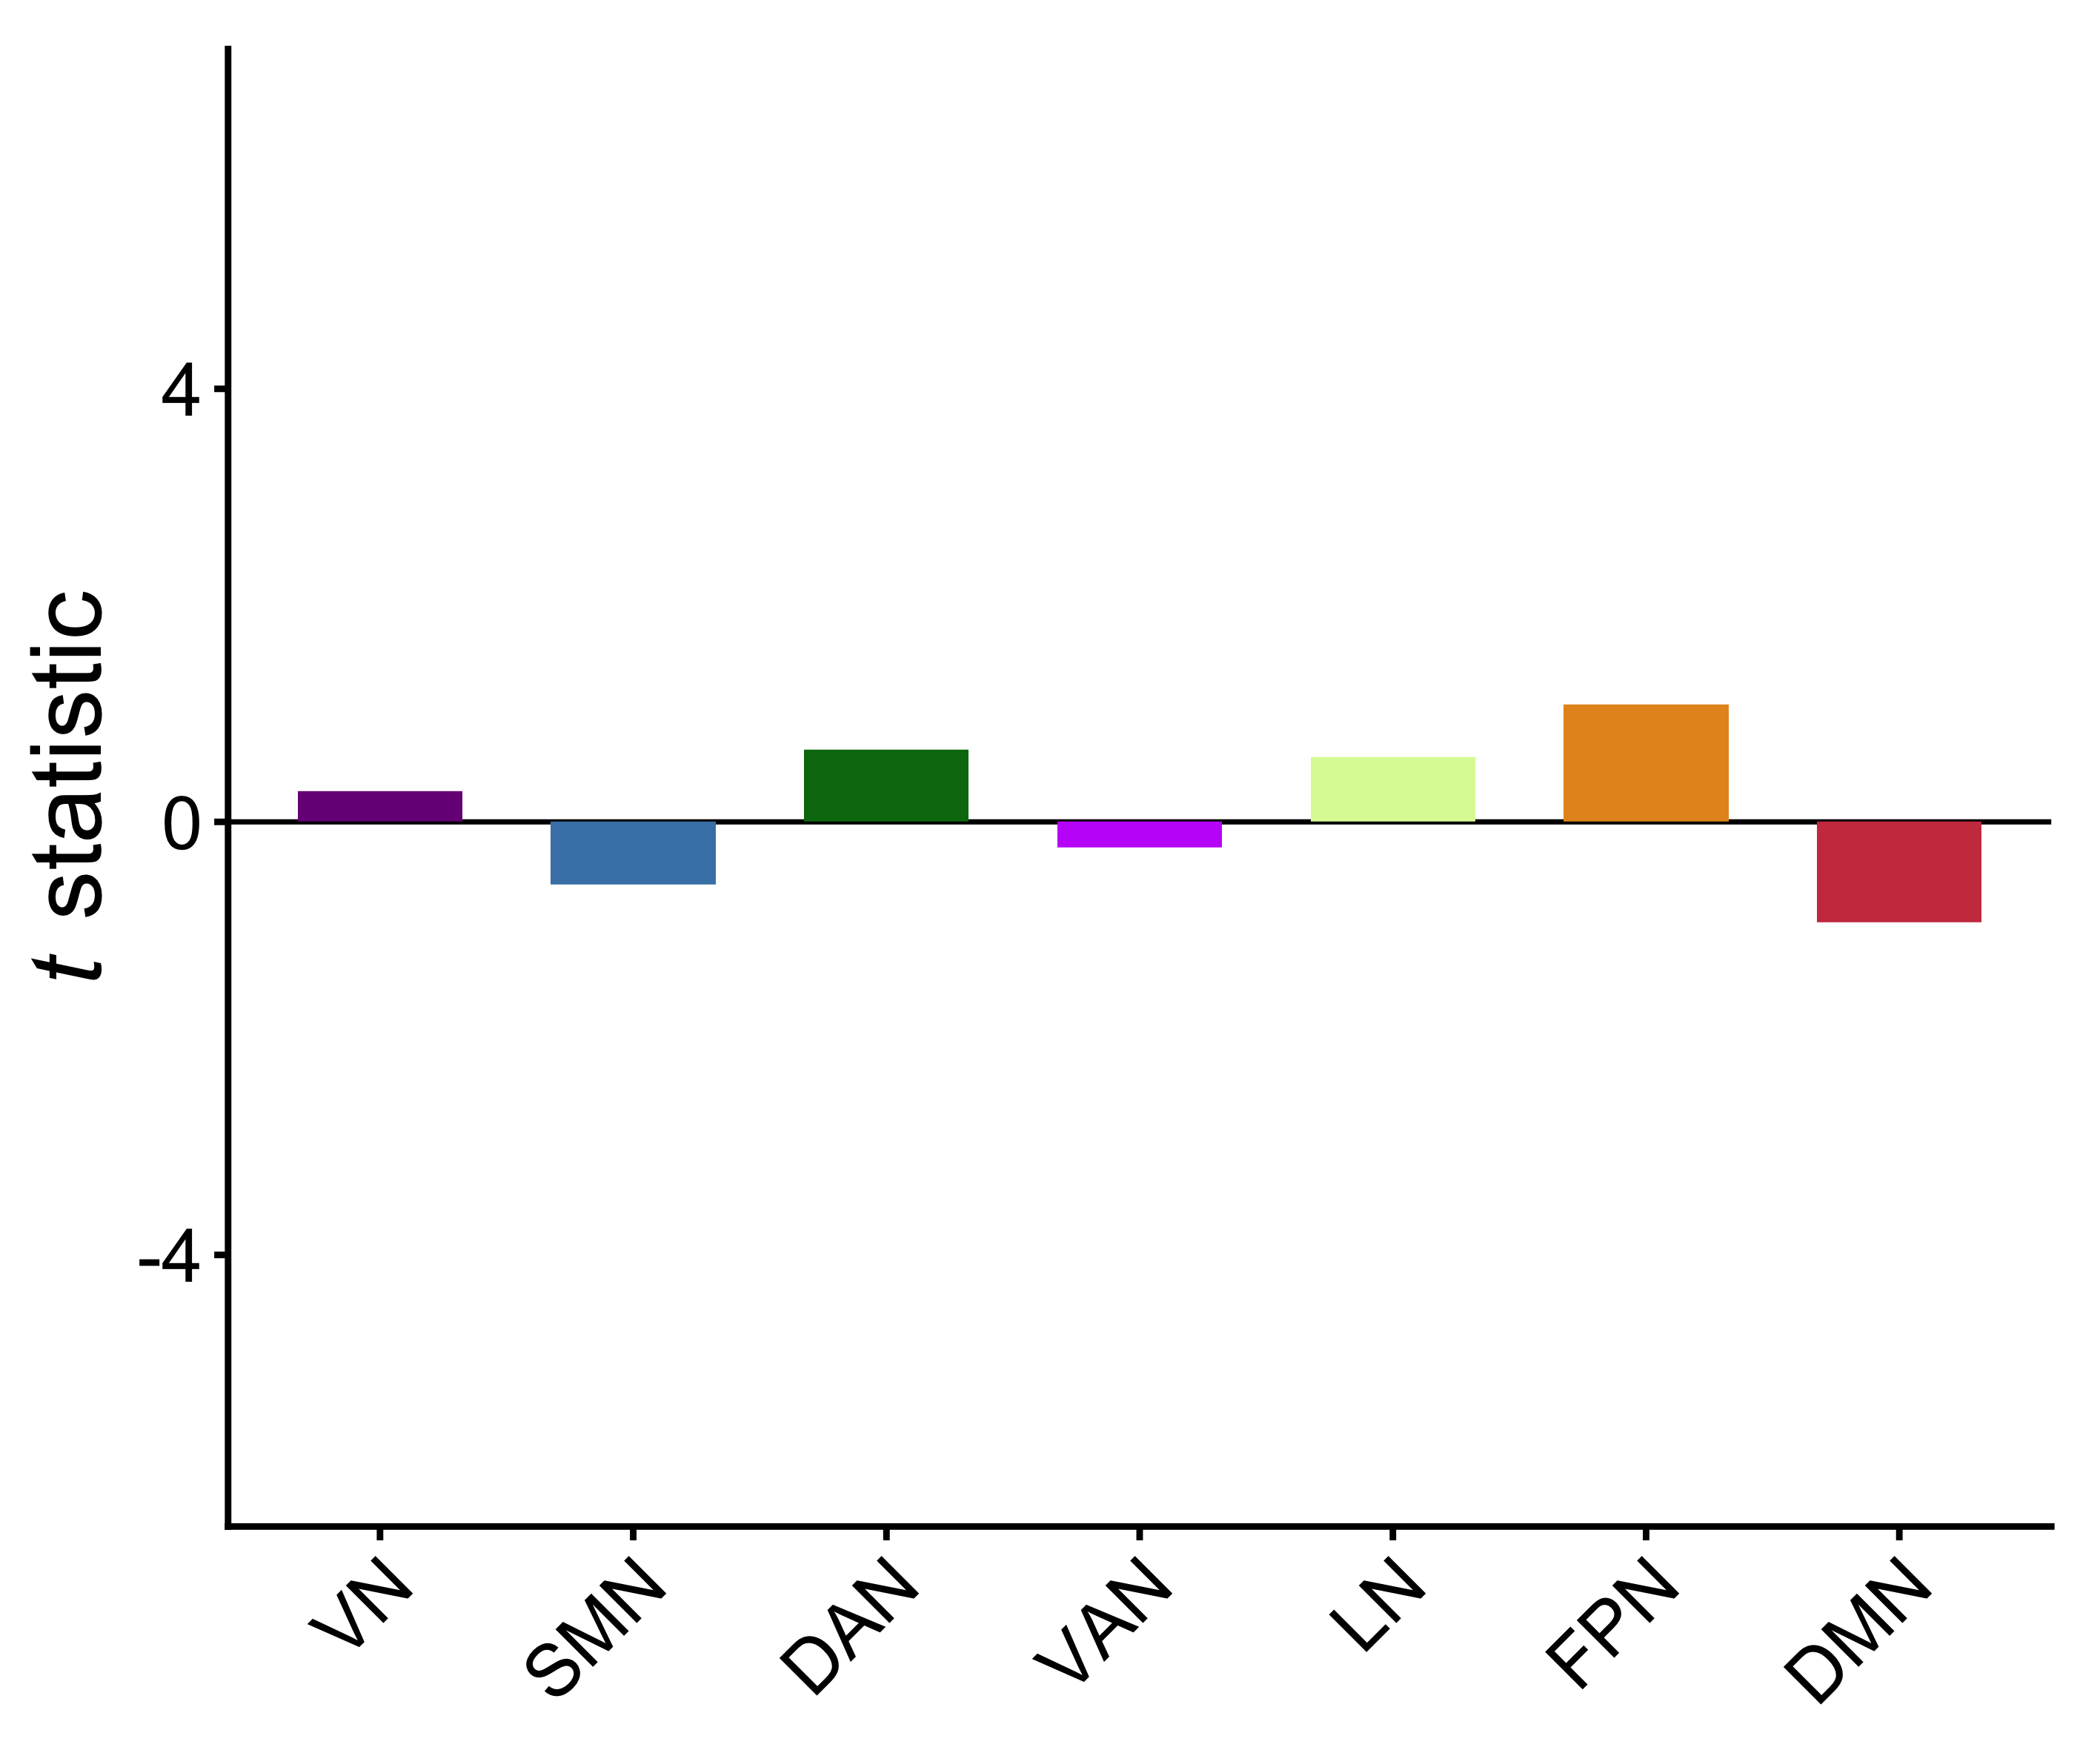

Beijing_PKUSIEMENS_positive_gt3p29_cluster2_n50_mask.func_FunSurfWglobalCF_network_tstat_bar.png


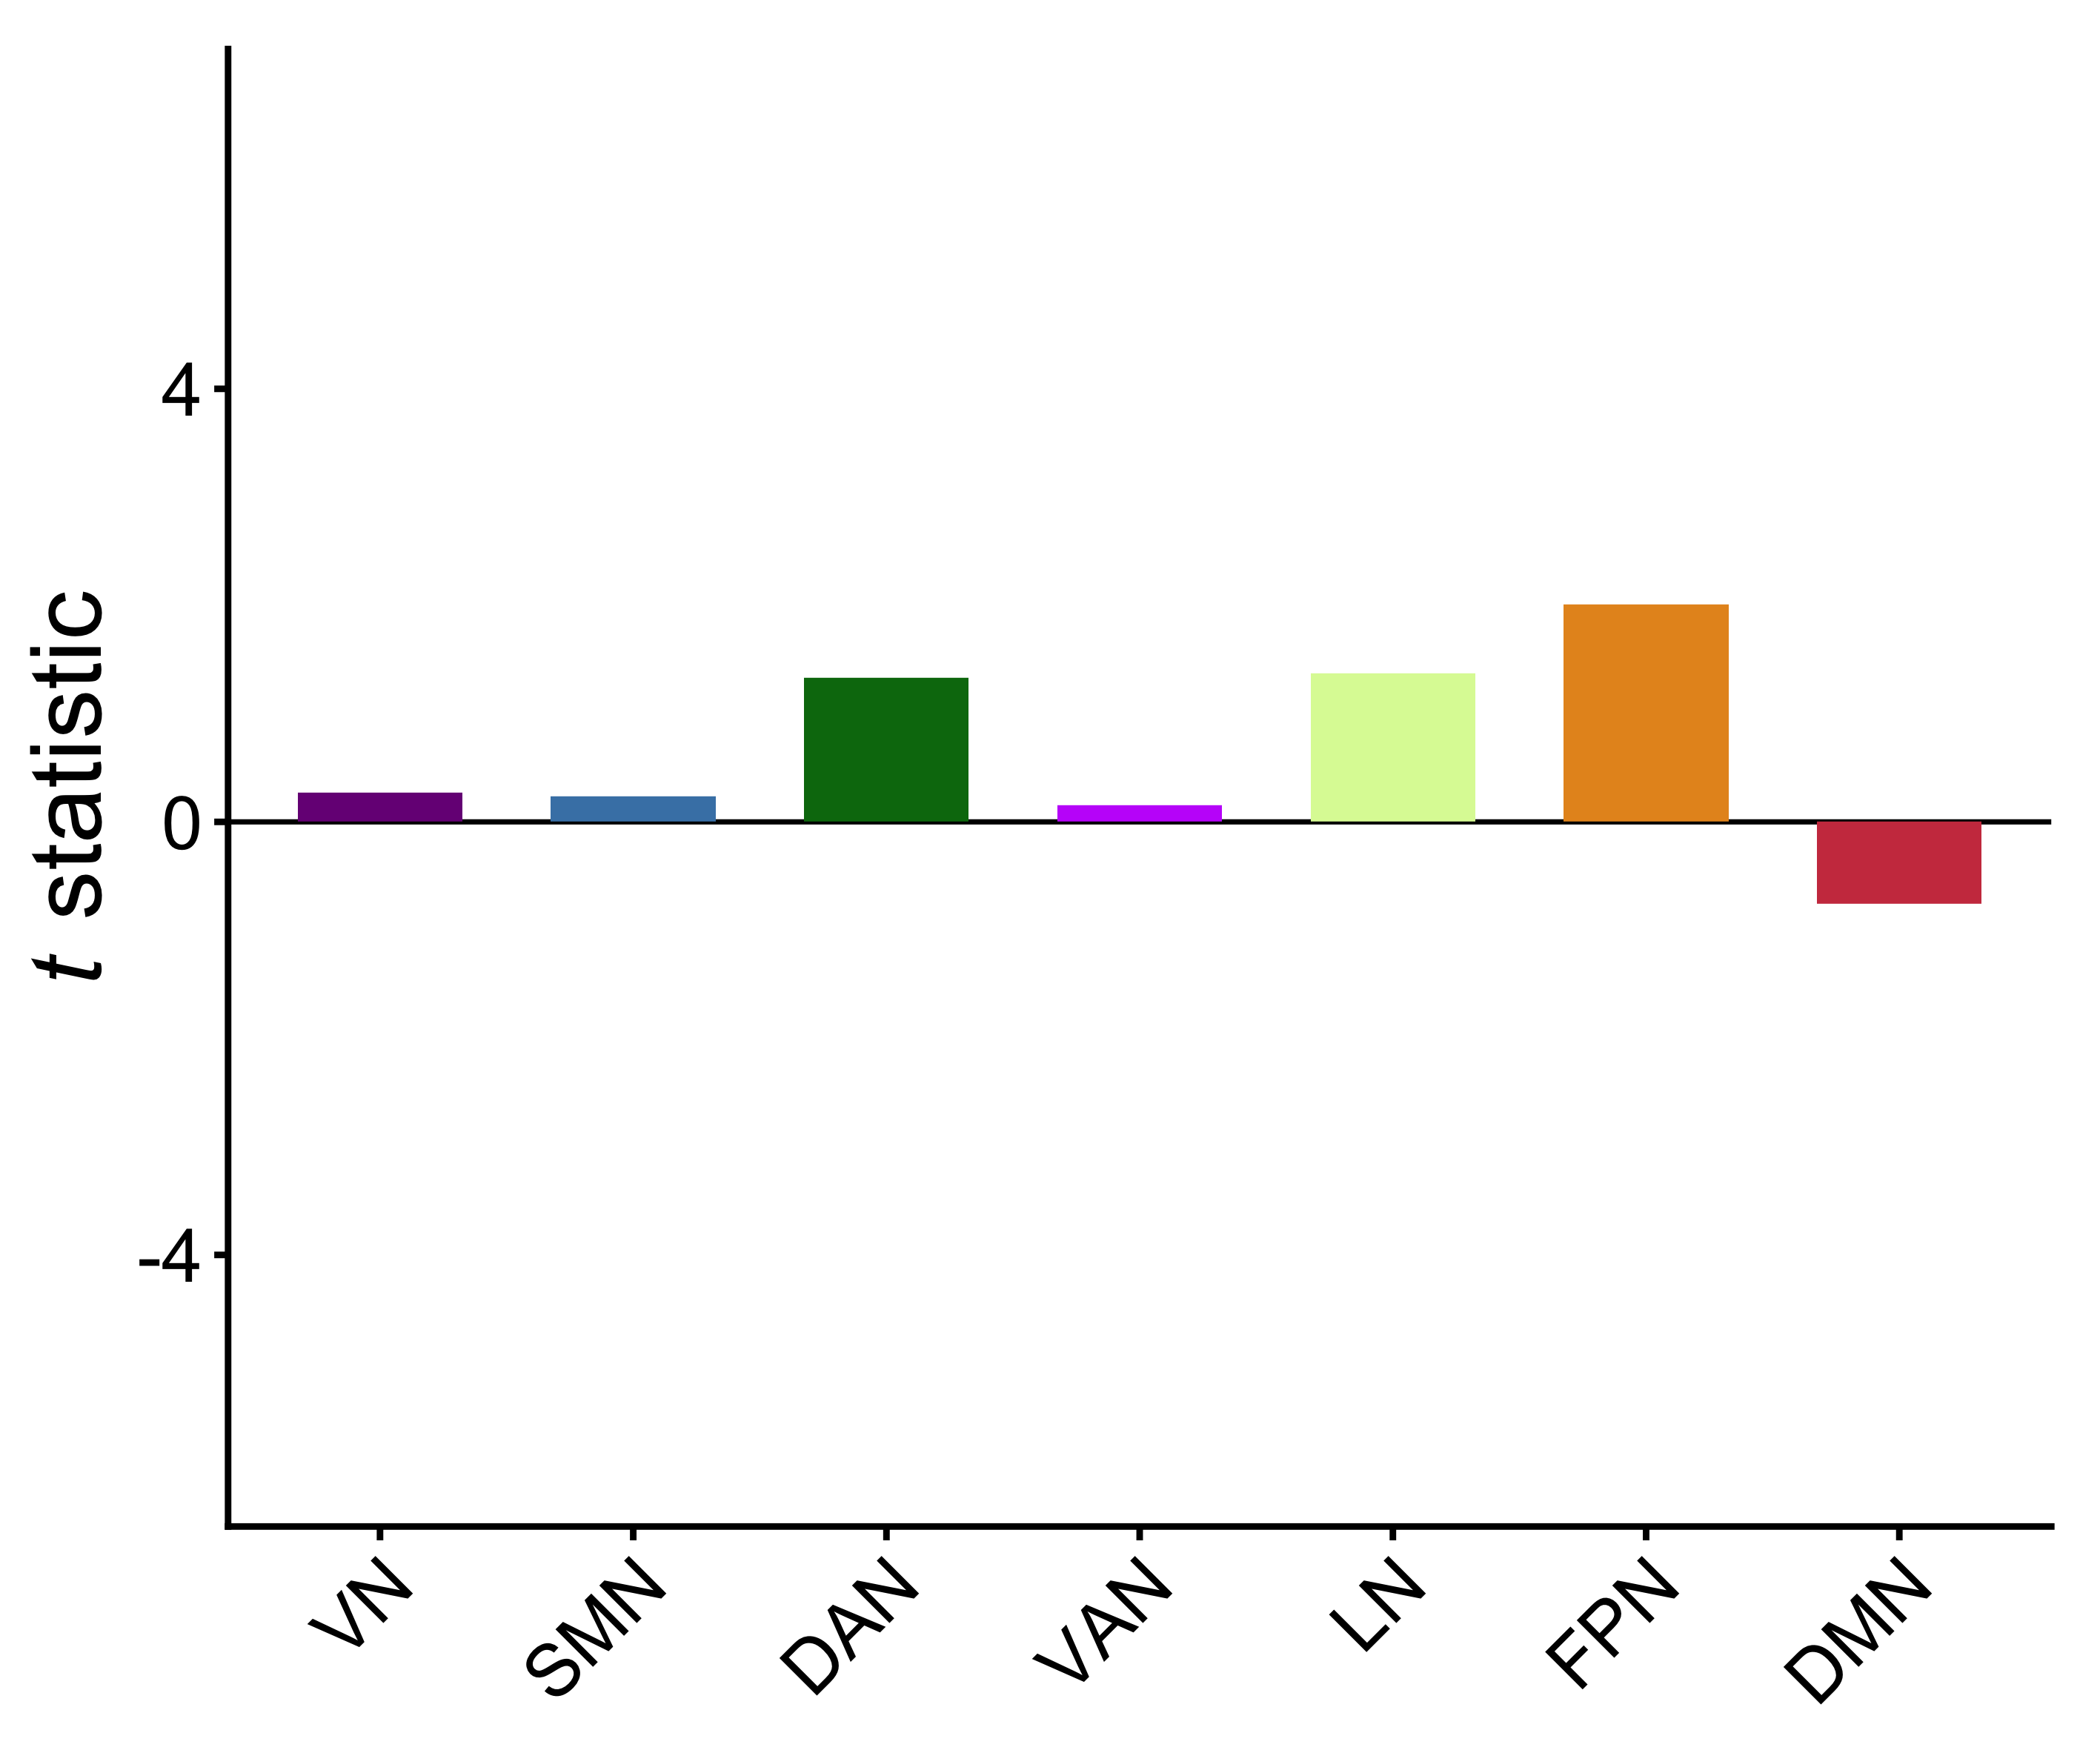

Beijing_PKUSIEMENS_positive_gt3p29_cluster3_n33_mask.func_FunSurfWCF_network_tstat_bar.png


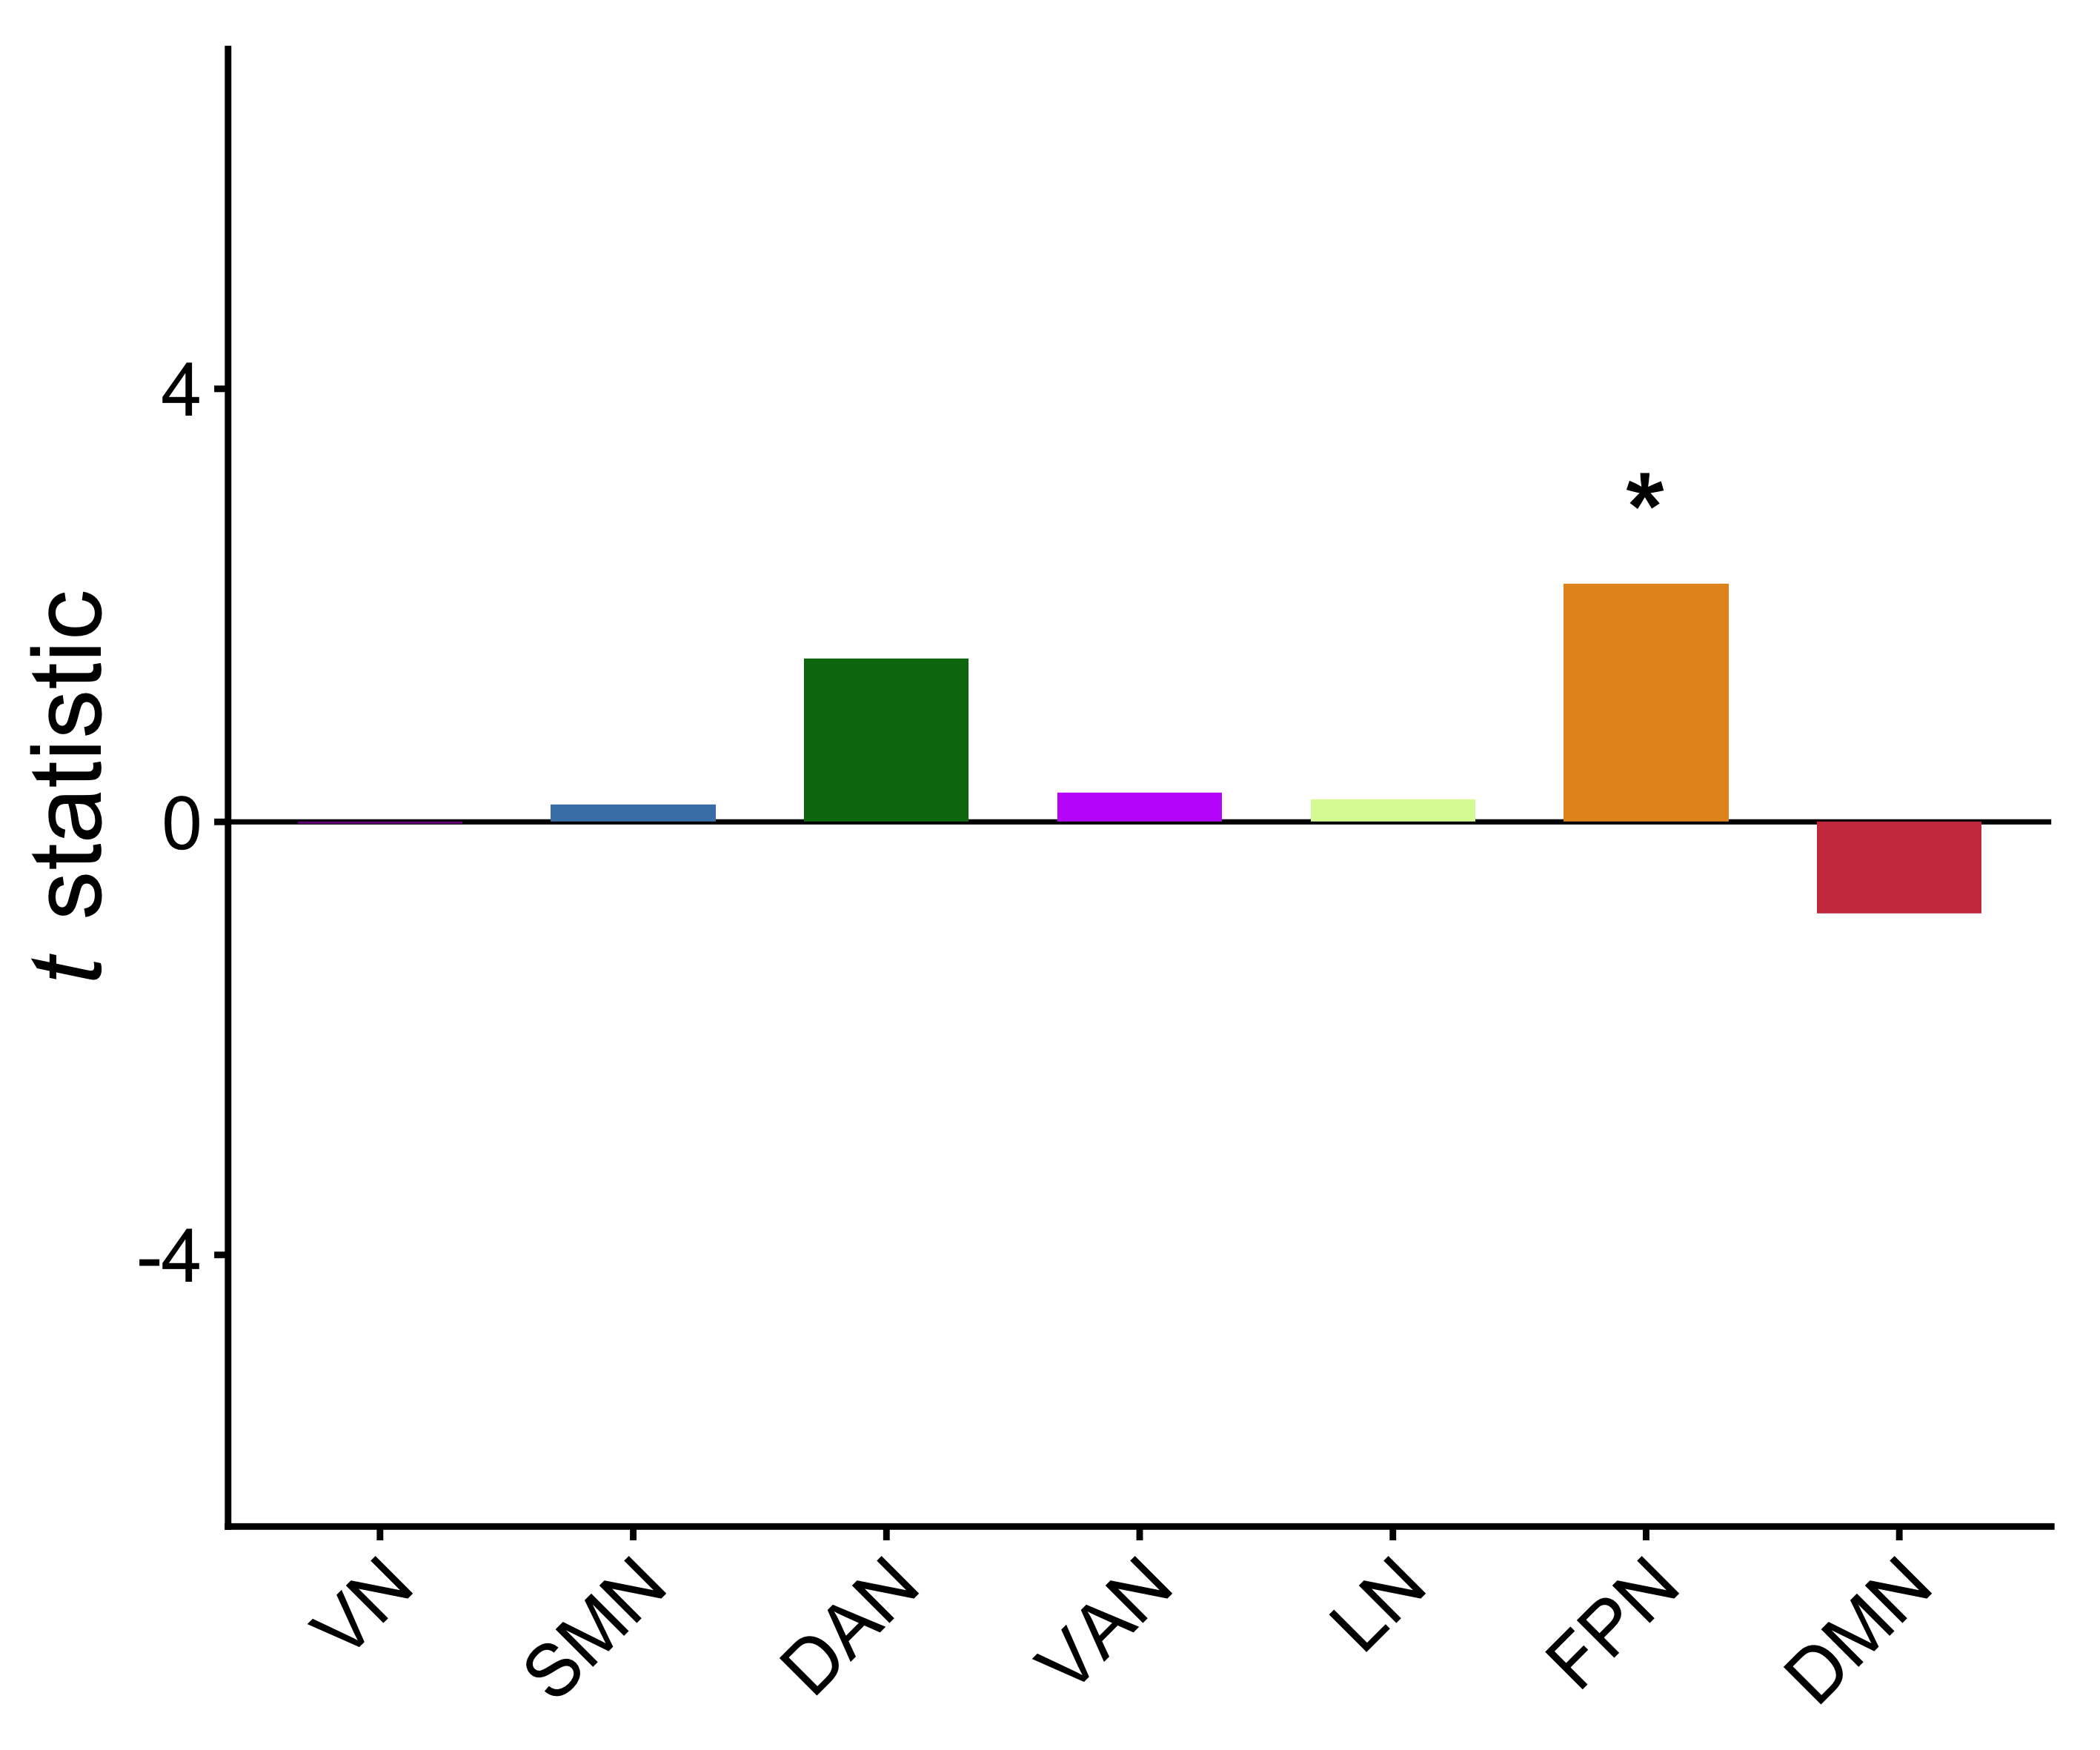

Beijing_PKUSIEMENS_positive_gt3p29_cluster3_n33_mask.func_FunSurfWglobalCF_network_tstat_bar.png


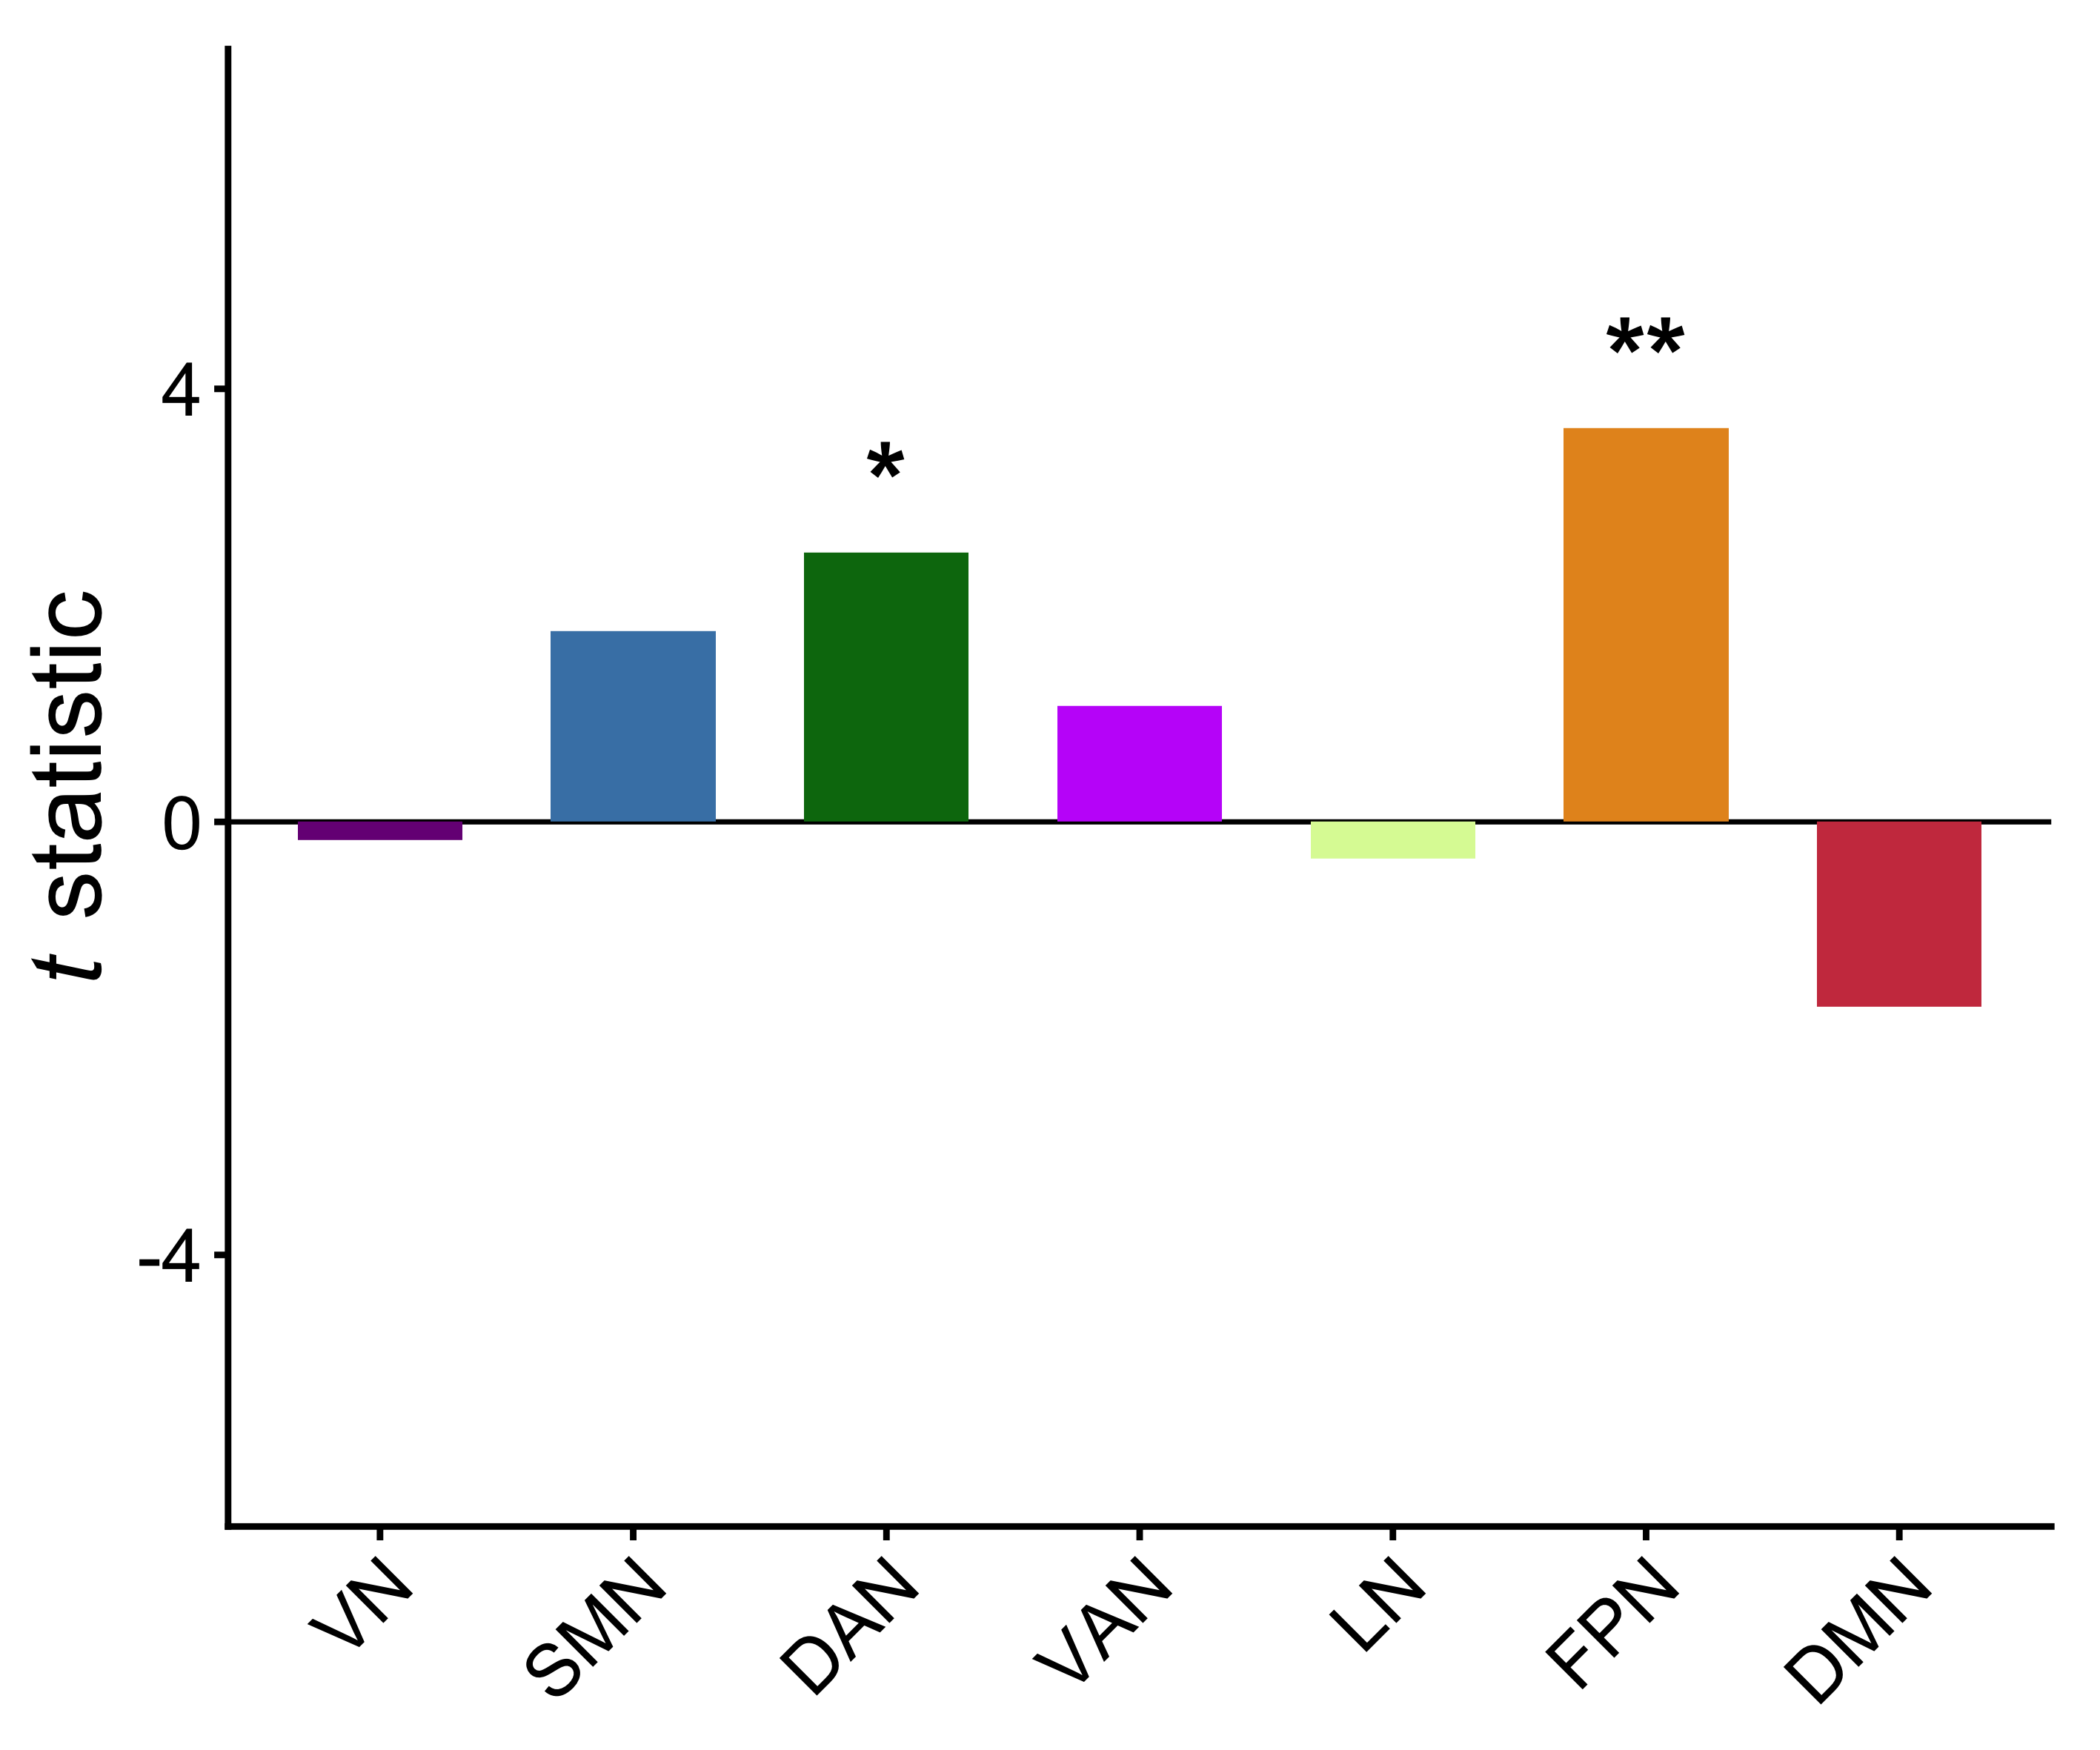

In [2]:
# Plot all Suzhou/Beijing ROI FC network statistics using the R utility.
# Use a separate R process to avoid loading embedded R through rpy2.
from pathlib import Path
import shutil
import subprocess
from IPython.display import Image, display

project_dir = Path("/Users/Chenxiao/Documents/project_codes/rumination_casual_mapping")
out_dir = project_dir / "analyses/stable_260725/plots"
rscript = shutil.which("Rscript")
if rscript is None:
    raise FileNotFoundError("Rscript is required to call roi_FC_network_bar.")

r_code = r'''
project_dir <- commandArgs(trailingOnly = TRUE)[1]
source(file.path(project_dir, "scripts/plot_utilities.R"))
out_dir <- file.path(project_dir, "analyses/stable_260725/plots")

# Each network has its own colour; names map colours regardless of row order.
network_colors <- c(
  Vis = "#781286", SomMot = "#4682B4", DorsAttn = "#00760E",
  SalVentAttn = "#C43AFA", Limbic = "#DCF8A4",
  Cont = "#E69422", Default = "#CD3E4E"
)
# Display labels in the same order as the original seven networks.
network_labels <- c(
  Vis = "VN", SomMot = "SMN", DorsAttn = "DAN",
  SalVentAttn = "VAN", Limbic = "LN", Cont = "FPN", Default = "DMN"
)
# Font sizes in points; figure dimensions in mm.
x_tick_label_size <- 12
y_tick_label_size <- 12
x_axis_label_size <- 16
y_axis_label_size <- 16
x_axis_label <- NULL
y_axis_label <- expression(italic(t) * " statistic")
figure_width <- 120
figure_height <- 100
figure_dpi <- 600

# Validate both datasets before exporting any plots.
plot_jobs <- list()
for (dataset in c("Suzhou", "Beijing")) {
  stats_file <- file.path(project_dir, "analyses/stable_260725/FC_analyses",
                          dataset, "network_stats",
                          paste0(dataset, "_network_paired_t_headmotion.csv"))
  stats <- read.csv(stats_file, stringsAsFactors = FALSE)
  group_column <- if (dataset == "Suzhou") "group" else "site"
  required <- c(group_column, "analysis", "network", "t", "p", "p_fdr_7networks")
  if (!all(required %in% names(stats)) || nrow(stats) == 0L) {
    stop(paste("Missing required columns or empty statistics:", stats_file))
  }
  if (anyNA(stats[, c(group_column, "analysis", "network")]) ||
      any(!is.finite(stats$t))) {
    stop(paste("Missing identifiers or nonfinite t statistics:", stats_file))
  }
  combinations <- unique(stats[, c(group_column, "analysis")])
  for (i in seq_len(nrow(combinations))) {
    group_name <- combinations[[group_column]][i]
    analysis_name <- combinations$analysis[i]
    df <- stats[stats[[group_column]] == group_name & stats$analysis == analysis_name, ]
    if (nrow(df) != 7L || anyDuplicated(df$network) ||
        !setequal(df$network, names(network_colors))) {
      stop(paste("Expected seven unique networks:", dataset, group_name, analysis_name))
    }
    plot_jobs[[length(plot_jobs) + 1L]] <- list(
      dataset = dataset, group = group_name, analysis = analysis_name, df = df
    )
  }
}
# Share a symmetric t-statistic scale across both datasets for comparison.
max_abs_t <- max(0.1, abs(unlist(lapply(plot_jobs, function(job) job$df$t))))
y_limits <- c(-max_abs_t, max_abs_t)
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
for (job in plot_jobs) {
  out_png <- file.path(out_dir, paste0(
    job$dataset, "_", job$group, "_", job$analysis, "_network_tstat_bar.png"
  ))
  # The plotting function marks FDR p < .05 as **; otherwise raw p < .05 as *.
  # FDR values are read from p_fdr_7networks, not recalculated across plots.
  plot_df <- job$df
  plot_df$network <- unname(network_labels[plot_df$network])
  roi_FC_network_bar(
    df = plot_df, out_file = out_png,
    bar_color = setNames(network_colors, unname(network_labels[names(network_colors)])),
    network_order = unname(network_labels),
    title = NULL, xlab = x_axis_label, ylab = y_axis_label,
    x_tick_label_size = x_tick_label_size, y_tick_label_size = y_tick_label_size,
    x_axis_label_size = x_axis_label_size, y_axis_label_size = y_axis_label_size,
    width = figure_width, height = figure_height, dpi = figure_dpi,
    y_limits = y_limits
  )
  cat("SAVED_PLOT:", out_png, "\n", sep = "")
}
'''

result = subprocess.run(
    [rscript, "--vanilla", "-", str(project_dir)],
    input=r_code, text=True, capture_output=True,
)
if result.returncode != 0:
    raise RuntimeError(f"Network plotting failed:\n{result.stderr}\n{result.stdout}")
plot_files = [
    Path(line.removeprefix("SAVED_PLOT:"))
    for line in result.stdout.splitlines() if line.startswith("SAVED_PLOT:")
]
if not plot_files or not all(path.is_file() for path in plot_files):
    raise RuntimeError("No plots were exported, or an output file is missing.")
print(f"Saved {len(plot_files)} network bar plots to {out_dir}")
for path in plot_files:
    print(path.name)
    display(Image(filename=str(path), width=600))
